# Airbnb London: Hedonic Pricing and Machine Learning Benchmark

### Research question

> Which listing, host, and location attributes are associated with the nightly asking
> prices of Airbnb listings in London, and can machine learning methods predict those
> prices more accurately than hedonic regression?

The design is deliberately dual. Part 1 is explanatory: a hedonic regression whose
coefficients carry a ceteris-paribus interpretation, holding the other measured
attributes constant. Part 2 is predictive: machine learning models judged purely on
out-of-sample accuracy. The two answer different questions and neither supersedes the
other.

### Hypotheses

| # | Hypothesis | Expected sign |
|---|---|---|
| H1 | Capacity and property attributes (accommodates, bathrooms, amenities, entire home) are positively associated with price | + |
| H2 | Distance from the centre is negatively associated with price; proximity to transport positively | − / + |
| H3 | Reputation is mixed: superhost status and review scores positively associated with price, review volume negatively | +/− |
| H4 | Tree-based models achieve lower out-of-sample RMSE than OLS, while OLS remains interpretable | + |

The data are cross-sectional and observational, so every estimate below is an
**association** conditional on the controls in the model, not a causal effect. Unobserved
listing quality — interior condition, view, photography — is absorbed into the error term
and cannot be separated from the measured attributes.

### Contents

| Section | Content |
|---|---|
| 1 | Data loading, provenance, and availability audit |
| 2 | Cleaning and sample construction |
| 3 | Feature engineering |
| 4 | Exploratory analysis |
| 5 | Hedonic regression |
| 6 | Diagnostics |
| 7 | Robustness checks |
| 8 | Predictive modelling |
| 9 | Summary and exports |

### Notes on the data

Two decisions are worth stating up front, since both affect how the results should be
read.

**City centre reference point.** Distance is measured to Charing Cross at
(51.5074, −0.1278), the conventional centroid for London studies. Section 3 verifies that
the listings nearest this point fall in Westminster and Camden, confirming the coordinate
behaves as intended.

**Empty columns.** This snapshot publishes `host_since` and `instant_bookable` as columns
but populates neither. Host tenure is recovered from `hosts_time_as_host_years` and
`hosts_time_as_host_months` instead; instant booking cannot be recovered and is excluded.
The availability audit in Section 1 reports this explicitly rather than letting an empty
column pass silently into the model.

---
## 0. Setup

In [1]:
# Dependencies, display settings and the random seed used throughout.
import ast
import json
import re
import warnings
from datetime import datetime
from math import radians, sin, cos, asin, sqrt
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from statsmodels.stats.diagnostic import het_breuschpagan

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Fall back to sklearn's booster if XGBoost is not installed.
try:
    from xgboost import XGBRegressor
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False

warnings.filterwarnings("ignore")

# Fixed seed so every split, fold and tree-based fit is reproducible.
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Bounded worker pool: n_jobs=-1 spawns one process per core and exhausts the
# Windows socket pool, which kills the kernel mid-run.
N_JOBS = 4

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["figure.autolayout"] = True

print("Environment ready.")
print(f"pandas {pd.__version__} | statsmodels {sm.__version__} | XGBoost available: {HAS_XGBOOST}")

Environment ready.
pandas 2.3.3 | statsmodels 0.14.6 | XGBoost available: True


In [2]:
# Paths are relative so the project folder can be moved without edits.
DATA_DIR = Path.cwd()
OUT_DIR = DATA_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)

NEIGHBOURHOODS_PATH = DATA_DIR / "neighbourhoods.csv"
CLEAN_PATH = DATA_DIR / "listings_clean.csv"
ENGINEERED_PATH = DATA_DIR / "listings_engineered.csv"

# Prefer the detailed extract, which carries the property, amenity and review columns.
for candidate in ["listings_detailed.csv", "listings.csv.gz", "listings_full.csv"]:
    if (DATA_DIR / candidate).exists():
        LISTINGS_PATH = DATA_DIR / candidate
        break
else:
    LISTINGS_PATH = DATA_DIR / "listings.csv"


def header(title):
    """Print a delimited banner so each block of output is unambiguous."""
    print("\n" + "=" * 82)
    print(title.upper())
    print("=" * 82)


header("data source")
print(f"File : {LISTINGS_PATH.name} ({LISTINGS_PATH.stat().st_size / 1024**2:,.1f} MB)")


DATA SOURCE
File : listings.csv.gz (48.0 MB)


---
## 1. Loading and inspection

Before any cleaning: the raw row count, the column types, and an audit of which variables
are actually usable. The audit matters because a column can exist in the header and still
be entirely empty.

In [3]:
# low_memory=False forces a full-column type scan; chunk inference otherwise
# produces inconsistent dtypes on mixed columns.
listings_raw = pd.read_csv(LISTINGS_PATH, low_memory=False)

header("raw file structure")
print(f"Rows    : {listings_raw.shape[0]:,}")
print(f"Columns : {listings_raw.shape[1]}")

print("\n--- Data types ---")
display(listings_raw.dtypes.to_frame("dtype"))

print("\n--- First 5 rows ---")
display(listings_raw.head())


RAW FILE STRUCTURE
Rows    : 92,638
Columns : 90

--- Data types ---


,dtype
id,int64
listing_url,object
scrape_id,int64
last_scraped,object
source,object
...,...
calculated_host_listings_count,int64
calculated_host_listings_count_entire_homes,int64
calculated_host_listings_count_private_rooms,int64
calculated_host_listings_count_shared_rooms,int64



--- First 5 rows ---


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,...,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,11551,https://www.airbnb.com/rooms/11551,20260619061251,2026-06-25,city scrape,Artistic London Pied-à-Terre,Live like a local in this quintessential Londo...,NaN,https://a0.muscache.com/pictures/prohost-api/H...,43039,https://www.airbnb.com/users/show/43039,"1,462,507,475,108,972,800.0000",https://www.airbnb.com/users/profile/146250747...,Adriano,NaN,16.0000,8.0000,15.0000,5.0000,"London, United Kingdom","Hello, I'm a friendly Italian man with a posit...",NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/pictures/user/User/...,NaN,1.0000,NaN,NaN,t,t,NaN,Lambeth,NaN,51.4609,-0.1176,Entire rental unit,Entire home/apt,...,234.5000,"{""quote"": {""taxes"": null, ""currency"": ""GBP"", ""...",1.0000,"1,125.0000",1.0000,5.0000,1.0000,"1,125.0000",2.0000,143.5000,NaN,t,9,25,55,330,2026-06-25,196,6,1,155,3,55,"12,898.0000",2010-03-21,2026-06-05,4.5500,4.6000,4.5700,4.7700,4.8400,4.5400,4.4900,NaN,NaN,1,1,0,0,0.9900
1,13913,https://www.airbnb.com/rooms/13913,20260619061251,2026-06-25,city scrape,Holiday London DB Room Let-on going,My bright double bedroom with a large window h...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,54730,https://www.airbnb.com/users/show/54730,"1,462,507,796,255,381,760.0000",https://www.airbnb.com/users/profile/146250779...,Alina,NaN,16.0000,7.0000,15.0000,5.0000,"London, United Kingdom",I am a Multi-Media Visual Artist and Creative ...,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/users/54730/profile...,NaN,2.0000,NaN,NaN,t,t,NaN,Islington,NaN,51.5686,-0.1127,Private room in rental unit,Private room,...,127.0000,"{""quote"": {""taxes"": null, ""currency"": ""GBP"", ""...",1.0000,29.0000,1.0000,1.0000,29.0000,29.0000,1.0000,29.0000,NaN,t,17,46,76,351,2026-06-25,57,3,0,176,6,28,"3,556.0000",2010-08-18,2026-03-31,4.8600,4.8000,4.8000,4.8200,4.8800,4.7900,4.7900,NaN,NaN,2,1,1,0,0.3000
2,15400,https://www.airbnb.com/rooms/15400,20260619061251,2026-06-26,city scrape,Bright Chelsea Apartment. Chelsea!,Lots of windows and light. St Luke's Gardens ...,NaN,https://a0.muscache.com/pictures/428392/462d26...,60302,https://www.airbnb.com/users/show/60302,"1,462,507,970,949,884,160.0000",https://www.airbnb.com/users/profile/146250797...,Philippa,NaN,16.0000,6.0000,15.0000,5.0000,"Royal Borough of Kensington and Chelsea, Unite...","English, grandmother, I have travelled quite ...",NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/users/60302/profile...,NaN,1.0000,NaN,NaN,t,t,NaN,Kensington and Chelsea,NaN,51.4878,-0.1681,Enti

In [4]:
# The scrape identifier is the only durable reference to this release: InsideAirbnb
# replaces snapshots quarterly and does not retain superseded versions.
header("data provenance")

_prov = pd.read_csv(LISTINGS_PATH,
                    usecols=lambda c: c in ["scrape_id", "last_scraped", "calendar_last_scraped"],
                    nrows=5)

PROVENANCE = {}
if "scrape_id" in _prov.columns:
    scrape_id = str(int(_prov["scrape_id"].iloc[0]))
    PROVENANCE["Scrape ID"] = scrape_id
    # The id encodes the crawl start as YYYYMMDDHHMMSS, which precedes last_scraped.
    PROVENANCE["Crawl commenced"] = (f"{scrape_id[0:4]}-{scrape_id[4:6]}-{scrape_id[6:8]} "
                                     f"{scrape_id[8:10]}:{scrape_id[10:12]}:{scrape_id[12:14]}")
if "last_scraped" in _prov.columns:
    PROVENANCE["Last scraped"] = str(_prov["last_scraped"].iloc[0])

PROVENANCE["Source file"] = LISTINGS_PATH.name
PROVENANCE["File size (MB)"] = f"{LISTINGS_PATH.stat().st_size / 1024**2:,.1f}"
PROVENANCE["Analysis run"] = datetime.now().strftime("%Y-%m-%d %H:%M")

for key, value in PROVENANCE.items():
    print(f"  {key:<18}: {value}")

print(f"""
Data source: InsideAirbnb (http://insideairbnb.com/), London listings snapshot,
Scrape ID {PROVENANCE.get('Scrape ID', 'n/a')} (crawl commenced
{PROVENANCE.get('Crawl commenced', 'n/a')}; last scraped
{PROVENANCE.get('Last scraped', 'n/a')}). Archived locally for reproducibility, as
quarterly snapshots are replaced and superseded releases are not publicly retained.
""")


DATA PROVENANCE


  Scrape ID         : 20260619061251
  Crawl commenced   : 2026-06-19 06:12:51
  Last scraped      : 2026-06-25
  Source file       : listings.csv.gz
  File size (MB)    : 48.0
  Analysis run      : 2026-08-20 21:21

Data source: InsideAirbnb (http://insideairbnb.com/), London listings snapshot,
Scrape ID 20260619061251 (crawl commenced
2026-06-19 06:12:51; last scraped
2026-06-25). Archived locally for reproducibility, as
quarterly snapshots are replaced and superseded releases are not publicly retained.



In [5]:
# The price field is stored as a currency string in the detailed extract and as a
# float in the summary one, so the parser below is written to handle both.
header("price field format")
print(f"Stored dtype : {listings_raw['price'].dtype}")
print(f"Sample       : {listings_raw['price'].dropna().head(5).tolist()}")


PRICE FIELD FORMAT
Stored dtype : object
Sample       : ['$234.50', '$127.00', '$137.50', '$606.67', '$68.30']


In [6]:
# Resolve column aliases, then check each variable is populated. A column present in the
# header but entirely empty is more dangerous than a missing one: it passes an existence
# check and then removes every row at listwise deletion.
header("variable availability audit")

ALIASES = {
    "borough": ["neighbourhood_cleansed", "neighbourhood"],
    "host_listings_count": ["host_listings_count", "calculated_host_listings_count"],
    "superhost": ["host_is_superhost"],
    "instant_bookable": ["instant_bookable"],
    "review_scores_rating": ["review_scores_rating"],
    "host_since": ["host_since"],
    "accommodates": ["accommodates"],
    "bedrooms": ["bedrooms"],
    "beds": ["beds"],
    "bathrooms_text": ["bathrooms_text"],
    "bathrooms": ["bathrooms"],
    "amenities": ["amenities"],
    "property_type": ["property_type"],
}

COLS = {name: next((c for c in options if c in listings_raw.columns), None)
        for name, options in ALIASES.items()}

audit_records = []
for name, col in COLS.items():
    coverage = None if col is None else listings_raw[col].notna().mean() * 100
    status = "absent" if col is None else ("present but empty" if coverage == 0 else "usable")
    audit_records.append({"variable": name, "column": col or "--",
                          "% populated": None if coverage is None else round(coverage, 1),
                          "status": status})

audit = pd.DataFrame(audit_records)
display(audit)

# Demote empty columns to unavailable so every later stage treats them as missing.
for rec in audit_records:
    if rec["status"] == "present but empty":
        COLS[rec["variable"]] = None
        print(f"  '{rec['column']}' is 100% empty -> treated as unavailable")

usable = audit["status"] == "usable"
print(f"\nUsable: {usable.sum()} of {len(audit)} variables")
print(f"  H1 (property)   : {'testable' if COLS['accommodates'] else 'not testable'}")
print(f"  H2 (location)   : testable - coordinates present")
print(f"  H3 (reputation) : {'testable' if COLS['review_scores_rating'] else 'partial'}")
print(f"  H4 (prediction) : testable")


VARIABLE AVAILABILITY AUDIT


,variable,column,% populated,status
0,borough,neighbourhood_cleansed,100.0000,usable
1,host_listings_count,host_listings_count,99.9000,usable
2,superhost,host_is_superhost,99.9000,usable
3,instant_bookable,instant_bookable,0.0000,present but empty
4,review_scores_rating,review_scores_rating,76.3000,usable
5,host_since,host_since,0.0000,present but empty
6,accommodates,accommodates,100.0000,usable
7,bedrooms,bedrooms,74.1000,usable
8,beds,beds,64.9000,usable
9,bathrooms_text,bathrooms_text,99.9000,usable


  'instant_bookable' is 100% empty -> treated as unavailable
  'host_since' is 100% empty -> treated as unavailable

Usable: 11 of 13 variables
  H1 (property)   : testable
  H2 (location)   : testable - coordinates present
  H3 (reputation) : testable
  H4 (prediction) : testable


---
## 2. Cleaning and sample construction

Every filter records the rows it removes and the composition of what remains. A filter
that preserves sample size can still change who is in the sample, so both are tracked.

In [7]:
# Audit log initialised before any filtering.
sample_log = []


def log_step(stage, frame):
    """Record N and sample composition after a cleaning step."""
    previous = sample_log[-1]["N"] if sample_log else len(listings_raw)
    entry = {"Stage": stage, "N": len(frame), "Rows Removed": previous - len(frame)}
    if len(frame) and "room_type" in frame.columns:
        entry["% Entire home"] = round((frame["room_type"] == "Entire home/apt").mean() * 100, 1)
        entry["% Private room"] = round((frame["room_type"] == "Private room").mean() * 100, 1)
    if len(frame) and "price" in frame.columns and pd.api.types.is_numeric_dtype(frame["price"]):
        entry["Mean price"] = round(frame["price"].mean(), 2)
    sample_log.append(entry)
    print(f"{stage:<46} N={len(frame):>7,}   removed={previous - len(frame):>7,}")


df = listings_raw.copy()
header("cleaning pipeline")
log_step("Raw listings", df)


CLEANING PIPELINE
Raw listings                                   N= 92,638   removed=      0


In [8]:
# Repeated listing ids would violate the independence assumption of OLS by counting
# one property as several observations.
n_dupe = df["id"].duplicated().sum()
print(f"Duplicate listing ids: {n_dupe:,}")

if n_dupe:
    exact = df.duplicated().sum()
    print(f"  exact whole-row duplicates : {exact:,}")
    print(f"  conflicting shared ids     : {n_dupe - exact:,}")
    df = df.drop_duplicates(subset="id", keep="first")

log_step("After removing duplicate ids", df)

Duplicate listing ids: 0
After removing duplicate ids                   N= 92,638   removed=      0


In [9]:
# Strip currency symbols and separators before conversion; to_numeric alone would
# coerce every "$1,250.00" to NaN and destroy the dependent variable.
def parse_price(series):
    """Convert a price column to float, tolerating currency symbols and separators."""
    if series.dtype != object:
        return pd.to_numeric(series, errors="coerce")
    cleaned = (series.astype(str)
               .str.replace(r"[£$€,\s]", "", regex=True)
               .replace({"": np.nan, "nan": np.nan, "None": np.nan}))
    return pd.to_numeric(cleaned, errors="coerce")


df["price"] = parse_price(df["price"])

# Zero and negative prices are placeholders, and log(0) is undefined.
print(f"Missing/unparseable price : {df['price'].isna().sum():,}")
print(f"Price <= 0                : {(df['price'] <= 0).sum():,}")

df = df[df["price"].notna() & (df["price"] > 0)]
log_step("After parsing price", df)
print(f"\nPrice range: GBP {df['price'].min():,.0f} to GBP {df['price'].max():,.0f}")

Missing/unparseable price : 30,398
Price <= 0                : 0
After parsing price                            N= 62,240   removed= 30,398

Price range: GBP 2 to GBP 527,524


### Who is excluded by the price filter?

Dropping a third of the snapshot is the largest single decision in the pipeline, so the
excluded listings are profiled against the retained ones rather than reported as a bare
count.

In [10]:
# Recompute from the deduplicated frame so the comparison is like-for-like.
header("profile of listings dropped for missing price")

dedup_raw = listings_raw.drop_duplicates(subset="id", keep="first").copy()
dedup_raw["_price_parsed"] = parse_price(dedup_raw["price"])
dropped_price = dedup_raw[dedup_raw["_price_parsed"].isna() | (dedup_raw["_price_parsed"] <= 0)]
retained_price = dedup_raw[dedup_raw["_price_parsed"].notna() & (dedup_raw["_price_parsed"] > 0)]

print(f"Dropped  : {len(dropped_price):,}")
print(f"Retained : {len(retained_price):,}")
print(f"Dropped as % of deduplicated snapshot: {len(dropped_price) / len(dedup_raw) * 100:.1f}%")

print("\n--- Room type composition (% within group) ---")
composition = pd.DataFrame({
    "Dropped (%)": dropped_price["room_type"].value_counts(normalize=True) * 100,
    "Retained (%)": retained_price["room_type"].value_counts(normalize=True) * 100,
}).fillna(0).round(2)
composition["Difference (pp)"] = (composition["Dropped (%)"] - composition["Retained (%)"]).round(2)
display(composition)


def parse_review_dates(series):
    """Parse last_review, tolerating both ISO and day-first formats."""
    parsed = pd.to_datetime(series, format="ISO8601", errors="coerce")
    if parsed.notna().mean() < 0.5:
        parsed = pd.to_datetime(series, dayfirst=True, errors="coerce")
    return parsed


snapshot_ref = parse_review_dates(dedup_raw["last_review"]).max()
dropped_dates = parse_review_dates(dropped_price["last_review"])
never_reviewed = dropped_dates.isna().sum()
active_recent = (dropped_dates >= (snapshot_ref - pd.DateOffset(months=12))).sum()

print("\n--- Market activity of dropped listings ---")
print(f"  Never reviewed           : {never_reviewed:,} ({never_reviewed / len(dropped_price) * 100:.1f}%)")
print(f"  Reviewed within 12 months: {active_recent:,} ({active_recent / len(dropped_price) * 100:.1f}%)")
print(f"  Mean availability_365    : {dropped_price['availability_365'].mean():.1f} "
      f"(retained: {retained_price['availability_365'].mean():.1f})")

top_dropped = composition["Dropped (%)"].idxmax()
print(f"""
The raw snapshot contained {len(listings_raw):,} listings ({len(dedup_raw):,} after removing
duplicate identifiers). Of these, {len(dropped_price):,}
({len(dropped_price) / len(dedup_raw) * 100:.1f}%) had a missing or unparseable price field
and were necessarily excluded, price being the dependent variable. The excluded subset
differs systematically from the retained sample: {top_dropped} listings account for
{composition.loc[top_dropped, 'Dropped (%)']:.1f}% of exclusions against
{composition.loc[top_dropped, 'Retained (%)']:.1f}% of retained listings, and
{never_reviewed / len(dropped_price) * 100:.1f}% have never received a review, with mean
annual availability of {dropped_price['availability_365'].mean():.0f} days against
{retained_price['availability_365'].mean():.0f} days among those retained. This is
consistent with inactive or delisted properties for which no nightly rate was displayed
at the time of the scrape. The exclusion is a data-availability constraint rather than an
analytical choice, but it means the analysis describes active, currently-bookable London
listings rather than the full population of registered properties.
""")


PROFILE OF LISTINGS DROPPED FOR MISSING PRICE


Dropped  : 30,398
Retained : 62,240
Dropped as % of deduplicated snapshot: 32.8%

--- Room type composition (% within group) ---


,Dropped (%),Retained (%),Difference (pp)
room_type,,,
Entire home/apt,63.3400,67.6800,-4.3400
Hotel room,0.2400,0.1700,0.0700
Private room,36.3600,31.8500,4.5100
Shared room,0.0700,0.2900,-0.2200



--- Market activity of dropped listings ---
  Never reviewed           : 8,357 (27.5%)
  Reviewed within 12 months: 6,020 (19.8%)
  Mean availability_365    : 23.2 (retained: 215.9)

The raw snapshot contained 92,638 listings (92,638 after removing
duplicate identifiers). Of these, 30,398
(32.8%) had a missing or unparseable price field
and were necessarily excluded, price being the dependent variable. The excluded subset
differs systematically from the retained sample: Entire home/apt listings account for
63.3% of exclusions against
67.7% of retained listings, and
27.5% have never received a review, with mean
annual availability of 23 days against
216 days among those retained. This is
consistent with inactive or delisted properties for which no nightly rate was displayed
at the time of the scrape. The exclusion is a data-availability constraint rather than an
analytical choice, but it means the analysis describes active, currently-bookable London
listings rather than the full popula

In [11]:
# Winsorise rather than trim: capping at the 1st and 99th percentiles removes the
# leverage of extreme values while retaining every observation.
p01, p99 = df["price"].quantile([0.01, 0.99])
n_affected = ((df["price"] < p01) | (df["price"] > p99)).sum()

print(f"1st percentile  : GBP {p01:,.2f}")
print(f"99th percentile : GBP {p99:,.2f}")
print(f"Values capped   : {n_affected:,} ({n_affected / len(df) * 100:.2f}%), no rows deleted")

sd_before = df["price"].std()
df["price"] = df["price"].clip(p01, p99)
print(f"Price SD: GBP {sd_before:,.2f} -> GBP {df['price'].std():,.2f} "
      f"({(1 - df['price'].std() / sd_before) * 100:.1f}% reduction)")

WINSOR_BOUNDS = (p01, p99)
log_step("After winsorising price (1/99 pct)", df)

1st percentile  : GBP 35.00
99th percentile : GBP 1,373.46
Values capped   : 1,199 (1.93%), no rows deleted
Price SD: GBP 2,190.60 -> GBP 224.99 (89.7% reduction)
After winsorising price (1/99 pct)             N= 62,240   removed=      0


In [12]:
# Retain listings showing evidence of market participation: either a recent review or
# forward availability. Dates are dd/mm/yyyy in one extract and ISO in the other.
df["last_review"] = parse_review_dates(df["last_review"])
SNAPSHOT_DATE = df["last_review"].max()
cutoff = SNAPSHOT_DATE - pd.DateOffset(months=12)

print(f"Snapshot date        : {SNAPSHOT_DATE.date()}")
print(f"12-month cutoff      : {cutoff.date()}")

recently_reviewed = df["last_review"] >= cutoff
forward_available = df["availability_365"] > 0
active = recently_reviewed | forward_available

print(f"\n  Reviewed in last 12 months : {recently_reviewed.sum():,}")
print(f"  Availability_365 > 0       : {forward_available.sum():,}")
print(f"  Active on either criterion : {active.sum():,}")

df = df[active]
log_step("After activity filter", df)

Snapshot date        : 2026-06-30
12-month cutoff      : 2025-06-30

  Reviewed in last 12 months : 40,860
  Availability_365 > 0       : 62,237
  Active on either criterion : 62,240


After activity filter                          N= 62,240   removed=      0


In [13]:
# A minimum stay above a week is a medium-term let priced on a different basis, and
# very high minimums are often used to deactivate a listing without deleting it.
print(f"Listings with minimum_nights > 7: {(df['minimum_nights'] > 7).sum():,}")
display(df["minimum_nights"].describe().to_frame().T)

df = df[df["minimum_nights"] <= 7]
log_step("After minimum_nights <= 7", df)

Listings with minimum_nights > 7: 3,365


,count,mean,std,min,25%,50%,75%,max
minimum_nights,"62,237.0000",3.6113,11.3405,1.0000,1.0000,2.0000,3.0000,365.0000


After minimum_nights <= 7                      N= 58,872   removed=  3,368


In [14]:
# Hotel rooms are a commercially operated product and shared rooms are a small,
# qualitatively distinct segment; both would add noisy categories.
display(df["room_type"].value_counts().to_frame("N").assign(
    pct=lambda t: (t["N"] / len(df) * 100).round(2)))

df = df[df["room_type"].isin(["Entire home/apt", "Private room"])]
log_step("After room type filter", df)

,N,pct
room_type,,
Entire home/apt,39528,67.1400
Private room,19055,32.3700
Shared room,181,0.3100
Hotel room,108,0.1800


After room type filter                         N= 58,583   removed=    289


In [15]:
# Log price is the dependent variable: it normalises a right-skewed distribution,
# makes coefficients readable as percentage effects, and reduces heteroskedasticity.
df["log_price"] = np.log(df["price"])

header("log transformation")
print(f"Skewness of price     : {df['price'].skew():+.3f}")
print(f"Skewness of log_price : {df['log_price'].skew():+.3f}")
display(df[["price", "log_price"]].describe().T)


LOG TRANSFORMATION
Skewness of price     : +2.515
Skewness of log_price : +0.181


,count,mean,std,min,25%,50%,75%,max
price,"58,583.0000",245.4058,221.5961,35.0000,101.0000,182.8000,302.5000,"1,373.4575"
log_price,"58,583.0000",5.1983,0.7697,3.5553,4.6151,5.2084,5.7121,7.2251


In [16]:
header("sample construction")

sample_table = pd.DataFrame(sample_log)
display(sample_table)

print(f"Analysis dataset: {len(df):,} listings "
      f"({len(df) / len(listings_raw) * 100:.1f}% of {len(listings_raw):,} raw rows)")


SAMPLE CONSTRUCTION


,Stage,N,Rows Removed,% Entire home,% Private room,Mean price
0,Raw listings,92638,0,66.3000,33.3000,NaN
1,After removing duplicate ids,92638,0,66.3000,33.3000,NaN
2,After parsing price,62240,30398,67.7000,31.9000,271.4700
3,After winsorising price (1/99 pct),62240,0,67.7000,31.9000,244.4400
4,After activity filter,62240,0,67.7000,31.9000,244.4400
5,After minimum_nights <= 7,58872,3368,67.1000,32.4000,244.8700
6,After room type filter,58583,289,67.5000,32.5000,245.4100


Analysis dataset: 58,583 listings (63.2% of 92,638 raw rows)


In [17]:
# Standardise the borough column name across extracts.
if COLS["borough"] and COLS["borough"] != "neighbourhood_cleansed":
    df = df.rename(columns={COLS["borough"]: "neighbourhood_cleansed"})
    COLS["borough"] = "neighbourhood_cleansed"

CORE_COLUMNS = ["id", "price", "log_price", "host_id", "neighbourhood_cleansed",
                "latitude", "longitude", "room_type", "accommodates", "bedrooms",
                "bathrooms_text", "amenities", "minimum_nights", "availability_365",
                "number_of_reviews", "reviews_per_month", "review_scores_rating"]

# Host names, profile URLs, photo links and free-text fields are personal data, are
# not used by the model, and should not sit in a file that gets shared.
SENSITIVE_PATTERNS = ["_url", "host_name", "host_about", "host_location",
                      "host_neighbourhood", "host_verifications", "picture",
                      "thumbnail", "description", "neighborhood_overview"]
KEEP_ALWAYS = {"neighbourhood_cleansed", "room_type", "host_id", "id"}


def strip_sensitive(frame):
    """Drop personally identifying and free-text columns before writing to disk."""
    sensitive_cols = [c for c in frame.columns
                      if c not in KEEP_ALWAYS
                      and (any(p in c.lower() for p in SENSITIVE_PATTERNS) or c == "name")]
    return frame.drop(columns=sensitive_cols), sensitive_cols


available_cols = [c for c in CORE_COLUMNS if c in df.columns]
clean_out, removed_pii = strip_sensitive(df[available_cols])
clean_out.to_csv(CLEAN_PATH, index=False)

header("cleaned dataset saved")
print(f"Saved -> {CLEAN_PATH.name}  ({len(clean_out):,} rows x {clean_out.shape[1]} columns)")
print(f"Personal/free-text columns removed: {removed_pii or 'none present'}")


CLEANED DATASET SAVED
Saved -> listings_clean.csv  (58,583 rows x 17 columns)
Personal/free-text columns removed: none present


---
## 3. Feature engineering

Each block builds one family of features and registers what it produced. Model formulas
in Section 5 are assembled from that registry, so a variable that could not be built is
excluded from the specification rather than silently breaking it.

In [18]:
FEATURES = {"PROPERTY": [], "LOCATION": [], "REPUTATION": [], "HOST": [], "BOOKING": []}
SKIPPED = []
COVERAGE = {}


def register(group, name, reason_if_absent=""):
    """Register a feature only if it exists, contains data, and varies.

    An all-NaN regressor removes every row at listwise deletion and a constant one is
    perfectly collinear with the intercept; both fail silently, so both are caught here.
    """
    if name not in df.columns:
        SKIPPED.append({"feature": name, "group": group,
                        "reason": reason_if_absent or "column not in this extract"})
        return False

    series = df[name]
    if series.notna().mean() == 0:
        SKIPPED.append({"feature": name, "group": group,
                        "reason": "column present but entirely empty"})
        return False
    if series.nunique(dropna=True) < 2:
        SKIPPED.append({"feature": name, "group": group,
                        "reason": "no variation - cannot identify a coefficient"})
        return False

    FEATURES[group].append(name)
    COVERAGE[name] = series.notna().mean()
    return True


header("feature engineering")


FEATURE ENGINEERING


In [19]:
# Haversine rather than Euclidean distance: at London's latitude a degree of longitude
# is about 0.62 of a degree of latitude, so a flat metric distorts east-west distances.
def haversine(lat1, lon1, lat2, lon2):
    """Great-circle distance in km between points given in decimal degrees."""
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))


CENTRE = (51.5074, -0.1278)   # Charing Cross

df["distance_to_centre"] = haversine(df["latitude"].values, df["longitude"].values,
                                     CENTRE[0], CENTRE[1])
register("LOCATION", "distance_to_centre")

# The gradient is strongly non-linear, so the squared term belongs in the
# specification itself rather than in a footnote.
df["distance_to_centre_sq"] = df["distance_to_centre"] ** 2
register("LOCATION", "distance_to_centre_sq")

header("distance to centre")
display(df["distance_to_centre"].describe().to_frame().T)

# Sanity check: the listings closest to a correct centroid must sit in central boroughs.
nearest = df.nsmallest(2000, "distance_to_centre")["neighbourhood_cleansed"].value_counts().head(3)
print("\nThe 2,000 listings nearest the reference point are in:")
for borough, n in nearest.items():
    print(f"  {borough:<24} {n:,}")

print("\nMean distance by borough (5 nearest, 5 furthest):")
bd = df.groupby("neighbourhood_cleansed")["distance_to_centre"].mean().sort_values()
display(pd.concat([bd.head(5), bd.tail(5)]).to_frame("mean_km"))


DISTANCE TO CENTRE


,count,mean,std,min,25%,50%,75%,max
distance_to_centre,"58,583.0000",7.6553,5.1059,0.0114,3.8362,6.2042,10.5638,28.7723



The 2,000 listings nearest the reference point are in:
  Westminster              1,552
  Camden                   356
  Lambeth                  90

Mean distance by borough (5 nearest, 5 furthest):


,mean_km
neighbourhood_cleansed,
City of London,2.7052
Westminster,2.7277
Camden,3.3438
Southwark,4.1669
Islington,4.2757
Harrow,17.0795
Barking and Dagenham,17.9489
Bexley,19.1277
Hillingdon,22.3684


In [20]:
# Transport accessibility is the standard proximity proxy in the urban economics
# literature. Coordinates for major Underground, Overground, DLR and rail stations.
LONDON_STATIONS = [
    (51.5074,-0.1278),(51.5098,-0.1342),(51.5152,-0.1418),(51.5165,-0.1310),(51.5113,-0.1281),
    (51.5129,-0.1243),(51.5174,-0.1200),(51.5185,-0.1111),(51.5146,-0.0973),(51.5133,-0.0886),
    (51.5178,-0.0823),(51.5186,-0.0886),(51.5256,-0.0875),(51.5322,-0.1058),(51.5308,-0.1238),
    (51.5282,-0.1337),(51.5247,-0.1384),(51.5238,-0.1439),(51.5226,-0.1571),(51.5225,-0.1631),
    (51.5203,-0.1670),(51.5154,-0.1755),(51.5119,-0.1756),(51.5136,-0.1586),(51.5142,-0.1494),
    (51.5067,-0.1428),(51.4965,-0.1447),(51.5010,-0.1254),(51.5033,-0.1145),(51.5074,-0.1223),
    (51.5111,-0.1141),(51.5120,-0.1037),(51.5122,-0.0941),(51.5113,-0.0904),(51.5108,-0.0863),
    (51.5098,-0.0766),(51.5143,-0.0755),(51.5152,-0.0726),(51.5194,-0.0612),(51.5233,-0.0757),
    (51.5270,-0.0549),(51.5252,-0.0332),(51.5416,-0.0042),(51.5051,-0.0209),(51.5049,-0.0863),
    (51.5011,-0.0943),(51.4943,-0.1000),(51.5036,-0.1052),(51.4979,-0.0637),(51.4980,-0.0499),
    (51.4933,-0.0478),(51.4767,-0.0324),(51.4657,-0.0142),(51.4781,-0.0149),(51.4795,-0.0264),
    (51.4643,-0.1705),(51.4618,-0.1384),(51.4649,-0.1299),(51.4723,-0.1229),(51.4627,-0.1145),
    (51.4819,-0.1128),(51.4861,-0.1253),(51.4893,-0.1334),(51.4924,-0.1565),(51.4941,-0.1738),
    (51.4945,-0.1829),(51.4915,-0.1947),(51.4872,-0.1954),(51.4804,-0.1949),(51.4753,-0.2011),
    (51.4682,-0.2089),(51.4214,-0.2064),(51.4275,-0.1680),(51.4432,-0.1526),(51.4279,-0.1318),
    (51.4534,-0.1024),(51.4547,-0.0888),(51.4699,-0.0693),(51.4682,-0.0895),(51.3754,-0.0925),
    (51.3595,-0.1907),(51.4130,-0.3006),(51.4633,-0.3013),(51.4497,-0.3300),(51.4713,-0.3564),
    (51.5152,-0.3017),(51.5028,-0.2801),(51.4946,-0.2678),(51.4927,-0.2249),(51.5058,-0.2265),
    (51.5120,-0.2239),(51.5094,-0.1967),(51.5121,-0.1879),(51.5107,-0.1877),(51.5075,-0.2060),
    (51.5009,-0.1925),(51.4907,-0.2065),(51.4905,-0.2139),(51.4951,-0.2547),(51.4772,-0.2852),
    (51.5635,-0.2795),(51.5793,-0.3370),(51.5463,-0.4786),(51.5031,-0.4211),(51.5060,-0.3785),
    (51.5423,-0.3457),(51.5485,-0.3692),(51.5392,-0.1426),(51.5441,-0.1538),(51.5504,-0.1402),
    (51.5567,-0.1374),(51.5653,-0.1353),(51.5777,-0.1458),(51.5874,-0.1650),(51.6012,-0.1932),
    (51.5724,-0.1941),(51.5560,-0.1780),(51.5504,-0.1642),(51.5432,-0.1738),(51.5347,-0.1741),
    (51.5299,-0.1856),(51.5471,-0.2047),(51.5469,-0.1906),(51.5492,-0.2215),(51.5559,-0.2126),
    (51.5806,-0.2258),(51.5955,-0.2502),(51.6137,-0.2750),(51.6503,-0.1943),(51.5642,-0.1065),
    (51.5713,-0.0961),(51.5904,-0.1028),(51.5975,-0.1097),(51.6071,-0.1243),(51.6164,-0.1331),
    (51.6322,-0.1281),(51.6520,-0.0800),(51.5882,-0.0600),(51.5822,-0.0749),(51.5829,-0.0197),
    (51.5566,-0.0053),(51.5683, 0.0083),(51.5462,-0.1031),(51.5488,-0.1183),(51.5526,-0.1132),
    (51.5586,-0.1059),(51.5459,-0.0752),(51.5470,-0.0561),(51.5470,-0.0459),(51.5606,-0.0729),
    (51.5613,-0.0557),(51.5269,-0.0247),(51.5248,-0.0119),(51.5287, 0.0056),(51.5147, 0.0082),
    (51.5077,-0.0173),(51.5079,-0.0068),(51.5124,-0.0397),(51.5117,-0.0560),(51.5043,-0.0558),
    (51.5011,-0.0525),(51.5396, 0.0808),(51.5591, 0.0691),(51.5748, 0.1835),(51.5590, 0.2510),
    (51.5407, 0.1479),(51.5388, 0.0517),(51.5313, 0.0172),(51.4900, 0.0693),(51.4907, 0.1207),
    (51.4562, 0.0525),(51.4595, 0.1387),(51.4258, 0.1030),(51.3477, 0.0885),(51.3993, 0.0175),
    (51.4108,-0.0257),(51.4133,-0.0555),(51.4180,-0.0724),(51.4270,-0.0540),(51.4392,-0.0534),
    (51.4448,-0.0243),(51.4657, 0.0086),(51.4874, 0.0304),
]

# Use a fuller station file if one is available.
STATIONS_PATH = DATA_DIR / "stations.csv"
if STATIONS_PATH.exists():
    _s = pd.read_csv(STATIONS_PATH)
    station_coords = np.array(_s[["latitude", "longitude"]].dropna())
    print(f"Using stations.csv: {len(station_coords):,} stations")
else:
    station_coords = np.array(LONDON_STATIONS)
    print(f"Using {len(station_coords)} major stations")

# Vectorised listings-by-stations matrix reduced with min(); a Python loop over
# 35k listings x 180 stations would be far slower for the same result.
lat = df["latitude"].values[:, None]
lon = df["longitude"].values[:, None]
dist_matrix = haversine(lat, lon, station_coords[:, 0][None, :], station_coords[:, 1][None, :])
df["distance_to_station"] = dist_matrix.min(axis=1)
register("LOCATION", "distance_to_station")

header("distance to nearest station")
display(df["distance_to_station"].describe().to_frame().T)
print(f"Note: this covers {len(station_coords)} major stations rather than the full network")
print("of roughly 640, so distances are slight over-estimates and the coefficient is")
print("attenuated toward zero - a conservative bias.")

Using 183 major stations



DISTANCE TO NEAREST STATION


,count,mean,std,min,25%,50%,75%,max
distance_to_station,"58,583.0000",0.9288,0.8693,0.0032,0.3599,0.6529,1.1835,8.9644


Note: this covers 183 major stations rather than the full network
of roughly 640, so distances are slight over-estimates and the coefficient is
attenuated toward zero - a conservative bias.


In [21]:
# bathrooms_text is free text ("1.5 baths", "Private half-bath", "Shared bath"), so it
# is parsed into a count plus a shared-facility indicator.
def parse_bathrooms(value):
    """Return (bathroom count, shared indicator) from a bathrooms_text entry."""
    if pd.isna(value):
        return np.nan, 0
    text = str(value).lower()
    shared = 1 if "shared" in text else 0
    if "half" in text and not re.search(r"\d", text):
        return 0.5, shared
    match = re.search(r"(\d+\.?\d*)", text)
    return (float(match.group(1)) if match else np.nan), shared


if COLS["bathrooms_text"]:
    parsed = df[COLS["bathrooms_text"]].apply(parse_bathrooms)
    df["bathrooms_numeric"] = [p[0] for p in parsed]
    df["shared_bath"] = [p[1] for p in parsed]
    print("Parsing examples:")
    for v in ["1 bath", "1.5 baths", "Private half-bath", "2 shared baths"]:
        print(f"  {v!r:<22} -> {parse_bathrooms(v)}")
    display(df[["bathrooms_numeric", "shared_bath"]].describe().T)
elif COLS["bathrooms"]:
    df["bathrooms_numeric"] = pd.to_numeric(df[COLS["bathrooms"]], errors="coerce")
    df["shared_bath"] = 0

register("PROPERTY", "bathrooms_numeric", "no bathrooms column in this extract")
register("PROPERTY", "shared_bath", "derived from bathrooms_text, which is absent")

Parsing examples:
  '1 bath'               -> (1.0, 0)
  '1.5 baths'            -> (1.5, 0)
  'Private half-bath'    -> (0.5, 0)
  '2 shared baths'       -> (2.0, 1)


,count,mean,std,min,25%,50%,75%,max
bathrooms_numeric,"58,483.0000",1.3438,0.7184,0.0000,1.0000,1.0000,1.5000,30.0000
shared_bath,"58,583.0000",0.1754,0.3803,0.0000,0.0000,0.0000,0.0000,1.0000


True

In [22]:
# Only differentiating amenities are dummied. Near-universal ones (wifi, kitchen,
# heating) have almost no variance and so cannot explain price differences.
AMENITY_PATTERNS = {
    "air_conditioning":    ["air conditioning", "ac unit", "portable air"],
    "dishwasher":          ["dishwasher"],
    "dedicated_workspace": ["dedicated workspace", "workspace"],
    "parking_free":        ["free parking", "free residential garage", "free driveway"],
    "balcony_patio":       ["patio or balcony", "balcony", "terrace"],
    "pool_hot_tub":        ["pool", "hot tub", "jacuzzi"],
    "ev_charger":          ["ev charger"],
}


def parse_amenities(value):
    """Parse the amenities cell into a lowercase list, tolerating malformed JSON."""
    if pd.isna(value):
        return []
    try:
        parsed = json.loads(value)
    except (ValueError, TypeError):
        try:
            parsed = ast.literal_eval(value)
        except (ValueError, SyntaxError):
            # A minority of rows have broken quoting; split on commas rather than lose them.
            parsed = [p.strip(' "') for p in str(value).strip("[]").split(",")]
    return [str(a).lower() for a in parsed]


if COLS["amenities"]:
    amenity_lists = df[COLS["amenities"]].apply(parse_amenities)

    # Total count proxies overall listing richness.
    df["amenities_count"] = amenity_lists.apply(len)
    register("PROPERTY", "amenities_count")

    for name, patterns in AMENITY_PATTERNS.items():
        df[name] = amenity_lists.apply(
            lambda lst, p=patterns: int(any(pat in a for a in lst for pat in p)))
        register("PROPERTY", name)

    header("amenity dummies")
    display(df[["amenities_count"] + list(AMENITY_PATTERNS)].describe().T)
    print("Prevalence (dummies near 0% or 100% carry little identifying variation):")
    for name in AMENITY_PATTERNS:
        print(f"  {name:<22} {df[name].mean() * 100:5.1f}%")
else:
    for name in ["amenities_count"] + list(AMENITY_PATTERNS):
        register("PROPERTY", name, "amenities column not in this extract")


AMENITY DUMMIES


,count,mean,std,min,25%,50%,75%,max
amenities_count,"58,583.0000",31.8710,15.0277,0.0000,20.0000,33.0000,43.0000,99.0000
air_conditioning,"58,583.0000",0.1373,0.3442,0.0000,0.0000,0.0000,0.0000,1.0000
dishwasher,"58,583.0000",0.3915,0.4881,0.0000,0.0000,0.0000,1.0000,1.0000
dedicated_workspace,"58,583.0000",0.5260,0.4993,0.0000,0.0000,1.0000,1.0000,1.0000
parking_free,"58,583.0000",0.2088,0.4065,0.0000,0.0000,0.0000,0.0000,1.0000
balcony_patio,"58,583.0000",0.2212,0.4150,0.0000,0.0000,0.0000,0.0000,1.0000
pool_hot_tub,"58,583.0000",0.0338,0.1807,0.0000,0.0000,0.0000,0.0000,1.0000
ev_charger,"58,583.0000",0.0195,0.1381,0.0000,0.0000,0.0000,0.0000,1.0000


Prevalence (dummies near 0% or 100% carry little identifying variation):
  air_conditioning        13.7%
  dishwasher              39.2%
  dedicated_workspace     52.6%
  parking_free            20.9%
  balcony_patio           22.1%
  pool_hot_tub             3.4%
  ev_charger               1.9%


In [23]:
header("property, host and reputation features")

# Room type is the strongest single structural correlate of price and is present
# in both extracts.
FEATURES["PROPERTY"].append("C(room_type)")

register("PROPERTY", "accommodates", "accommodates not in this extract")

# bedrooms is excluded from the main specification. It is missing for roughly a
# quarter of listings and the missingness is strongly non-random by room type, so
# requiring it deletes a large and non-representative slice of the sample.
# accommodates measures capacity on the full sample; bedrooms is reported as a
# robustness column instead.
if "bedrooms" in df.columns:
    print("  bedrooms missing by room type:")
    for rt, pct in df.groupby("room_type")["bedrooms"].apply(
            lambda s: s.isna().mean() * 100).items():
        print(f"    {rt:<20} {pct:5.1f}%")
    print("  -> excluded from the main specification, retained for robustness")

# host_since is empty in this snapshot, but tenure is also published directly as
# separate year and month columns, so it is recovered from those instead.
tenure_source = None
if COLS["host_since"]:
    host_since = pd.to_datetime(df[COLS["host_since"]], errors="coerce")
    df["host_tenure_years"] = (SNAPSHOT_DATE - host_since).dt.days / 365.25
    tenure_source = "host_since"
elif {"hosts_time_as_host_years", "hosts_time_as_host_months"} <= set(df.columns):
    df["host_tenure_years"] = (
        pd.to_numeric(df["hosts_time_as_host_years"], errors="coerce").fillna(0)
        + pd.to_numeric(df["hosts_time_as_host_months"], errors="coerce").fillna(0) / 12)
    tenure_source = "hosts_time_as_host_years + hosts_time_as_host_months"
elif "hosts_time_as_host_years" in df.columns:
    df["host_tenure_years"] = pd.to_numeric(df["hosts_time_as_host_years"], errors="coerce")
    tenure_source = "hosts_time_as_host_years"

register("HOST", "host_tenure_years", "no host tenure column available")
if tenure_source:
    print(f"  host_tenure_years from {tenure_source}: "
          f"{df['host_tenure_years'].min():.1f} to {df['host_tenure_years'].max():.1f} years")

# Multi-listing hosts are commercial operators rather than casual home-sharers.
if COLS["host_listings_count"]:
    df["is_professional_host"] = (pd.to_numeric(df[COLS["host_listings_count"]],
                                                errors="coerce").fillna(1) > 1).astype(int)
register("HOST", "is_professional_host", "no host listings count available")


def tf_to_binary(series):
    """Map 't'/'f' flags to 1/0; left as text they would be read as a factor."""
    return series.astype(str).str.lower().map({"t": 1, "f": 0, "true": 1, "false": 0})


if COLS["superhost"]:
    df["superhost"] = tf_to_binary(df[COLS["superhost"]]).fillna(0).astype(int)
register("REPUTATION", "superhost", "host_is_superhost not in this extract")

if COLS["review_scores_rating"]:
    df["review_scores_rating"] = pd.to_numeric(df[COLS["review_scores_rating"]], errors="coerce")
register("REPUTATION", "review_scores_rating", "review_scores_rating not in this extract")

# log1p handles zero reviews and models diminishing returns: the gap between 0 and 10
# reviews matters far more than between 200 and 210.
df["ln_reviews"] = np.log1p(df["number_of_reviews"])
register("REPUTATION", "ln_reviews")

# reviews_per_month reflects realised booking intensity rather than a fixed
# attribute of the listing, so it is grouped with the booking controls.
register("BOOKING", "reviews_per_month")

if COLS["instant_bookable"]:
    df["instant_bookable"] = tf_to_binary(df[COLS["instant_bookable"]]).fillna(0).astype(int)
register("BOOKING", "instant_bookable", "instant_bookable not in this extract")
register("BOOKING", "minimum_nights")
register("BOOKING", "availability_365")

for group, feats in FEATURES.items():
    print(f"  {group:<12} ({len(feats)}): {feats}")


PROPERTY, HOST AND REPUTATION FEATURES
  bedrooms missing by room type:
    Entire home/apt        4.6%
    Private room          59.2%
  -> excluded from the main specification, retained for robustness
  host_tenure_years from hosts_time_as_host_years + hosts_time_as_host_months: 0.0 to 15.4 years


  PROPERTY     (12): ['bathrooms_numeric', 'shared_bath', 'amenities_count', 'air_conditioning', 'dishwasher', 'dedicated_workspace', 'parking_free', 'balcony_patio', 'pool_hot_tub', 'ev_charger', 'C(room_type)', 'accommodates']
  LOCATION     (3): ['distance_to_centre', 'distance_to_centre_sq', 'distance_to_station']
  REPUTATION   (3): ['superhost', 'review_scores_rating', 'ln_reviews']
  HOST         (2): ['host_tenure_years', 'is_professional_host']
  BOOKING      (3): ['reviews_per_month', 'minimum_nights', 'availability_365']


In [24]:
header("feature summary")
print(f"Built   : {sum(len(v) for v in FEATURES.values())}")
print(f"Skipped : {len(SKIPPED)}")

if SKIPPED:
    display(pd.DataFrame(SKIPPED))


FEATURE SUMMARY
Built   : 23
Skipped : 1


,feature,group,reason
0,instant_bookable,BOOKING,column present but entirely empty


In [25]:
# Reputation variables are only meaningful where they are measured, so the regression
# is restricted to listings with at least one review.
header("regression sample")

n_before = len(df)
print(f"Listings with zero reviews: {(df['number_of_reviews'] == 0).sum():,}")

df_full = df.copy()
df = df[df["number_of_reviews"] >= 1].copy()
print(f"EDA sample        : {len(df_full):,}")
print(f"Regression sample : {len(df):,} (restriction removed {n_before - len(df):,})")

model_numeric = [f for g in FEATURES.values() for f in g if not f.startswith("C(")]
required_cols = model_numeric + ["log_price", "room_type", "neighbourhood_cleansed"]

# Listwise deletion is applied explicitly, with the cost per variable reported, rather
# than left to happen silently inside statsmodels.
n_pre_listwise = len(df)
missing_audit = pd.DataFrame([
    {"variable": c, "n_missing": df[c].isna().sum(),
     "% missing": round(df[c].isna().mean() * 100, 2)}
    for c in required_cols
]).sort_values("n_missing", ascending=False)

print("\nMissing values among modelling variables:")
display(missing_audit[missing_audit["n_missing"] > 0].reset_index(drop=True))

df = df.dropna(subset=required_cols)
lost = n_pre_listwise - len(df)
print(f"After listwise deletion: {len(df):,} (removed {lost:,}, "
      f"{lost / n_pre_listwise * 100:.1f}%)")

if lost and missing_audit.iloc[0]["n_missing"]:
    worst = missing_audit.iloc[0]
    print(f"'{worst['variable']}' drives most of this loss ({worst['% missing']}% missing).")


REGRESSION SAMPLE
Listings with zero reviews: 11,819


EDA sample        : 58,583
Regression sample : 46,764 (restriction removed 11,819)

Missing values among modelling variables:


,variable,n_missing,% missing
0,bathrooms_numeric,39,0.0800


After listwise deletion: 46,725 (removed 39, 0.1%)
'bathrooms_numeric' drives most of this loss (0.08% missing).


In [26]:
# Save only identifiers and modelling variables: writing all 100+ raw columns produced
# a 107 MB file containing host names and profile URLs.
ANALYSIS_KEEP = (["id", "host_id", "price", "log_price", "room_type",
                  "neighbourhood_cleansed", "latitude", "longitude",
                  "number_of_reviews", "last_review"] + model_numeric)
engineered_out = df[[c for c in dict.fromkeys(ANALYSIS_KEEP) if c in df.columns]].copy()
engineered_out, _ = strip_sensitive(engineered_out)
engineered_out.to_csv(ENGINEERED_PATH, index=False)

print(f"Saved -> {ENGINEERED_PATH.name}  ({len(engineered_out):,} rows x "
      f"{engineered_out.shape[1]} columns, {ENGINEERED_PATH.stat().st_size / 1024**2:,.1f} MB)")

log_step("Regression sample (>=1 review, complete cases)", df)

Saved -> listings_engineered.csv  (46,725 rows x 32 columns, 11.2 MB)
Regression sample (>=1 review, complete cases) N= 46,725   removed= 11,858


In [27]:
# Composition is tracked at every step because a filter can preserve sample size and
# still change who the sample represents.
header("sample composition by stage")

composition_table = pd.DataFrame(sample_log)
display(composition_table)
composition_table.to_csv(OUT_DIR / "table_sample_composition_by_stage.csv", index=False)

if "% Entire home" in composition_table.columns:
    tracked = composition_table.dropna(subset=["% Entire home"])
    # Measured from after the room type filter: everything before that changes by design.
    baseline_rows = tracked[tracked["Stage"].str.contains("room type", case=False)]
    baseline_row = baseline_rows.iloc[-1] if len(baseline_rows) else tracked.iloc[0]
    drift = tracked["% Entire home"].iloc[-1] - baseline_row["% Entire home"]

    print(f"\n% Entire home: {baseline_row['% Entire home']:.1f}% (after room type filter) "
          f"-> {tracked['% Entire home'].iloc[-1]:.1f}% (regression sample)")
    print(f"Drift: {drift:+.1f} percentage points")
    print("\nComposition is stable; the regression sample remains representative."
          if abs(drift) < 5 else
          "\nThe room-type mix has shifted materially. The regression sample "
          "over-represents\nentire homes relative to the cleaned market, and results "
          "should be read accordingly.")


SAMPLE COMPOSITION BY STAGE


,Stage,N,Rows Removed,% Entire home,% Private room,Mean price
0,Raw listings,92638,0,66.3000,33.3000,NaN
1,After removing duplicate ids,92638,0,66.3000,33.3000,NaN
2,After parsing price,62240,30398,67.7000,31.9000,271.4700
3,After winsorising price (1/99 pct),62240,0,67.7000,31.9000,244.4400
4,After activity filter,62240,0,67.7000,31.9000,244.4400
5,After minimum_nights <= 7,58872,3368,67.1000,32.4000,244.8700
6,After room type filter,58583,289,67.5000,32.5000,245.4100
7,"Regression sample (>=1 review, complete cases)",46725,11858,68.5000,31.5000,236.5700



% Entire home: 67.5% (after room type filter) -> 68.5% (regression sample)
Drift: +1.0 percentage points

Composition is stable; the regression sample remains representative.


---
## 4. Exploratory analysis

Descriptive statistics and eight figures, saved to `outputs/` at 200 DPI.

In [28]:
header("descriptive statistics")

numeric_vars = [c for c in (["price", "log_price"] + model_numeric) if c in df.columns]

desc = df[numeric_vars].agg(["mean", "median", "std", "min", "max"]).T
desc.columns = ["Mean", "Median", "SD", "Min", "Max"]
desc["N"] = df[numeric_vars].notna().sum()
display(desc.round(3))

print("\n--- Split by room type ---")
display(df.groupby("room_type")[numeric_vars].mean().T.round(3))

print("\n--- Sample composition ---")
comp = df["room_type"].value_counts().to_frame("N")
comp["% of sample"] = (comp["N"] / len(df) * 100).round(1)
comp["Mean price"] = df.groupby("room_type")["price"].mean().round(2)
display(comp)


DESCRIPTIVE STATISTICS


,Mean,Median,SD,Min,Max,N
price,236.5690,181.0000,204.7460,35.0000,"1,373.4580",46725
log_price,5.1810,5.1980,0.7480,3.5550,7.2250,46725
bathrooms_numeric,1.3320,1.0000,0.6560,0.0000,12.5000,46725
shared_bath,0.1780,0.0000,0.3820,0.0000,1.0000,46725
amenities_count,33.9070,35.0000,14.1370,0.0000,99.0000,46725
air_conditioning,0.1220,0.0000,0.3280,0.0000,1.0000,46725
dishwasher,0.4200,0.0000,0.4940,0.0000,1.0000,46725
dedicated_workspace,0.5430,1.0000,0.4980,0.0000,1.0000,46725
parking_free,0.1980,0.0000,0.3980,0.0000,1.0000,46725
balcony_patio,0.2470,0.0000,0.4310,0.0000,1.0000,46725



--- Split by room type ---


room_type,Entire home/apt,Private room
price,298.1170,102.9620
log_price,5.5110,4.4660
bathrooms_numeric,1.3970,1.1910
shared_bath,0.0000,0.5640
amenities_count,36.4950,28.2870
air_conditioning,0.1450,0.0730
dishwasher,0.5140,0.2170
dedicated_workspace,0.5470,0.5350
parking_free,0.1790,0.2370
balcony_patio,0.2790,0.1760



--- Sample composition ---


,N,% of sample,Mean price
room_type,,,
Entire home/apt,31989,68.5000,298.1200
Private room,14736,31.5000,102.9600


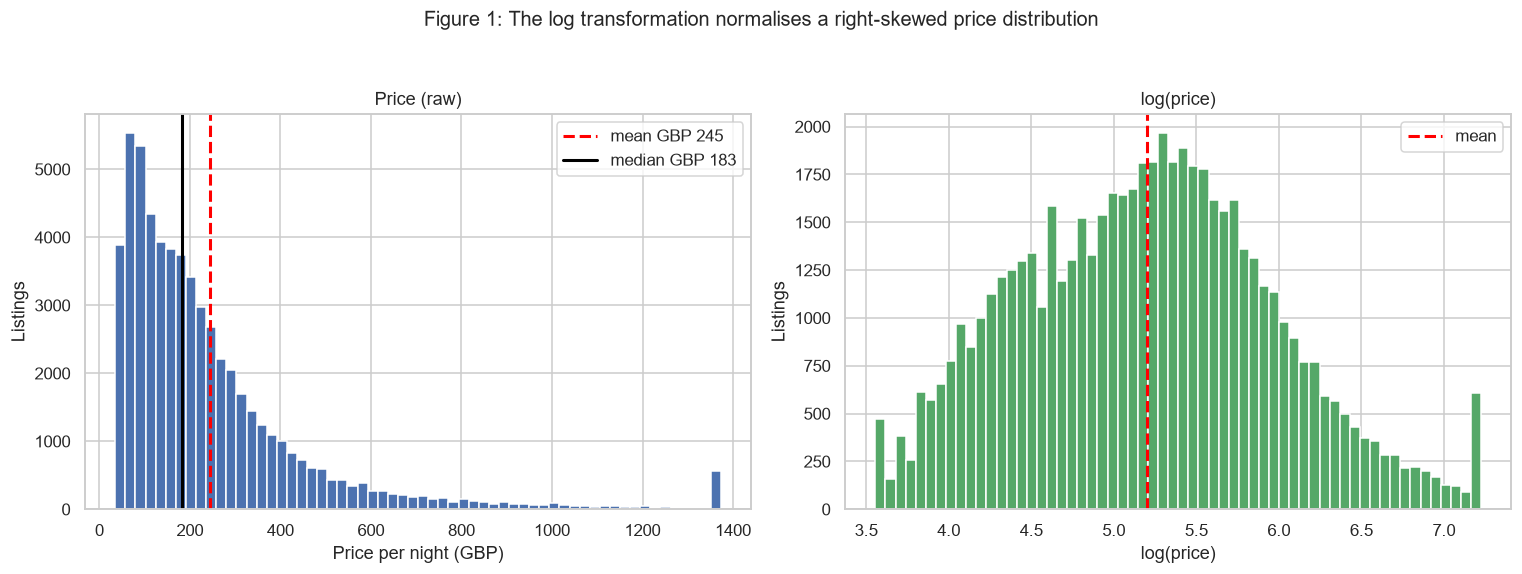

Skewness: price +2.52 -> log_price +0.18


In [29]:
# Figure 1 is the visual justification for the log transform.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_full["price"], bins=60, color="#4C72B0", edgecolor="white")
axes[0].axvline(df_full["price"].mean(), color="red", ls="--", lw=2,
                label=f"mean GBP {df_full['price'].mean():,.0f}")
axes[0].axvline(df_full["price"].median(), color="black", lw=2,
                label=f"median GBP {df_full['price'].median():,.0f}")
axes[0].set(title="Price (raw)", xlabel="Price per night (GBP)", ylabel="Listings")
axes[0].legend()

axes[1].hist(df_full["log_price"], bins=60, color="#55A868", edgecolor="white")
axes[1].axvline(df_full["log_price"].mean(), color="red", ls="--", lw=2, label="mean")
axes[1].set(title="log(price)", xlabel="log(price)", ylabel="Listings")
axes[1].legend()

fig.suptitle("Figure 1: The log transformation normalises a right-skewed price distribution",
             fontsize=13, y=1.04)
plt.savefig(OUT_DIR / "figure_1_price_distributions.png", bbox_inches="tight")
plt.show()

print(f"Skewness: price {df_full['price'].skew():+.2f} -> log_price {df_full['log_price'].skew():+.2f}")

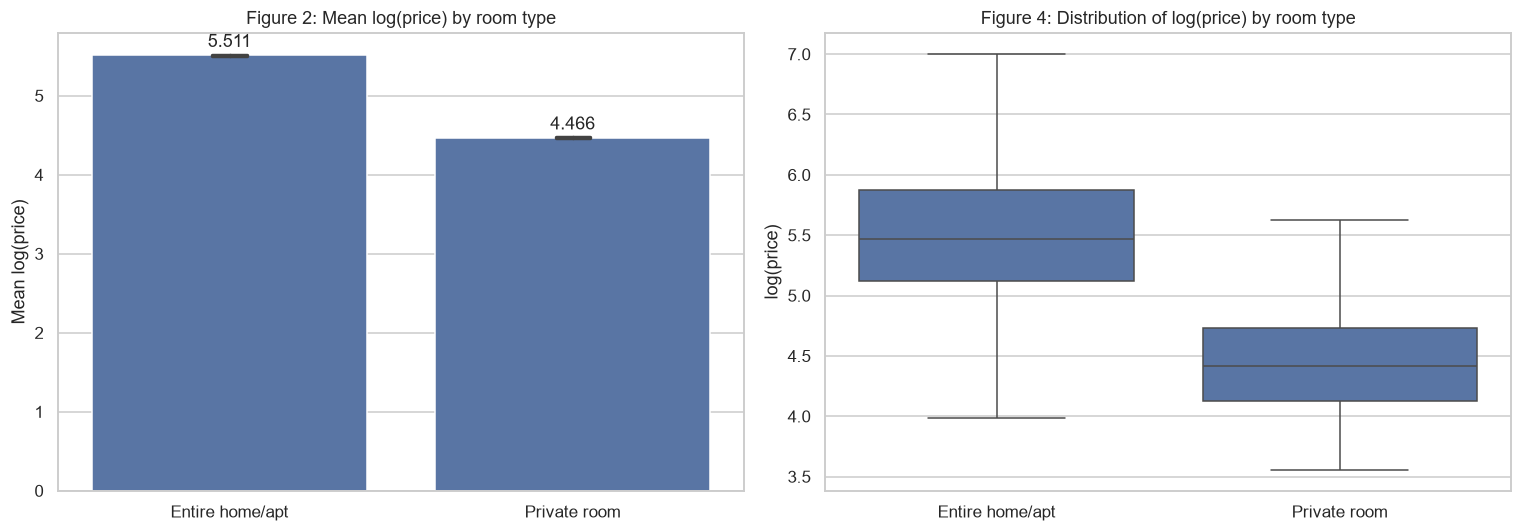

An entire home costs 2.90x a private room on average.


In [30]:
# The bar chart gives central tendency, the boxplot gives spread; reporting only the
# mean would hide how much the two distributions overlap.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df, x="room_type", y="log_price", ax=axes[0], errorbar=("ci", 95), capsize=0.1)
axes[0].set(title="Figure 2: Mean log(price) by room type", xlabel="", ylabel="Mean log(price)")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f", padding=3)

sns.boxplot(data=df, x="room_type", y="log_price", ax=axes[1], showfliers=False)
axes[1].set(title="Figure 4: Distribution of log(price) by room type", xlabel="", ylabel="log(price)")

plt.savefig(OUT_DIR / "figure_2_4_room_type.png", bbox_inches="tight")
plt.show()

means = df.groupby("room_type")["price"].mean()
if len(means) == 2:
    print(f"An entire home costs {means.get('Entire home/apt') / means.get('Private room'):.2f}x "
          f"a private room on average.")

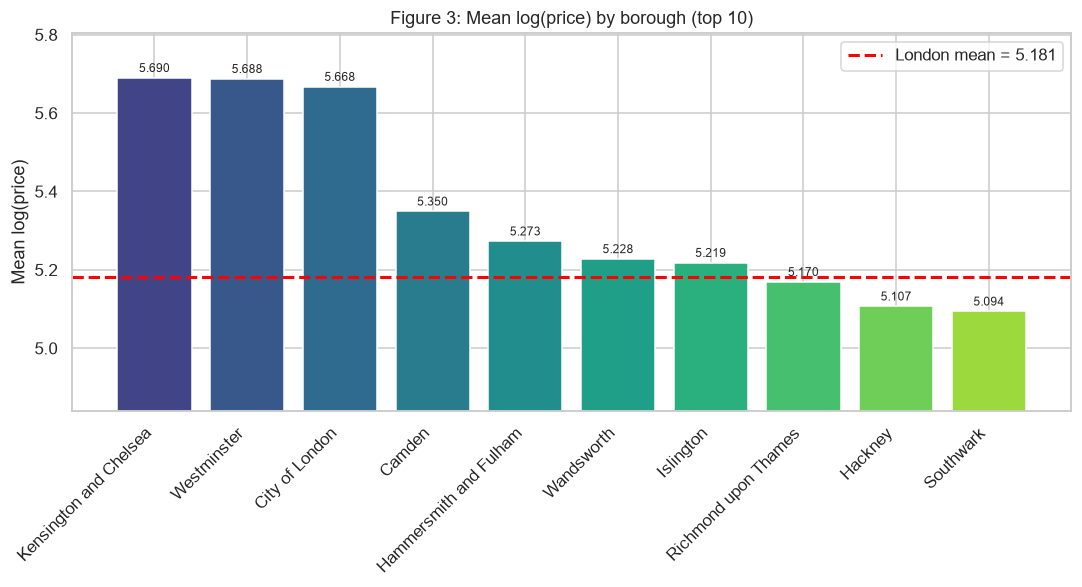

Most expensive : Westminster (GBP 375)
Least expensive: Sutton (GBP 121)
Ratio: 3.11x


In [31]:
# Ranking boroughs by mean log price motivates the fixed effects added in Model 4.
top10 = df.groupby("neighbourhood_cleansed")["log_price"].mean().nlargest(10)

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.bar(range(len(top10)), top10.values,
              color=plt.cm.viridis(np.linspace(0.2, 0.85, len(top10))))
ax.set_xticks(range(len(top10)))
ax.set_xticklabels(top10.index, rotation=45, ha="right")
ax.axhline(df["log_price"].mean(), color="red", ls="--", lw=2,
           label=f"London mean = {df['log_price'].mean():.3f}")
ax.set(title="Figure 3: Mean log(price) by borough (top 10)", ylabel="Mean log(price)")
ax.set_ylim(top10.min() * 0.95, top10.max() * 1.02)
ax.legend()
ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=8)

plt.savefig(OUT_DIR / "figure_3_top_boroughs.png", bbox_inches="tight")
plt.show()

borough_price = df.groupby("neighbourhood_cleansed")["price"].mean().sort_values(ascending=False)
print(f"Most expensive : {borough_price.index[0]} (GBP {borough_price.iloc[0]:,.0f})")
print(f"Least expensive: {borough_price.index[-1]} (GBP {borough_price.iloc[-1]:,.0f})")
print(f"Ratio: {borough_price.iloc[0] / borough_price.iloc[-1]:.2f}x")

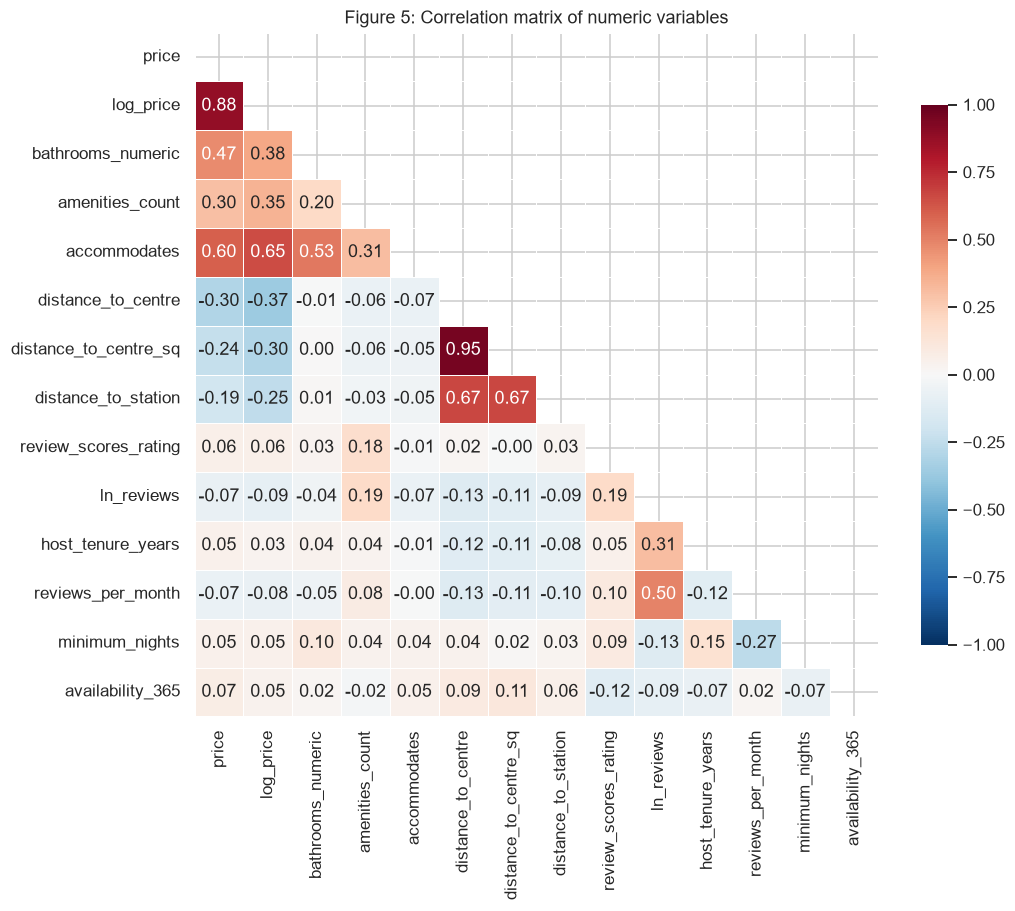

,r
price,0.8825
accommodates,0.6492
bathrooms_numeric,0.3839
distance_to_centre,-0.3669
amenities_count,0.3493
distance_to_centre_sq,-0.3039
distance_to_station,-0.2542
ln_reviews,-0.0937
reviews_per_month,-0.0759
review_scores_rating,0.0573


Pairs correlated above |0.7|: [('distance_to_centre', 'distance_to_centre_sq', np.float64(0.953))]


In [32]:
# The heatmap shows which variables move with price and is the first check for
# collinearity among the regressors.
corr_vars = [c for c in numeric_vars if df[c].nunique() > 2]
corr = df[corr_vars].corr()

fig, ax = plt.subplots(figsize=(max(8, len(corr_vars) * 0.7), max(6.5, len(corr_vars) * 0.6)))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, cbar_kws={"shrink": 0.75}, ax=ax)
ax.set_title("Figure 5: Correlation matrix of numeric variables")

plt.savefig(OUT_DIR / "figure_5_correlation_heatmap.png", bbox_inches="tight")
plt.show()

display(corr["log_price"].drop("log_price").sort_values(key=abs, ascending=False).to_frame("r"))

high = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(corr_vars) for b in corr_vars[i + 1:]
        if abs(corr.loc[a, b]) > 0.7 and "price" not in (a, b)]
print(f"Pairs correlated above |0.7|: {high if high else 'none'}")

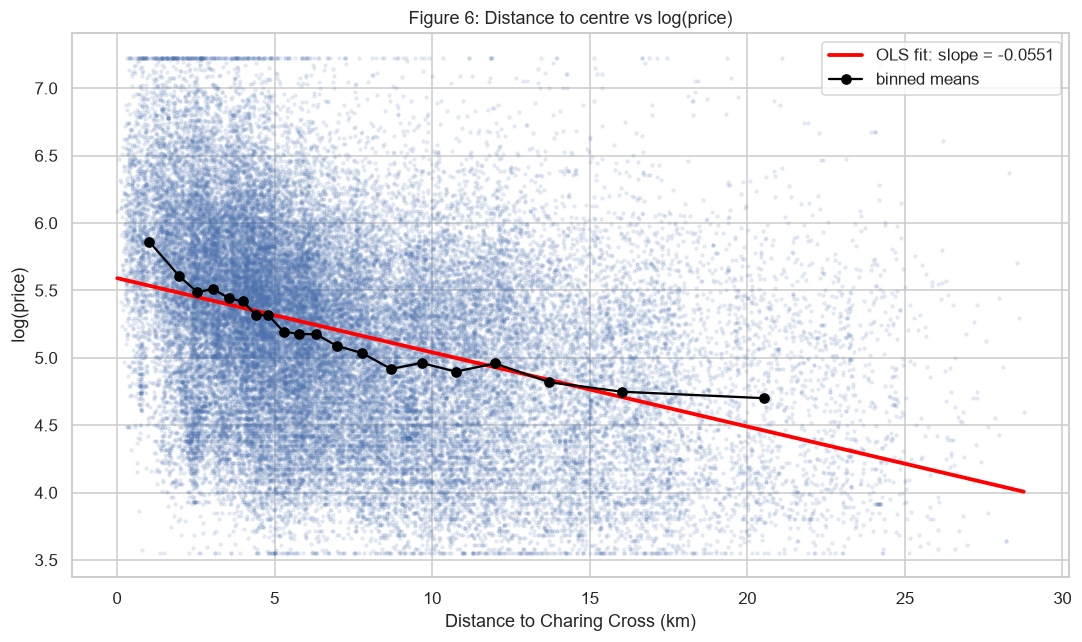

Correlation: r = -0.3669
Unconditionally, each additional km is associated with a -5.36% change in price.


In [33]:
# Direct visual test of the distance gradient, with binned means to check linearity.
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(df["distance_to_centre"], df["log_price"], s=4, alpha=0.10, color="#4C72B0")

slope, intercept = np.polyfit(df["distance_to_centre"], df["log_price"], 1)
xs = np.linspace(df["distance_to_centre"].min(), df["distance_to_centre"].max(), 100)
ax.plot(xs, slope * xs + intercept, color="red", lw=2.5, label=f"OLS fit: slope = {slope:.4f}")

bins = pd.qcut(df["distance_to_centre"], 20, duplicates="drop")
binned = df.groupby(bins, observed=True).agg(x=("distance_to_centre", "mean"),
                                             y=("log_price", "mean"))
ax.plot(binned["x"], binned["y"], "o-", color="black", ms=6, lw=1.5, label="binned means")

ax.set(title="Figure 6: Distance to centre vs log(price)",
       xlabel="Distance to Charing Cross (km)", ylabel="log(price)")
ax.legend()

plt.savefig(OUT_DIR / "figure_6_distance_vs_price.png", bbox_inches="tight")
plt.show()

r = df["distance_to_centre"].corr(df["log_price"])
print(f"Correlation: r = {r:+.4f}")
print(f"Unconditionally, each additional km is associated with a "
      f"{(np.exp(slope) - 1) * 100:+.2f}% change in price.")

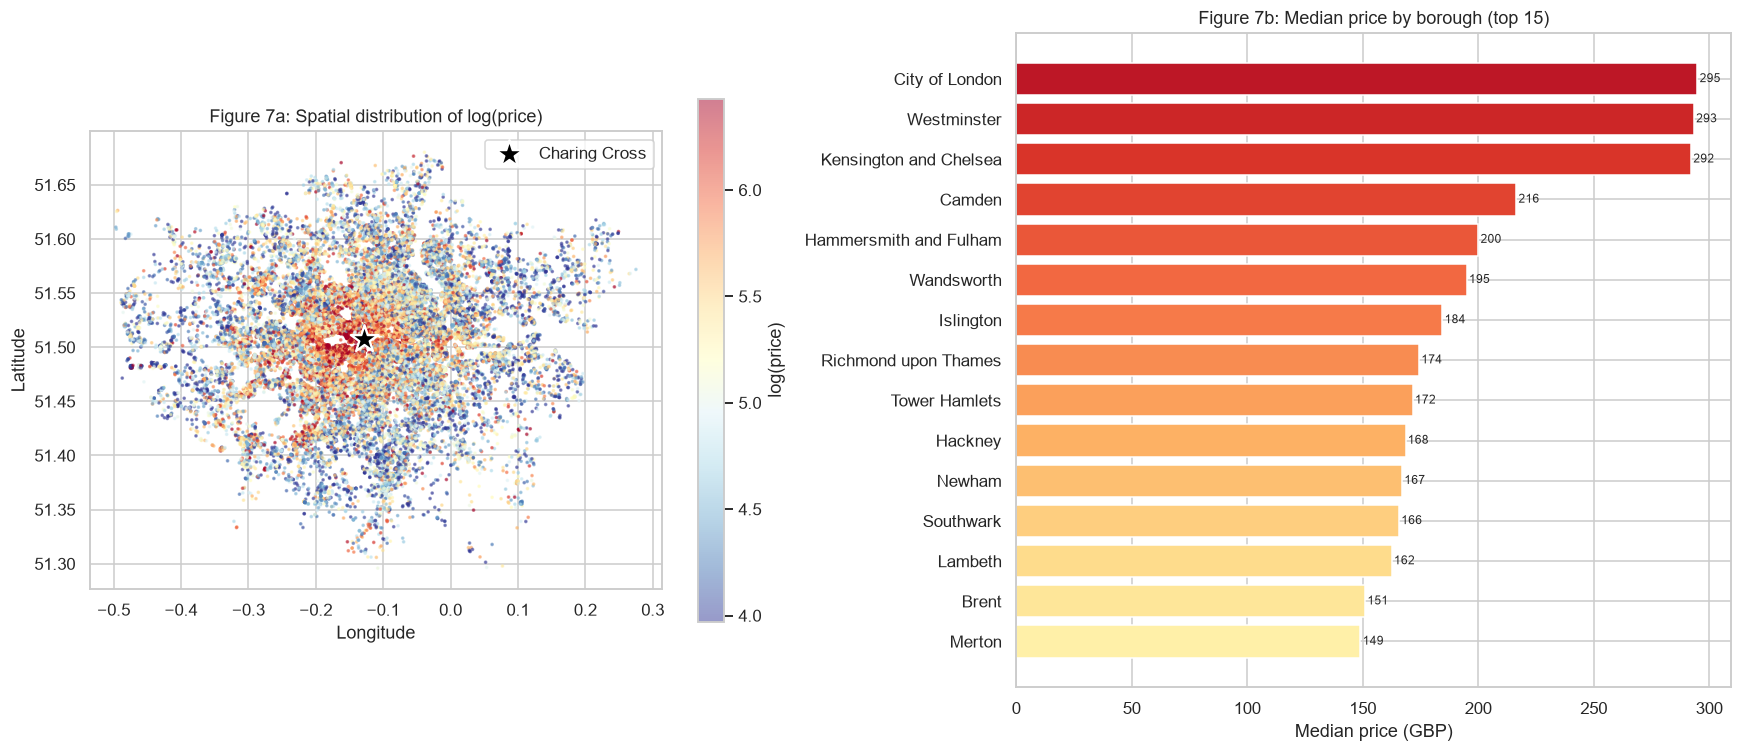

In [34]:
# Plotting listings on their coordinates shows within-borough variation that a
# borough-level choropleth would average away.
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Colour clipped to the 5th-95th percentile so a few extremes cannot flatten the scale.
vmin, vmax = df["log_price"].quantile([0.05, 0.95])
sc = axes[0].scatter(df["longitude"], df["latitude"], c=df["log_price"], cmap="RdYlBu_r",
                     s=2, alpha=0.5, vmin=vmin, vmax=vmax)
axes[0].scatter(*CENTRE[::-1], color="black", marker="*", s=350, zorder=5,
                edgecolor="white", linewidth=1.5, label="Charing Cross")
axes[0].set(title="Figure 7a: Spatial distribution of log(price)",
            xlabel="Longitude", ylabel="Latitude")
axes[0].legend(loc="upper right")
axes[0].set_aspect(1 / np.cos(np.radians(51.5)))
plt.colorbar(sc, ax=axes[0], label="log(price)", shrink=0.8)

median15 = df.groupby("neighbourhood_cleansed")["price"].median().nlargest(15).sort_values()
axes[1].barh(median15.index, median15.values,
             color=plt.cm.RdYlBu_r(np.linspace(0.55, 0.95, len(median15))))
axes[1].set(title="Figure 7b: Median price by borough (top 15)", xlabel="Median price (GBP)")
for i, v in enumerate(median15.values):
    axes[1].text(v + 1, i, f"{v:,.0f}", va="center", fontsize=8)

plt.savefig(OUT_DIR / "figure_7_spatial.png", bbox_inches="tight")
plt.show()

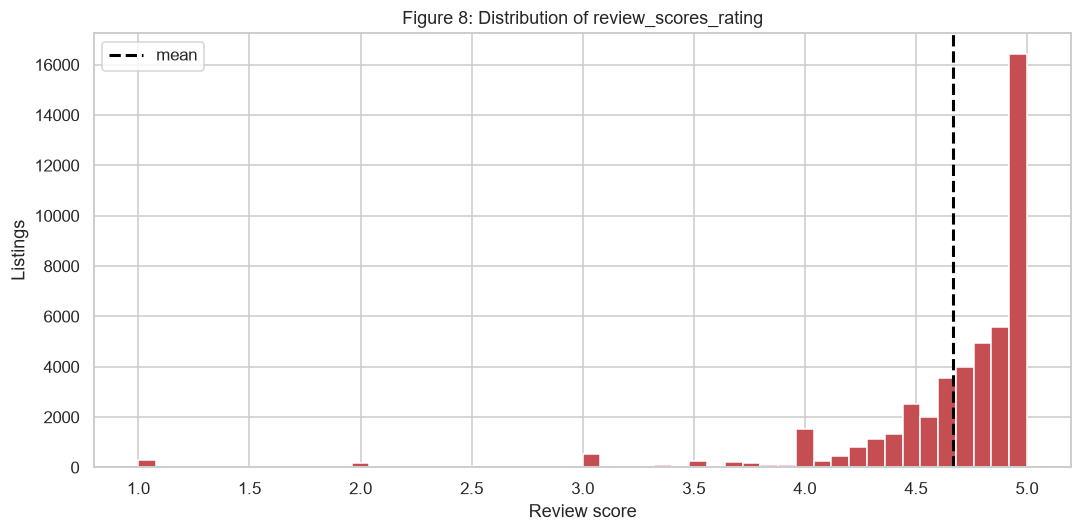

Mean 4.669, SD 0.508
Scores cluster near the maximum, so the identifying variation is small.


In [35]:
# A variable with almost no variance cannot explain price, so the shape of the
# reputation distribution matters when interpreting its coefficient.
if "review_scores_rating" in df.columns:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(df["review_scores_rating"].dropna(), bins=50, color="#C44E52", edgecolor="white")
    ax.axvline(df["review_scores_rating"].mean(), color="black", ls="--", lw=2, label="mean")
    ax.set(title="Figure 8: Distribution of review_scores_rating",
           xlabel="Review score", ylabel="Listings")
    ax.legend()
    plt.savefig(OUT_DIR / "figure_8_review_scores.png", bbox_inches="tight")
    plt.show()
    print(f"Mean {df['review_scores_rating'].mean():.3f}, SD {df['review_scores_rating'].std():.3f}")
    print("Scores cluster near the maximum, so the identifying variation is small.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].hist(df["number_of_reviews"], bins=60, color="#C44E52", edgecolor="white", log=True)
    axes[0].set(title="Figure 8a: Number of reviews", xlabel="Reviews", ylabel="Listings (log scale)")
    axes[1].hist(df["reviews_per_month"], bins=60, color="#8172B2", edgecolor="white")
    axes[1].set(title="Figure 8b: Reviews per month", xlabel="Reviews per month", ylabel="Listings")
    plt.savefig(OUT_DIR / "figure_8_reputation.png", bbox_inches="tight")
    plt.show()

---
## 5. Hedonic regression

$$\ln(price_i) = \beta_0 + \beta_1 PROPERTY_i + \beta_2 LOCATION_i + \beta_3 REPUTATION_i + \beta_4 HOST_i + \beta_5 BOOKING_i + FE_{borough} + \varepsilon_i$$

Five nested models, each adding one block, so the incremental contribution of each can
be read from the change in R². All are fitted with **standard errors clustered by host**.
Two assumptions fail here and both matter: price variance rises with price level
(heteroskedasticity), and a majority of listings belong to hosts operating several
properties, so listings are not independent. Clustering addresses both; classical or
merely heteroskedasticity-robust errors would overstate precision.

Booking variables — availability, minimum stay, review rate — are held out of the main
specification and enter only in Model 5, because they are jointly determined with price
rather than fixed characteristics of the property.

In [36]:

# Booking variables are held out of the main specification. Availability, minimum
# stay and review rate are jointly determined with price rather than fixed
# characteristics of the property, so conditioning on them would absorb part of the
# very variation the model is trying to explain. They enter separately in Model 5.
def build_formula(groups, borough_fe=False, interaction=False, booking=False):
    """Compose an OLS formula from the registered feature groups."""
    terms = [t for g in groups for t in FEATURES[g]]
    if booking:
        terms += FEATURES["BOOKING"]
    if borough_fe:
        terms.append("C(neighbourhood_cleansed)")
    if interaction and "accommodates" in FEATURES["PROPERTY"]:
        terms.append("distance_to_centre:accommodates")
    return "log_price ~ " + " + ".join(terms)


HAS_INTERACTION = "accommodates" in FEATURES["PROPERTY"]
CORE = ["PROPERTY", "LOCATION", "REPUTATION", "HOST"]

SPECS = {
    "Model 1: Property":          build_formula(["PROPERTY"]),
    "Model 2: + Location":        build_formula(["PROPERTY", "LOCATION"], interaction=True),
    "Model 3: + Reputation/Host": build_formula(CORE, interaction=True),
    "Model 4: + Borough FE (MAIN)": build_formula(CORE, borough_fe=True, interaction=True),
    "Model 5: + Booking controls": build_formula(CORE, borough_fe=True, interaction=True,
                                                 booking=True),
}
MAIN = "Model 4: + Borough FE (MAIN)"

header("model specifications")
for name, formula in SPECS.items():
    print(f"\n{name}\n  {formula}")

print(f"\nReference category, room_type : '{sorted(df['room_type'].unique())[0]}'")
print(f"Reference category, borough   : '{sorted(df['neighbourhood_cleansed'].unique())[0]}'")



MODEL SPECIFICATIONS

Model 1: Property
  log_price ~ bathrooms_numeric + shared_bath + amenities_count + air_conditioning + dishwasher + dedicated_workspace + parking_free + balcony_patio + pool_hot_tub + ev_charger + C(room_type) + accommodates

Model 2: + Location
  log_price ~ bathrooms_numeric + shared_bath + amenities_count + air_conditioning + dishwasher + dedicated_workspace + parking_free + balcony_patio + pool_hot_tub + ev_charger + C(room_type) + accommodates + distance_to_centre + distance_to_centre_sq + distance_to_station + distance_to_centre:accommodates

Model 3: + Reputation/Host
  log_price ~ bathrooms_numeric + shared_bath + amenities_count + air_conditioning + dishwasher + dedicated_workspace + parking_free + balcony_patio + pool_hot_tub + ev_charger + C(room_type) + accommodates + distance_to_centre + distance_to_centre_sq + distance_to_station + superhost + review_scores_rating + ln_reviews + host_tenure_years + is_professional_host + distance_to_centre:accommoda

In [37]:

# Standard errors are clustered by host throughout. A majority of listings belong to
# hosts operating several properties, whose prices share unobserved host-level
# factors, so treating listings as independent observations overstates precision.
CLUSTER = {"cov_type": "cluster", "cov_kwds": {"groups": df["host_id"]}}

n_hosts = df["host_id"].nunique()
per_host = df["host_id"].value_counts()
multi = per_host[per_host > 1].sum()

header("clustering structure")
print(f"Listings                   : {len(df):,}")
print(f"Distinct hosts             : {n_hosts:,}")
print(f"Mean listings per host     : {len(df) / n_hosts:.2f}")
print(f"Largest single host        : {per_host.max():,}")
print(f"Held by multi-listing hosts: {multi:,} ({multi / len(df) * 100:.1f}%)")

models = {name: smf.ols(formula, data=df).fit(**CLUSTER)
          for name, formula in SPECS.items()}

print()
for name, model in models.items():
    print(f"  {name:<32} N={int(model.nobs):>7,}  R2={model.rsquared:.4f}")

header("model 1: property attributes")
print(models["Model 1: Property"].summary())



CLUSTERING STRUCTURE
Listings                   : 46,725
Distinct hosts             : 23,645
Mean listings per host     : 1.98
Largest single host        : 126
Held by multi-listing hosts: 28,941 (61.9%)



  Model 1: Property                N= 46,725  R2=0.6450
  Model 2: + Location              N= 46,725  R2=0.7022
  Model 3: + Reputation/Host       N= 46,725  R2=0.7130
  Model 4: + Borough FE (MAIN)     N= 46,725  R2=0.7290
  Model 5: + Booking controls      N= 46,725  R2=0.7386

MODEL 1: PROPERTY ATTRIBUTES


                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.645
Model:                            OLS   Adj. R-squared:                  0.645
Method:                 Least Squares   F-statistic:                     1418.
Date:                Thu, 20 Aug 2026   Prob (F-statistic):               0.00
Time:                        21:22:35   Log-Likelihood:                -28536.
No. Observations:               46725   AIC:                         5.710e+04
Df Residuals:                   46712   BIC:                         5.721e+04
Df Model:                          12                                         
Covariance Type:              cluster                                         
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

In [38]:
header("model 2: property + location")
print(models["Model 2: + Location"].summary())


MODEL 2: PROPERTY + LOCATION
                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.702
Model:                            OLS   Adj. R-squared:                  0.702
Method:                 Least Squares   F-statistic:                     1607.
Date:                Thu, 20 Aug 2026   Prob (F-statistic):               0.00
Time:                        21:22:36   Log-Likelihood:                -24433.
No. Observations:               46725   AIC:                         4.890e+04
Df Residuals:                   46708   BIC:                         4.905e+04
Df Model:                          16                                         
Covariance Type:              cluster                                         
                                      coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------

In [39]:
header("model 3: + reputation and host")
print(models["Model 3: + Reputation/Host"].summary())


MODEL 3: + REPUTATION AND HOST


                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.713
Model:                            OLS   Adj. R-squared:                  0.713
Method:                 Least Squares   F-statistic:                     1443.
Date:                Thu, 20 Aug 2026   Prob (F-statistic):               0.00
Time:                        21:22:36   Log-Likelihood:                -23573.
No. Observations:               46725   AIC:                         4.719e+04
Df Residuals:                   46703   BIC:                         4.738e+04
Df Model:                          21                                         
Covariance Type:              cluster                                         
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept 

In [40]:

# Borough fixed effects absorb time-invariant borough characteristics, so the
# remaining coefficients are identified from variation within boroughs.
header("model 4: main specification")
print(models[MAIN].summary())



MODEL 4: MAIN SPECIFICATION


                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.729
Model:                            OLS   Adj. R-squared:                  0.729
Method:                 Least Squares   F-statistic:                     666.8
Date:                Thu, 20 Aug 2026   Prob (F-statistic):               0.00
Time:                        21:22:36   Log-Likelihood:                -22234.
No. Observations:               46725   AIC:                         4.458e+04
Df Residuals:                   46671   BIC:                         4.505e+04
Df Model:                          53                                         
Covariance Type:              cluster                                         
                                                          coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------

In [41]:

header("model comparison")

rows, previous_r2 = [], None
for name, model in models.items():
    rows.append({"Model": name, "N": int(model.nobs), "R2": model.rsquared,
                 "Adj. R2": model.rsquared_adj,
                 "Delta R2": np.nan if previous_r2 is None else model.rsquared - previous_r2,
                 "AIC": model.aic})
    previous_r2 = model.rsquared

comparison = pd.DataFrame(rows).set_index("Model")
display(comparison.round(4))

r2s = comparison["R2"].tolist()
print("Incremental contribution:")
print(f"  Property attributes alone : {r2s[0] * 100:5.2f}%")
print(f"  + Location                : {(r2s[1] - r2s[0]) * 100:5.2f} pp")
print(f"  + Reputation and host     : {(r2s[2] - r2s[1]) * 100:5.2f} pp")
print(f"  + Borough fixed effects   : {(r2s[3] - r2s[2]) * 100:5.2f} pp")
print(f"  Main specification R2     : {r2s[3] * 100:5.2f}%")
print(f"  + Booking controls        : {(r2s[4] - r2s[3]) * 100:5.2f} pp (reported separately)")



MODEL COMPARISON


,N,R2,Adj. R2,Delta R2,AIC
Model,,,,,
Model 1: Property,46725,0.6450,0.6449,NaN,"57,098.4371"
Model 2: + Location,46725,0.7022,0.7021,0.0572,"48,899.5094"
Model 3: + Reputation/Host,46725,0.7130,0.7128,0.0108,"47,190.2029"
Model 4: + Borough FE (MAIN),46725,0.7290,0.7286,0.0160,"44,575.7173"
Model 5: + Booking controls,46725,0.7386,0.7383,0.0096,"42,894.0630"


Incremental contribution:
  Property attributes alone : 64.50%
  + Location                :  5.72 pp
  + Reputation and host     :  1.08 pp
  + Borough fixed effects   :  1.60 pp
  Main specification R2     : 72.90%
  + Booking controls        :  0.96 pp (reported separately)


In [42]:

# A rise in R-squared alone does not establish that a block belongs in the model, so
# each is tested formally. The Wald test asks whether the block's coefficients are
# jointly zero, using the clustered covariance matrix.
header("joint significance of each block (Wald tests)")


def wald_block(model, terms, label):
    """Joint test that the listed coefficients are all zero."""
    present = [t for t in terms if t in model.params.index]
    if not present:
        print(f"  {label:<26} no terms present")
        return
    test = model.wald_test(np.eye(len(model.params))[
        [model.params.index.get_loc(t) for t in present]], scalar=True)
    print(f"  {label:<26} F={test.statistic:9.2f}   p={test.pvalue:.3g}   "
          f"df={len(present)}")


location_terms = FEATURES["LOCATION"] + (["distance_to_centre:accommodates"]
                                         if HAS_INTERACTION else [])
wald_block(models[MAIN], location_terms, "Location block")
wald_block(models[MAIN], FEATURES["REPUTATION"], "Reputation block")
wald_block(models[MAIN], FEATURES["HOST"], "Host block")
wald_block(models[MAIN], [t for t in models[MAIN].params.index
                          if t.startswith("C(neighbourhood_cleansed)")], "Borough fixed effects")
wald_block(models["Model 5: + Booking controls"], FEATURES["BOOKING"], "Booking controls")

print("\nEach block is jointly significant, so the nested progression above reflects")
print("genuine explanatory contribution rather than the mechanical rise in R-squared")
print("that follows from adding any regressor.")



JOINT SIGNIFICANCE OF EACH BLOCK (WALD TESTS)
  Location block             F=   931.00   p=3.2e-200   df=4
  Reputation block           F=   609.75   p=7.76e-132   df=3
  Host block                 F=    42.26   p=6.66e-10   df=2


  Borough fixed effects      F=  1201.18   p=5.51e-232   df=32
  Booking controls           F=   476.06   p=7.36e-103   df=3

Each block is jointly significant, so the nested progression above reflects
genuine explanatory contribution rather than the mechanical rise in R-squared
that follows from adding any regressor.


### Separating the blocks

Model 3 adds reputation, host and booking variables together, so their individual
contributions cannot be separated. Entering each block on its own recovers the
incremental R² attributable to each and allows the correlates of price to be ranked by explanatory contribution.

In [43]:
header("block decomposition")

BLOCK_SEQUENCE = [
    ("1. Property",     ["PROPERTY"], False),
    ("2. + Location",   ["PROPERTY", "LOCATION"], False),
    ("3. + Reputation", ["PROPERTY", "LOCATION", "REPUTATION"], False),
    ("4. + Host",       ["PROPERTY", "LOCATION", "REPUTATION", "HOST"], False),
    ("5. + Booking",    ["PROPERTY", "LOCATION", "REPUTATION", "HOST", "BOOKING"], False),
    ("6. + Borough FE", ["PROPERTY", "LOCATION", "REPUTATION", "HOST", "BOOKING"], True),
]

decomp_rows, prev_r2 = [], None
for label, groups, fe in BLOCK_SEQUENCE:
    fitted_block = smf.ols(build_formula(groups, borough_fe=fe), data=df).fit(**CLUSTER)
    decomp_rows.append({"Step": label, "R2": fitted_block.rsquared,
                        "Adj. R2": fitted_block.rsquared_adj,
                        "Delta R2 (pp)": np.nan if prev_r2 is None
                        else (fitted_block.rsquared - prev_r2) * 100,
                        "k (params)": int(fitted_block.df_model)})
    prev_r2 = fitted_block.rsquared

decomp = pd.DataFrame(decomp_rows).set_index("Step")
display(decomp.round(4))

print("Blocks ranked by incremental explanatory power:")
for step, value in decomp["Delta R2 (pp)"].dropna().sort_values(ascending=False).items():
    print(f"  {step:<18} {value:+.2f} pp")


BLOCK DECOMPOSITION


,R2,Adj. R2,Delta R2 (pp),k (params)
Step,,,,
1. Property,0.6450,0.6449,NaN,12
2. + Location,0.7019,0.7019,5.6923,15
3. + Reputation,0.7114,0.7113,0.9497,18
4. + Host,0.7128,0.7126,0.1330,20
5. + Booking,0.7225,0.7224,0.9764,23
6. + Borough FE,0.7385,0.7382,1.6008,55


Blocks ranked by incremental explanatory power:
  2. + Location      +5.69 pp
  6. + Borough FE    +1.60 pp
  5. + Booking       +0.98 pp
  3. + Reputation    +0.95 pp
  4. + Host          +0.13 pp


### Extended specification

Three refinements to the main model:

- **Quadratic distance**, because the diagnostics in Section 6 show the gradient is
  non-linear.
- **Distance × capacity interaction**, testing whether the centrality premium differs
  between large and small properties rather than forcing them to be equal.
- **Clustered standard errors.** The same host often lists many properties, so listings
  are not independent — the assumption underlying every p-value reported so far.
  Clustering by `host_id` corrects the inference.

In [44]:
header("host clustering structure")

n_hosts = df["host_id"].nunique()
listings_per_host = df["host_id"].value_counts()
multi = listings_per_host[listings_per_host > 1].sum()

print(f"Listings              : {len(df):,}")
print(f"Distinct hosts        : {n_hosts:,}")
print(f"Mean per host         : {len(df) / n_hosts:.2f}")
print(f"Largest single host   : {listings_per_host.max():,} listings")
print(f"Held by multi-listing hosts: {multi:,} ({multi / len(df) * 100:.1f}%)")
print("\nWith this much within-host repetition, treating listings as independent")
print("overstates the effective sample size and deflates standard errors.")


HOST CLUSTERING STRUCTURE
Listings              : 46,725
Distinct hosts        : 23,645
Mean per host         : 1.98
Largest single host   : 126 listings
Held by multi-listing hosts: 28,941 (61.9%)

With this much within-host repetition, treating listings as independent
overstates the effective sample size and deflates standard errors.


In [45]:

# The main specification is fitted three ways so the effect of the error assumption
# is isolated from the specification itself: the coefficients are identical across
# all three, only the standard errors differ.
header("effect of the error assumption on inference")

model_ext_classical = smf.ols(SPECS[MAIN], data=df).fit()
model_ext_hc1 = smf.ols(SPECS[MAIN], data=df).fit(cov_type="HC1")
model_ext_clustered = models[MAIN]



EFFECT OF THE ERROR ASSUMPTION ON INFERENCE


In [46]:

se_terms = [t for t in model_ext_clustered.params.index
            if not t.startswith("C(neighbourhood_cleansed)") and t != "Intercept"]

se_compare = pd.DataFrame({
    "Coefficient": model_ext_clustered.params[se_terms],
    "SE classical": model_ext_classical.bse[se_terms],
    "SE HC1": model_ext_hc1.bse[se_terms],
    "SE clustered": model_ext_clustered.bse[se_terms],
    "p (HC1)": model_ext_hc1.pvalues[se_terms],
    "p (clustered)": model_ext_clustered.pvalues[se_terms],
})
se_compare["SE inflation"] = se_compare["SE clustered"] / se_compare["SE HC1"]
display(se_compare.round(4))

print(f"Median SE inflation from clustering: {se_compare['SE inflation'].median():.2f}x")

# A variable significant under HC1 but not under clustering was a false positive
# produced by the independence assumption, so these are listed explicitly.
flipped = se_compare[(se_compare["p (HC1)"] < 0.05) & (se_compare["p (clustered)"] >= 0.05)]
if len(flipped):
    print(f"\n{len(flipped)} coefficient(s) lose 5% significance once errors are clustered:")
    display(flipped[["Coefficient", "p (HC1)", "p (clustered)"]].round(4))
    print("These are reported as null results. Had HC1 errors been used throughout, each")
    print("would have been reported as a significant finding.")
else:
    print("\nNo coefficient changes significance status under clustering.")


,Coefficient,SE classical,SE HC1,SE clustered,p (HC1),p (clustered),SE inflation
C(room_type)[T.Private room],-0.4166,0.0059,0.0061,0.0103,0.0000,0.0000,1.6872
bathrooms_numeric,0.1071,0.0034,0.0043,0.0074,0.0000,0.0000,1.7155
shared_bath,-0.2443,0.0065,0.0069,0.0108,0.0000,0.0000,1.5703
amenities_count,0.0019,0.0002,0.0002,0.0003,0.0000,0.0000,1.8339
air_conditioning,0.1832,0.0058,0.0063,0.0133,0.0000,0.0000,2.1186
dishwasher,0.1391,0.0045,0.0044,0.0072,0.0000,0.0000,1.6203
dedicated_workspace,0.0048,0.0039,0.0039,0.0070,0.2173,0.4895,1.7850
parking_free,0.0356,0.0054,0.0054,0.0074,0.0000,0.0000,1.3660
balcony_patio,0.0424,0.0047,0.0045,0.0058,0.0000,0.0000,1.2869
pool_hot_tub,0.0562,0.0111,0.0126,0.0197,0.0000,0.0043,1.5640


Median SE inflation from clustering: 1.66x

No coefficient changes significance status under clustering.


In [47]:

# The distance coefficients cannot be read individually once the squared term and the
# interaction are present, so the marginal effect is evaluated at real points in the data.
header("marginal effect of distance from the centre")

m = models[MAIN]
b_lin = m.params["distance_to_centre"]
b_sq = m.params.get("distance_to_centre_sq", 0.0)
b_int = m.params.get("distance_to_centre:accommodates", 0.0)
mean_cap = df["accommodates"].mean()

print(f"distance_to_centre                : {b_lin:+.5f}  (p = {m.pvalues['distance_to_centre']:.3g})")
if "distance_to_centre_sq" in m.params.index:
    print(f"distance_to_centre^2              : {b_sq:+.6f}  "
          f"(p = {m.pvalues['distance_to_centre_sq']:.3g})")
if HAS_INTERACTION:
    print(f"distance_to_centre x accommodates : {b_int:+.5f}  "
          f"(p = {m.pvalues['distance_to_centre:accommodates']:.3g})")

print(f"\nMarginal effect per additional km, at mean capacity ({mean_cap:.1f} guests):\n")
for km in [0, 1, 2, 5, 10, 15, 20]:
    me = b_lin + 2 * b_sq * km + b_int * mean_cap
    print(f"  at {km:2d} km from centre : {(np.exp(me) - 1) * 100:+.2f}% per km")

# A quadratic in distance turns at -b1/(2*b2). Beyond that point the fitted gradient
# reverses sign, which is an artefact of the functional form rather than a finding,
# so the turning point is reported and the interpretation confined to within it.
if b_sq > 0:
    turning = -b_lin / (2 * b_sq)
    beyond = (df["distance_to_centre"] > turning).mean() * 100
    print(f"\nThe fitted gradient turns at {turning:.1f} km, beyond which it implies a")
    print(f"price premium for greater distance. Only {beyond:.1f}% of listings lie beyond")
    print("this point, so the quadratic should be read as describing the steep central")
    print("gradient and its flattening, not as evidence of an outer-London premium.")

if HAS_INTERACTION:
    print(f"\nMarginal effect at 5 km by property capacity:\n")
    for q in [0.10, 0.50, 0.90]:
        cap = df["accommodates"].quantile(q)
        me = b_lin + 2 * b_sq * 5 + b_int * cap
        print(f"  accommodates = {cap:>4.0f} (p{q*100:.0f})  ->  {(np.exp(me) - 1) * 100:+.2f}% per km")
    print("\nLarger properties face a steeper distance penalty."
          if b_int < 0 else "\nSmaller properties face a steeper distance penalty.")



MARGINAL EFFECT OF DISTANCE FROM THE CENTRE
distance_to_centre                : -0.09344  (p = 2.61e-123)
distance_to_centre^2              : +0.002795  (p = 1.11e-63)
distance_to_centre x accommodates : -0.00060  (p = 0.0167)

Marginal effect per additional km, at mean capacity (3.6 guests):

  at  0 km from centre : -9.11% per km
  at  1 km from centre : -8.60% per km
  at  2 km from centre : -8.09% per km
  at  5 km from centre : -6.54% per km
  at 10 km from centre : -3.89% per km
  at 15 km from centre : -1.16% per km
  at 20 km from centre : +1.64% per km

The fitted gradient turns at 16.7 km, beyond which it implies a
price premium for greater distance. Only 6.2% of listings lie beyond
this point, so the quadratic should be read as describing the steep central
gradient and its flattening, not as evidence of an outer-London premium.

Marginal effect at 5 km by property capacity:

  accommodates =    2 (p10)  ->  -6.45% per km
  accommodates =    3 (p50)  ->  -6.51% per km
  acco

In [48]:

# In a log-linear model the exact percentage effect is (exp(b)-1)*100; the "multiply
# by 100" shortcut is only accurate for small coefficients.
def pct_effect(beta):
    """Exact percentage effect on price from a log-linear coefficient."""
    return (np.exp(beta) - 1) * 100


def stars(p):
    """Conventional significance markers."""
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""


header("main specification as percentage effects")

final = models[MAIN]
main_terms = [t for t in final.params.index
              if not t.startswith("C(neighbourhood_cleansed)") and t != "Intercept"]

results = pd.DataFrame({
    "Coefficient": final.params[main_terms],
    "Clustered SE": final.bse[main_terms],
    "t": final.tvalues[main_terms],
    "p-value": final.pvalues[main_terms],
    "% effect": [pct_effect(b) for b in final.params[main_terms]],
    "Sig.": [stars(p) for p in final.pvalues[main_terms]],
})
results["CI low %"] = [pct_effect(v) for v in final.conf_int().loc[main_terms, 0]]
results["CI high %"] = [pct_effect(v) for v in final.conf_int().loc[main_terms, 1]]
display(results.round(4))
print("*** p<0.01, ** p<0.05, * p<0.10   (standard errors clustered by host)")



MAIN SPECIFICATION AS PERCENTAGE EFFECTS


,Coefficient,Clustered SE,t,p-value,% effect,Sig.,CI low %,CI high %
C(room_type)[T.Private room],-0.4166,0.0103,-40.3359,0.0000,-34.0718,***,-35.3930,-32.7236
bathrooms_numeric,0.1071,0.0074,14.4829,0.0000,11.3048,***,9.7031,12.9298
shared_bath,-0.2443,0.0108,-22.6775,0.0000,-21.6759,***,-23.3124,-20.0045
amenities_count,0.0019,0.0003,5.5232,0.0000,0.1854,***,0.1196,0.2513
air_conditioning,0.1832,0.0133,13.7850,0.0000,20.1061,***,17.0179,23.2757
dishwasher,0.1391,0.0072,19.3527,0.0000,14.9219,***,13.3145,16.5521
dedicated_workspace,0.0048,0.0070,0.6911,0.4895,0.4818,,-0.8785,1.8607
parking_free,0.0356,0.0074,4.8365,0.0000,3.6221,***,2.1387,5.1270
balcony_patio,0.0424,0.0058,7.3175,0.0000,4.3279,***,3.1506,5.5186
pool_hot_tub,0.0562,0.0197,2.8561,0.0043,5.7825,***,1.7795,9.9429


*** p<0.01, ** p<0.05, * p<0.10   (standard errors clustered by host)


In [49]:

# Coefficients are on the log scale, which is hard to weigh practically. Converting
# each to a pound figure at the median price makes the magnitudes comparable and
# interpretable. Model 5 p-values are shown alongside to confirm the estimates are not
# sensitive to whether booking controls are included.
header("effect sizes in pounds per night")

median_price = df["price"].median()
booking_model = models["Model 5: + Booking controls"]
print(f"Evaluated at the median listing price of GBP {median_price:,.2f} per night\n")

EFFECT_ROWS = [
    ("C(room_type)[T.Private room]", "Private room (vs entire home)"),
    ("accommodates",                 "One additional guest accommodated"),
    ("bathrooms_numeric",            "One additional bathroom"),
    ("shared_bath",                  "Shared rather than private bathroom"),
    ("amenities_count",              "One additional amenity"),
    ("air_conditioning",             "Air conditioning"),
    ("dishwasher",                   "Dishwasher"),
    ("balcony_patio",                "Balcony or patio"),
    ("superhost",                    "Superhost status"),
    ("review_scores_rating",         "One point higher review score"),
    ("ln_reviews",                   "One unit higher ln(1+reviews)"),
    ("host_tenure_years",            "One additional year of host tenure"),
    ("is_professional_host",         "Multi-listing (professional) host"),
]

effect_rows = []
for term, label in EFFECT_ROWS:
    if term not in final.params.index:
        continue
    beta = final.params[term]
    effect_rows.append({
        "Feature": label,
        "Coefficient": round(beta, 4),
        "Effect %": round(pct_effect(beta), 2),
        "Effect GBP/night": round(median_price * (np.exp(beta) - 1), 2),
        "p (Model 4)": f"{final.pvalues[term]:.4f}{stars(final.pvalues[term])}",
        "p (Model 5)": (f"{booking_model.pvalues[term]:.4f}{stars(booking_model.pvalues[term])}"
                        if term in booking_model.params.index else "n/a"),
    })

# Distance enters non-linearly, so its row reports the marginal effect at the median
# distance rather than a raw coefficient that has no standalone interpretation.
median_dist = df["distance_to_centre"].median()
marginal_at_median = (final.params["distance_to_centre"]
                      + 2 * final.params.get("distance_to_centre_sq", 0.0) * median_dist
                      + final.params.get("distance_to_centre:accommodates", 0.0)
                      * df["accommodates"].mean())
effect_rows.append({
    "Feature": f"One km further from centre (at {median_dist:.1f} km)",
    "Coefficient": round(marginal_at_median, 4),
    "Effect %": round(pct_effect(marginal_at_median), 2),
    "Effect GBP/night": round(median_price * (np.exp(marginal_at_median) - 1), 2),
    "p (Model 4)": f"{final.pvalues['distance_to_centre']:.4f}"
                   f"{stars(final.pvalues['distance_to_centre'])}",
    "p (Model 5)": f"{booking_model.pvalues['distance_to_centre']:.4f}"
                   f"{stars(booking_model.pvalues['distance_to_centre'])}",
})
if "distance_to_station" in final.params.index:
    b = final.params["distance_to_station"]
    effect_rows.append({
        "Feature": "One km further from nearest station",
        "Coefficient": round(b, 4), "Effect %": round(pct_effect(b), 2),
        "Effect GBP/night": round(median_price * (np.exp(b) - 1), 2),
        "p (Model 4)": f"{final.pvalues['distance_to_station']:.4f}"
                       f"{stars(final.pvalues['distance_to_station'])}",
        "p (Model 5)": f"{booking_model.pvalues['distance_to_station']:.4f}"
                       f"{stars(booking_model.pvalues['distance_to_station'])}",
    })

effect_df = pd.DataFrame(effect_rows)
display(effect_df)
effect_df.to_csv(OUT_DIR / "table_effect_sizes_pounds.csv", index=False)
print("Saved -> outputs/table_effect_sizes_pounds.csv")
print("*** p<0.01, ** p<0.05, * p<0.10   (standard errors clustered by host)")



EFFECT SIZES IN POUNDS PER NIGHT
Evaluated at the median listing price of GBP 181.00 per night



,Feature,Coefficient,Effect %,Effect GBP/night,p (Model 4),p (Model 5)
0,Private room (vs entire home),-0.4166,-34.0700,-61.6700,0.0000***,0.0000***
1,One additional guest accommodated,0.1201,12.7600,23.1000,0.0000***,0.0000***
2,One additional bathroom,0.1071,11.3000,20.4600,0.0000***,0.0000***
3,Shared rather than private bathroom,-0.2443,-21.6800,-39.2300,0.0000***,0.0000***
4,One additional amenity,0.0019,0.1900,0.3400,0.0000***,0.0000***
5,Air conditioning,0.1832,20.1100,36.3900,0.0000***,0.0000***
6,Dishwasher,0.1391,14.9200,27.0100,0.0000***,0.0000***
7,Balcony or patio,0.0424,4.3300,7.8300,0.0000***,0.0000***
8,Superhost status,0.0739,7.6600,13.8700,0.0000***,0.0000***
9,One point higher review score,0.0722,7.4800,13.5500,0.0000***,0.0000***


Saved -> outputs/table_effect_sizes_pounds.csv


*** p<0.01, ** p<0.05, * p<0.10   (standard errors clustered by host)


In [50]:
header("interpretation")

LABELS = {
    "accommodates": "each additional guest accommodated",
    "bedrooms": "each additional bedroom",
    "bathrooms_numeric": "each additional bathroom",
    "shared_bath": "having a shared rather than private bathroom",
    "amenities_count": "each additional amenity",
    "air_conditioning": "having air conditioning",
    "dishwasher": "having a dishwasher",
    "dedicated_workspace": "having a dedicated workspace",
    "parking_free": "having free parking",
    "balcony_patio": "having a balcony or patio",
    "pool_hot_tub": "having a pool or hot tub",
    "ev_charger": "having an EV charger",
    "distance_to_centre": "each additional kilometre from Charing Cross",
    "distance_to_station": "each additional kilometre from the nearest station",
    "superhost": "Superhost status",
    "review_scores_rating": "a one-point higher review score",
    "ln_reviews": "a one-unit rise in ln(1+reviews)",
    "reviews_per_month": "one additional review per month",
    "host_tenure_years": "each additional year of host tenure",
    "is_professional_host": "being a multi-listing host",
    "instant_bookable": "enabling instant booking",
    "minimum_nights": "each additional minimum night",
    "availability_365": "each additional day of annual availability",
}

for term in main_terms:
    label = LABELS.get(term, term)
    if term.startswith("C(room_type)"):
        label = f"being a {term.split('[T.')[1].rstrip(']')} rather than an entire home"
    beta, p = final.params[term], final.pvalues[term]
    effect = pct_effect(beta)
    sig = (f"significant at {'1%' if p < 0.01 else '5%' if p < 0.05 else '10%'}"
           if p < 0.10 else f"not significant (p = {p:.3f})")
    print(f"{label.capitalize()} is associated with a {abs(effect):.2f}% "
          f"{'higher' if effect > 0 else 'lower'} price, holding all else constant "
          f"({sig}).")


INTERPRETATION
Being a private room rather than an entire home is associated with a 34.07% lower price, holding all else constant (significant at 1%).
Each additional bathroom is associated with a 11.30% higher price, holding all else constant (significant at 1%).
Having a shared rather than private bathroom is associated with a 21.68% lower price, holding all else constant (significant at 1%).
Each additional amenity is associated with a 0.19% higher price, holding all else constant (significant at 1%).
Having air conditioning is associated with a 20.11% higher price, holding all else constant (significant at 1%).
Having a dishwasher is associated with a 14.92% higher price, holding all else constant (significant at 1%).
Having a dedicated workspace is associated with a 0.48% higher price, holding all else constant (not significant (p = 0.489)).
Having free parking is associated with a 3.62% higher price, holding all else constant (significant at 1%).
Having a balcony or patio is ass

In [51]:

header("hypothesis assessment")

# Verdicts are evaluated against the clustered standard errors. Under HC1 several of
# these would read as supported; the clustered results are the defensible ones.
def verdict(term, expected_sign, label=None):
    """Compare an estimated coefficient against its hypothesised sign."""
    name = label or term
    if term not in final.params.index:
        return f"{name:<34} not testable - variable unavailable"
    beta, p = final.params[term], final.pvalues[term]
    if p >= 0.05:
        return f"{name:<34} beta={beta:+.4f}  p={p:.3f}  -> not significant"
    matches = (beta > 0) == (expected_sign > 0)
    return (f"{name:<34} beta={beta:+.4f}  p={p:.3f}  -> "
            f"{'supports' if matches else 'contradicts'} ({pct_effect(beta):+.2f}%)")


print("H1 - property attributes are positively associated with price:")
for t in ["accommodates", "bathrooms_numeric", "amenities_count", "air_conditioning",
          "dishwasher"]:
    print("  " + verdict(t, +1))
for t in main_terms:
    if t.startswith("C(room_type)"):
        b, p = final.params[t], final.pvalues[t]
        print(f"  {'Private room vs entire home':<34} beta={b:+.4f}  p={p:.3f}  -> "
              f"{'supports' if b < 0 else 'contradicts'} H1")

print("\nH2 - distance is negatively associated with price, transport proximity positively:")
print("  " + verdict("distance_to_centre", -1, "Distance to centre (linear term)"))
if "distance_to_centre_sq" in final.params.index:
    b = final.params["distance_to_centre_sq"]
    print(f"  {'Distance squared':<34} beta={b:+.5f}  "
          f"p={final.pvalues['distance_to_centre_sq']:.3g}  -> gradient flattens with distance")
print("  " + verdict("distance_to_station", -1, "Distance to nearest station"))
if HAS_INTERACTION:
    print("  " + verdict("distance_to_centre:accommodates", -1, "Distance x capacity"))

print("\nH3 - reputation is mixed:")
for t, s, lab in [("superhost", +1, "Superhost status"),
                  ("review_scores_rating", +1, "Review score"),
                  ("ln_reviews", -1, "Review volume"),
                  ("host_tenure_years", +1, "Host tenure"),
                  ("is_professional_host", +1, "Professional (multi-listing) host")]:
    print("  " + verdict(t, s, lab))



HYPOTHESIS ASSESSMENT
H1 - property attributes are positively associated with price:
  accommodates                       beta=+0.1201  p=0.000  -> supports (+12.76%)
  bathrooms_numeric                  beta=+0.1071  p=0.000  -> supports (+11.30%)
  amenities_count                    beta=+0.0019  p=0.000  -> supports (+0.19%)
  air_conditioning                   beta=+0.1832  p=0.000  -> supports (+20.11%)
  dishwasher                         beta=+0.1391  p=0.000  -> supports (+14.92%)
  Private room vs entire home        beta=-0.4166  p=0.000  -> supports H1

H2 - distance is negatively associated with price, transport proximity positively:
  Distance to centre (linear term)   beta=-0.0934  p=0.000  -> supports (-8.92%)
  Distance squared                   beta=+0.00280  p=1.11e-63  -> gradient flattens with distance
  Distance to nearest station        beta=-0.0252  p=0.000  -> supports (-2.49%)
  Distance x capacity                beta=-0.0006  p=0.017  -> supports (-0.06%)

H3 

---
## 6. Diagnostics

In [52]:

# Multicollinearity is checked on the continuous regressors. Dummies from a categorical
# variable are mutually exclusive by construction and carry structurally high VIFs that
# are not a defect, so they are excluded.
header("multicollinearity (VIF)")

vif_vars = [c for c in model_numeric if c in df.columns and df[c].nunique() > 2]
X_vif = sm.add_constant(df[vif_vars].astype(float))

vif_table = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
})
vif_table = vif_table[vif_table["Variable"] != "const"].sort_values("VIF", ascending=False)
vif_table["Assessment"] = np.where(vif_table["VIF"] > 10, "high (>10)",
                          np.where(vif_table["VIF"] > 5, "moderate (>5)", "acceptable (<5)"))
display(vif_table.round(3).reset_index(drop=True))

# A variable and its own square are correlated by construction, so a high VIF between
# them reflects the parameterisation rather than an identification problem. They are
# reported separately from the substantive regressors.
POLYNOMIAL = {"distance_to_centre", "distance_to_centre_sq"}
structural = vif_table[~vif_table["Variable"].isin(POLYNOMIAL)]
max_structural = structural["VIF"].max()

print(f"Maximum VIF among substantive regressors : {max_structural:.2f} "
      f"({structural.iloc[0]['Variable']})")
print(f"Maximum VIF overall                      : {vif_table['VIF'].max():.2f}")

if vif_table["VIF"].max() > 5 and max_structural < 5:
    print("\nThe only elevated values belong to distance_to_centre and its square. A term")
    print("and its own polynomial are mechanically correlated, which inflates VIF without")
    print("impairing identification: the two are jointly significant and the marginal")
    print("effect they imply is estimated precisely. The demonstration below confirms this.")
elif max_structural < 5:
    print("\nNo multicollinearity concerns among the substantive regressors.")



MULTICOLLINEARITY (VIF)


,Variable,VIF,Assessment
0,distance_to_centre_sq,11.4880,high (>10)
1,distance_to_centre,11.4620,high (>10)
2,distance_to_station,1.8560,acceptable (<5)
3,ln_reviews,1.7440,acceptable (<5)
4,reviews_per_month,1.5700,acceptable (<5)
5,accommodates,1.5220,acceptable (<5)
6,bathrooms_numeric,1.4110,acceptable (<5)
7,host_tenure_years,1.2820,acceptable (<5)
8,amenities_count,1.2020,acceptable (<5)
9,minimum_nights,1.1290,acceptable (<5)


Maximum VIF among substantive regressors : 1.86 (distance_to_station)
Maximum VIF overall                      : 11.49

The only elevated values belong to distance_to_centre and its square. A term
and its own polynomial are mechanically correlated, which inflates VIF without
impairing identification: the two are jointly significant and the marginal
effect they imply is estimated precisely. The demonstration below confirms this.


In [53]:

# If the elevated VIF were a genuine identification problem, re-parameterising could not
# fix it. Centring distance before squaring removes the mechanical correlation while
# leaving the fitted model identical, which demonstrates the issue is cosmetic.
header("VIF: centred re-parameterisation")

mean_dist = df["distance_to_centre"].mean()
df["distance_centred"] = df["distance_to_centre"] - mean_dist
df["distance_centred_sq"] = df["distance_centred"] ** 2

centred_vars = [v for v in vif_vars if v not in POLYNOMIAL] + ["distance_centred",
                                                               "distance_centred_sq"]
X_centred = sm.add_constant(df[centred_vars].astype(float))
vif_centred = pd.DataFrame({
    "Variable": X_centred.columns,
    "VIF": [variance_inflation_factor(X_centred.values, i) for i in range(X_centred.shape[1])],
})
vif_centred = vif_centred[vif_centred["Variable"] != "const"].sort_values("VIF", ascending=False)
display(vif_centred.round(3).reset_index(drop=True).head(6))

centred_formula = (SPECS[MAIN]
                   .replace("distance_to_centre_sq", "distance_centred_sq")
                   .replace("distance_to_centre:accommodates", "distance_centred:accommodates")
                   .replace("+ distance_to_centre +", "+ distance_centred +"))
model_centred = smf.ols(centred_formula, data=df).fit(**CLUSTER)

print(f"VIF on the distance terms : {vif_table['VIF'].max():.2f} (raw) -> "
      f"{vif_centred[vif_centred['Variable'].str.startswith('distance_centred')]['VIF'].max():.2f} (centred)")
print(f"R-squared                 : {final.rsquared:.6f} (raw) -> {model_centred.rsquared:.6f} (centred)")
print(f"Residual SD               : {final.resid.std():.6f} (raw) -> {model_centred.resid.std():.6f} (centred)")
print("\nThe fit is identical to six decimal places: centring changes only how the same")
print("curve is parameterised. The main specification retains the uncentred form so that")
print("the marginal effects reported above read directly in kilometres from the centre.")



VIF: CENTRED RE-PARAMETERISATION


,Variable,VIF
0,distance_centred,2.4070
1,distance_to_station,1.8560
2,distance_centred_sq,1.8080
3,ln_reviews,1.7440
4,reviews_per_month,1.5700
5,accommodates,1.5220


VIF on the distance terms : 11.49 (raw) -> 2.41 (centred)
R-squared                 : 0.728954 (raw) -> 0.728954 (centred)
Residual SD               : 0.389425 (raw) -> 0.389425 (centred)

The fit is identical to six decimal places: centring changes only how the same
curve is parameterised. The main specification retains the uncentred form so that
the marginal effects reported above read directly in kilometres from the centre.


In [54]:
# The test is run on a default-SE fit because it examines the residual variance
# structure itself.
header("heteroskedasticity (Breusch-Pagan)")

ols_default = smf.ols(SPECS[MAIN], data=df).fit()
bp_lm, bp_p, bp_f, bp_fp = het_breuschpagan(ols_default.resid, ols_default.model.exog)

print(f"H0: residuals are homoskedastic")
print(f"  LM statistic : {bp_lm:,.2f}")
print(f"  p-value      : {bp_p:.6g}")
print(f"  F-statistic  : {bp_f:,.2f}  (p = {bp_fp:.6g})")
print("\n-> Heteroskedasticity present. The clustered standard errors used throughout"
      if bp_p < 0.05 else "\n-> No evidence of heteroskedasticity. Clustered errors are")
print("   are robust to it as well as to within-host correlation."
      if bp_p < 0.05 else "   retained as a conservative choice.")

se_ratio = (final.bse[main_terms] / ols_default.bse[main_terms]).describe()
print(f"\nRatio of HC1 to classical standard errors: mean {se_ratio['mean']:.3f}, "
      f"min {se_ratio['min']:.3f}, max {se_ratio['max']:.3f}")
print("A ratio above 1 means classical errors were understated.")


HETEROSKEDASTICITY (BREUSCH-PAGAN)


H0: residuals are homoskedastic
  LM statistic : 564.97
  p-value      : 9.19039e-87
  F-statistic  : 10.78  (p = 2.24522e-87)

-> Heteroskedasticity present. The clustered standard errors used throughout
   are robust to it as well as to within-host correlation.

Ratio of HC1 to classical standard errors: mean 1.759, min 1.242, max 2.467
A ratio above 1 means classical errors were understated.



RESIDUAL DIAGNOSTICS


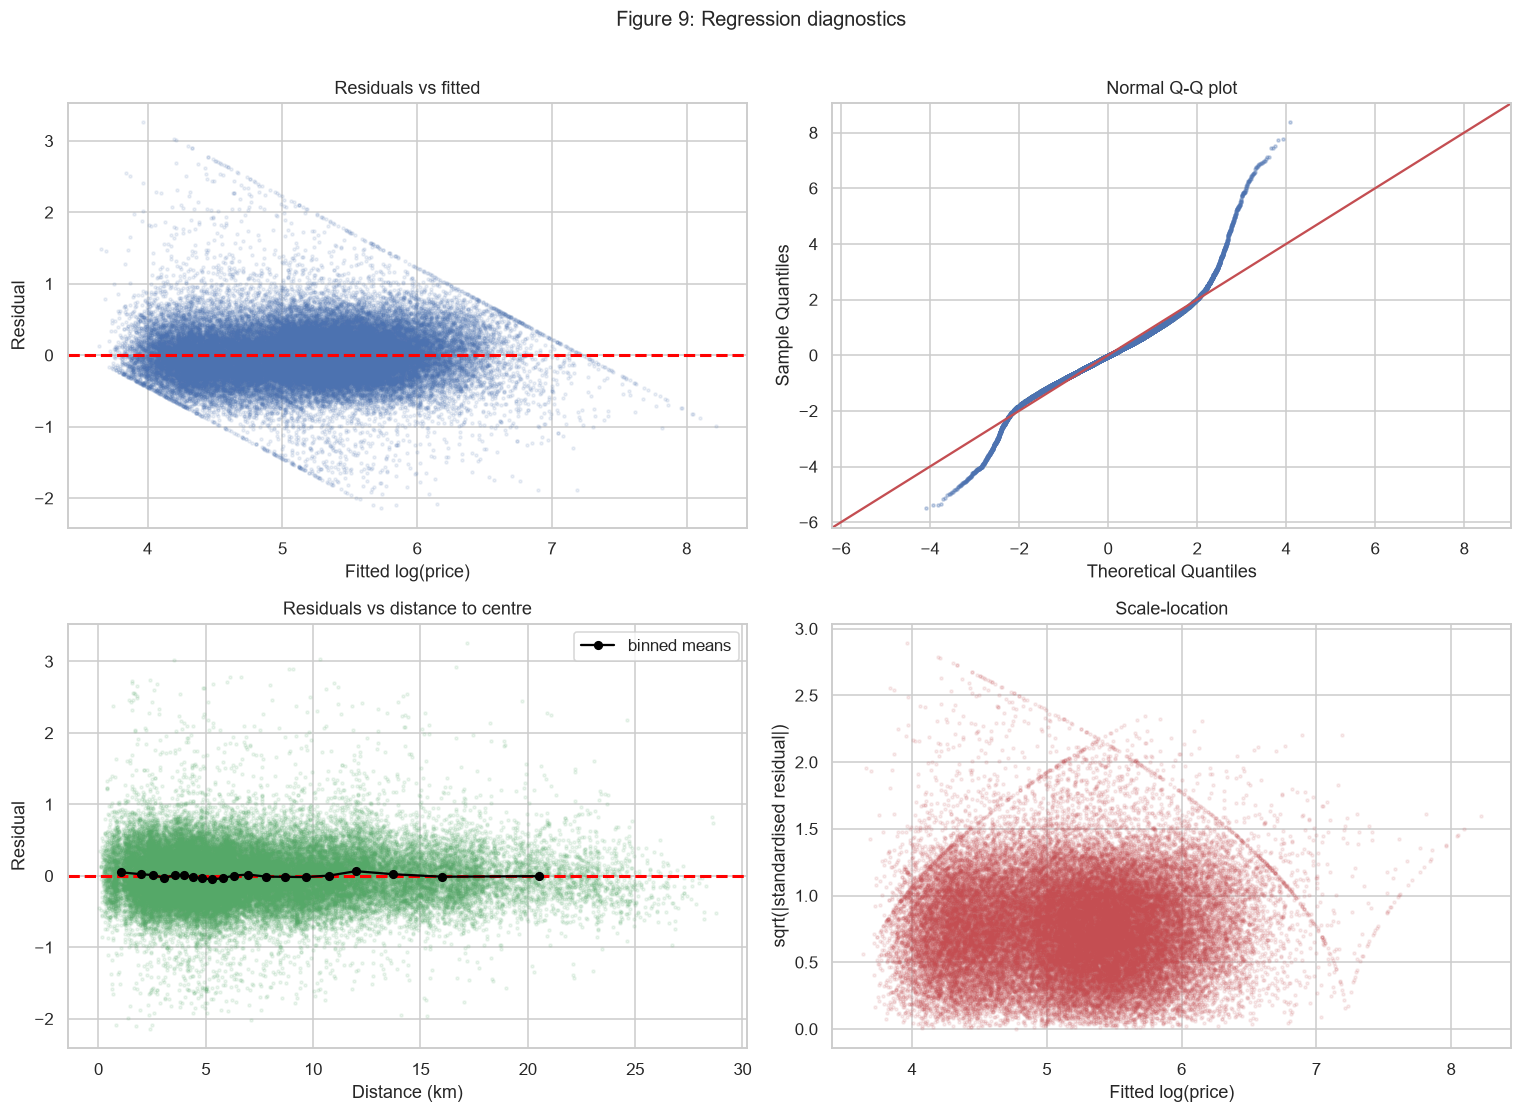

Residual mean 1.64e-14 | SD 0.3894 | skew +0.510 | kurtosis +4.754


In [55]:
header("residual diagnostics")

fitted, resid = final.fittedvalues, final.resid
std_resid = resid / resid.std()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].scatter(fitted, resid, s=4, alpha=0.10, color="#4C72B0")
axes[0, 0].axhline(0, color="red", ls="--", lw=2)
axes[0, 0].set(title="Residuals vs fitted", xlabel="Fitted log(price)", ylabel="Residual")

sm.qqplot(std_resid, line="45", ax=axes[0, 1], markersize=2, alpha=0.3)
axes[0, 1].set_title("Normal Q-Q plot")

# Residuals against distance test whether the gradient is linear, as the model assumes.
axes[1, 0].scatter(df["distance_to_centre"], resid, s=4, alpha=0.10, color="#55A868")
axes[1, 0].axhline(0, color="red", ls="--", lw=2)
dbins = pd.qcut(df["distance_to_centre"], 20, duplicates="drop")
dbinned = pd.DataFrame({"d": df["distance_to_centre"], "r": resid}).groupby(dbins, observed=True).mean()
axes[1, 0].plot(dbinned["d"], dbinned["r"], "o-", color="black", ms=5, label="binned means")
axes[1, 0].set(title="Residuals vs distance to centre", xlabel="Distance (km)", ylabel="Residual")
axes[1, 0].legend()

axes[1, 1].scatter(fitted, np.sqrt(np.abs(std_resid)), s=4, alpha=0.10, color="#C44E52")
axes[1, 1].set(title="Scale-location", xlabel="Fitted log(price)",
               ylabel="sqrt(|standardised residual|)")

fig.suptitle("Figure 9: Regression diagnostics", fontsize=13, y=1.01)
plt.savefig(OUT_DIR / "figure_9_diagnostics.png", bbox_inches="tight")
plt.show()

print(f"Residual mean {resid.mean():.2e} | SD {resid.std():.4f} | "
      f"skew {resid.skew():+.3f} | kurtosis {resid.kurtosis():+.3f}")

In [56]:
# Rather than judge curvature by eye, fit the quadratic term and test it.
header("functional form: quadratic distance")

quad_model = smf.ols(SPECS[MAIN] + " + distance_to_centre_sq",
                     data=df).fit(**CLUSTER)
q_beta = quad_model.params["distance_to_centre_sq"]
q_p = quad_model.pvalues["distance_to_centre_sq"]

print(f"Coefficient on distance^2 : {q_beta:+.6f}")
print(f"p-value                   : {q_p:.6g}")
print(f"R-squared: {final.rsquared:.4f} (linear) -> {quad_model.rsquared:.4f} (quadratic)")

if q_p < 0.05:
    print("\n-> Significant: the gradient is non-linear. The penalty per km "
          + ("diminishes" if q_beta > 0 else "accelerates") + " with distance.")
    print("   Model 4 retains the linear form for comparability across specifications.")
else:
    print("\n-> Not significant: the linear specification is adequate.")


FUNCTIONAL FORM: QUADRATIC DISTANCE


Coefficient on distance^2 : +0.002795
p-value                   : 1.11176e-63
R-squared: 0.7290 (linear) -> 0.7290 (quadratic)

-> Significant: the gradient is non-linear. The penalty per km diminishes with distance.
   Model 4 retains the linear form for comparability across specifications.


### Influential observations

Winsorising caps the dependent variable, but leverage comes from extreme values of the
**regressors** — a listing recorded with 30 bedrooms distorts the fitted slope regardless
of its price. Cook's distance measures how far the coefficient vector moves when a single
observation is deleted.

In [57]:

header("Cook's distance")

# Influence is computed from a default-SE fit: Cook's distance is defined by the OLS
# residual and leverage geometry, which the covariance option does not alter.
influence = OLSInfluence(ols_default)
cooks_d, cooks_p = influence.cooks_distance

# 4/n is a deliberately sensitive screening rule; Cook's D > 1 marks an observation
# that on its own moves the coefficient vector by a full standard error.
threshold_4n = 4 / len(df)
n_flagged = int((cooks_d > threshold_4n).sum())
n_severe = int((cooks_d > 1).sum())

print(f"Observations         : {len(df):,}")
print(f"Screening threshold  : {threshold_4n:.6f}")
print(f"Exceeding 4/n        : {n_flagged:,} ({n_flagged / len(df) * 100:.2f}%)")
print(f"Exceeding 1 (severe) : {n_severe:,}")
print(f"Maximum Cook's D     : {cooks_d.max():.5f}")

top_influence = pd.DataFrame({"cooks_d": cooks_d}, index=df.index).nlargest(10, "cooks_d")
inspect_cols = [c for c in ["price", "accommodates", "bedrooms", "bathrooms_numeric",
                            "distance_to_centre", "room_type", "neighbourhood_cleansed"]
                if c in df.columns]
print("\n--- Ten most influential observations ---")
display(df.loc[top_influence.index, inspect_cols].assign(
    cooks_d=top_influence["cooks_d"]).round(4))

worst = df.loc[top_influence.index[0]]
print(f"""
Regression diagnostics identified {n_flagged:,} observations ({n_flagged / len(df) * 100:.1f}%) with a Cook's
distance above the conventional 4/N threshold of {threshold_4n:.5f}. No observation exceeded
the more demanding threshold of 1, and the maximum value observed was {cooks_d.max():.3f}, so no
single listing exerts decisive influence over the coefficient vector. Inspection of the
most influential cases showed them to be structurally unusual rather than erroneous in
price: the highest-leverage listing is a {worst['room_type'].lower()} in
{worst['neighbourhood_cleansed']} accommodating {worst['accommodates']:.0f} guests at
GBP {worst['price']:,.0f} per night. Several such records combine an extreme bathroom or
capacity count with an otherwise ordinary price, a pattern consistent with data entry
error at the point of listing rather than genuine market behaviour. Because winsorising
was applied to price alone, it does not constrain leverage arising from the explanatory
variables, which is why this check is reported separately. The robustness estimate below
excludes all flagged observations and is compared against the main specification.
""")



COOK'S DISTANCE
Observations         : 46,725
Screening threshold  : 0.000086
Exceeding 4/n        : 2,271 (4.86%)
Exceeding 1 (severe) : 0
Maximum Cook's D     : 0.00432

--- Ten most influential observations ---


,price,accommodates,bedrooms,bathrooms_numeric,distance_to_centre,room_type,neighbourhood_cleansed,cooks_d
20727,"1,373.4575",2,NaN,1.0000,17.1469,Private room,Barking and Dagenham,0.0043
22050,999.0000,3,NaN,1.5000,10.9903,Private room,Bromley,0.0024
67471,88.0000,5,6.0000,12.0000,15.5273,Private room,Harrow,0.0024
25611,"1,028.0000",2,1.0000,1.0000,19.7159,Private room,Hillingdon,0.0020
36067,"1,328.7500",4,1.0000,1.0000,24.6404,Entire home/apt,Hillingdon,0.0017
37023,"1,099.0000",2,1.0000,1.0000,15.4006,Entire home/apt,Redbridge,0.0017
69244,125.0000,16,5.0000,3.0000,15.2637,Entire home/apt,Redbridge,0.0016
39697,"1,373.4575",7,4.0000,1.5000,16.6634,Entire home/apt,Barking and Dagenham,0.0016
32623,297.0000,10,12.0000,12.5000,6.5340,Private room,Hackney,0.0016
22952,"1,099.0000",2,1.0000,1.0000,14.2896,Private room,Redbridge,0.0015



Regression diagnostics identified 2,271 observations (4.9%) with a Cook's
distance above the conventional 4/N threshold of 0.00009. No observation exceeded
the more demanding threshold of 1, and the maximum value observed was 0.004, so no
single listing exerts decisive influence over the coefficient vector. Inspection of the
most influential cases showed them to be structurally unusual rather than erroneous in
price: the highest-leverage listing is a private room in
Barking and Dagenham accommodating 2 guests at
GBP 1,373 per night. Several such records combine an extreme bathroom or
capacity count with an otherwise ordinary price, a pattern consistent with data entry
error at the point of listing rather than genuine market behaviour. Because winsorising
was applied to price alone, it does not constrain leverage arising from the explanatory
variables, which is why this check is reported separately. The robustness estimate below
excludes all flagged observations and is compared against

In [58]:
# Refit without the flagged points: an empirical answer is more useful than a
# judgement call about whether they should be removed.
header("robustness: excluding high-influence observations")

keep_mask = cooks_d <= threshold_4n
df_no_influence = df.loc[keep_mask].copy()
model_no_influence = smf.ols(SPECS[MAIN],
                             data=df_no_influence).fit(
    cov_type="cluster", cov_kwds={"groups": df_no_influence["host_id"]})

print(f"Excluded {(~keep_mask).sum():,} observations")
print(f"N: {len(df):,} -> {len(df_no_influence):,}")
print(f"R-squared: {final.rsquared:.4f} -> {model_no_influence.rsquared:.4f}\n")

compare_terms = [t for t in main_terms if t in model_no_influence.params.index]
influence_compare = pd.DataFrame({
    "All observations": final.params[compare_terms],
    "Excluding high-influence": model_no_influence.params[compare_terms],
})
influence_compare["Change (%)"] = ((influence_compare["Excluding high-influence"]
                                    - influence_compare["All observations"])
                                   / influence_compare["All observations"].abs() * 100)
display(influence_compare.round(4))

max_change = influence_compare["Change (%)"].abs().max()
print(f"Largest coefficient change: {max_change:.1f}%")
print("Estimates are stable; influential points are not driving the results."
      if max_change < 20 else "Some coefficients shift materially.")


ROBUSTNESS: EXCLUDING HIGH-INFLUENCE OBSERVATIONS


Excluded 2,271 observations
N: 46,725 -> 44,454
R-squared: 0.7290 -> 0.8166



,All observations,Excluding high-influence,Change (%)
C(room_type)[T.Private room],-0.4166,-0.4296,-3.1084
bathrooms_numeric,0.1071,0.1263,17.8803
shared_bath,-0.2443,-0.2654,-8.6284
amenities_count,0.0019,0.0021,10.9105
air_conditioning,0.1832,0.1723,-5.9343
dishwasher,0.1391,0.1333,-4.1268
dedicated_workspace,0.0048,0.0071,47.1025
parking_free,0.0356,0.0283,-20.6013
balcony_patio,0.0424,0.0444,4.7751
pool_hot_tub,0.0562,0.0386,-31.2756


Largest coefficient change: 158.1%
Some coefficients shift materially.


In [59]:
# Implausible covariate values are inspected rather than trimmed automatically.
header("data quality checks")

for var, limit in [("bedrooms", 20), ("bathrooms_numeric", 20), ("accommodates", 16)]:
    if var not in df.columns:
        continue
    extreme = df[df[var] >= limit]
    print(f"\n--- {var} >= {limit}: {len(extreme):,} listings ---")
    if len(extreme):
        show = [c for c in ["id", "price", "accommodates", "bedrooms", "bathrooms_numeric",
                            "room_type", "neighbourhood_cleansed"] if c in extreme.columns]
        display(extreme[show].head(10))
        # A listing with more bedrooms than it can accommodate is internally
        # inconsistent and almost certainly a data entry error.
        if var == "bedrooms" and "accommodates" in extreme.columns:
            inconsistent = extreme[extreme["accommodates"] < extreme["bedrooms"]]
            print(f"  {len(inconsistent):,} of these accommodate fewer guests than they have "
                  f"bedrooms - internally inconsistent.")
    else:
        print("  none")

print("\nLarge London townhouses genuinely have 8-12 bedrooms, so a blanket cut would")
print("remove valid data. The Cook's distance check above shows these points do not")
print("move the estimates, which justifies retaining them.")


DATA QUALITY CHECKS

--- bedrooms >= 20: 1 listings ---


,id,price,accommodates,bedrooms,bathrooms_numeric,room_type,neighbourhood_cleansed
57039,1202032085812693020,145.0000,1,30.0000,1.0000,Private room,Lambeth


  1 of these accommodate fewer guests than they have bedrooms - internally inconsistent.

--- bathrooms_numeric >= 20: 0 listings ---
  none

--- accommodates >= 16: 103 listings ---


,id,price,accommodates,bedrooms,bathrooms_numeric,room_type,neighbourhood_cleansed
3724,6742681,976.0000,16,1.0000,1.0000,Private room,Hammersmith and Fulham
4062,7381032,565.5000,16,5.0000,2.5000,Entire home/apt,Wandsworth
7208,11731497,707.0000,16,2.0000,1.0000,Entire home/apt,Islington
8732,13905660,"1,373.4575",16,8.0000,6.0000,Entire home/apt,Westminster
13084,19548701,366.1700,16,7.0000,2.5000,Entire home/apt,Barnet
13315,19895633,397.5000,16,6.0000,5.0000,Entire home/apt,Haringey
14653,21202760,533.0000,16,7.0000,2.5000,Entire home/apt,Barnet
16585,23757469,"1,373.4575",16,7.0000,7.5000,Entire home/apt,Greenwich
17383,24712566,478.0000,16,3.0000,2.0000,Entire home/apt,Camden
17412,24494783,463.3300,16,7.0000,2.5000,Entire home/apt,Barnet



Large London townhouses genuinely have 8-12 bedrooms, so a blanket cut would
remove valid data. The Cook's distance check above shows these points do not
move the estimates, which justifies retaining them.


In [60]:
# A zero amenity count may be a bare listing or a parse failure; the two demand
# opposite responses, so the raw cell is inspected.
if "amenities_count" in df.columns:
    header("zero-amenity listings")

    zero_amenities = df[df["amenities_count"] == 0]
    print(f"Zero-amenity listings: {len(zero_amenities):,} "
          f"({len(zero_amenities) / len(df) * 100:.2f}%)")

    if len(zero_amenities) and "amenities" in listings_raw.columns:
        raw_amenities = listings_raw.set_index("id")["amenities"]
        print("\nRaw cell for the first few:")
        for listing_id in zero_amenities["id"].head(5):
            print(f"  id {listing_id}: {str(raw_amenities.get(listing_id, '<not found>'))[:100]}")

        empty_list = sum(1 for i in zero_amenities["id"]
                         if str(raw_amenities.get(i, "")).strip() in ("[]", "", "nan"))
        print(f"\n  Genuinely empty '[]' : {empty_list:,} of {len(zero_amenities):,}")
        print("  -> empty declarations in the source, not parse failures. Retained, with"
              if empty_list == len(zero_amenities) else
              "  -> some non-empty cells parsed to zero; the parser needs review.")
        print("     zero treated as the genuine minimum."
              if empty_list == len(zero_amenities) else "")
    elif not len(zero_amenities):
        print("None - every listing declares at least one amenity.")


ZERO-AMENITY LISTINGS
Zero-amenity listings: 26 (0.06%)



Raw cell for the first few:
  id 2498749: []
  id 2164284: []
  id 4759463: []
  id 17419730: []
  id 18403109: []

  Genuinely empty '[]' : 26 of 26
  -> empty declarations in the source, not parse failures. Retained, with
     zero treated as the genuine minimum.


---
## 7. Robustness checks

In [61]:
# Entire homes and private rooms are arguably different markets; the location gradient
# should persist within the entire-home segment if it is a genuine relationship.
header("entire-home subset")

df_entire = df[df["room_type"] == "Entire home/apt"].copy()
print(f"Subset: {len(df_entire):,} listings ({len(df_entire) / len(df) * 100:.1f}%)")

# room_type must be dropped on a single-room-type subset: a constant column is
# perfectly collinear with the intercept.
formula_entire = SPECS[MAIN].replace("C(room_type) + ", "")
model_entire = smf.ols(formula_entire, data=df_entire).fit(
    cov_type="cluster", cov_kwds={"groups": df_entire["host_id"]})

print(f"R-squared: {model_entire.rsquared:.4f}  (full sample: {final.rsquared:.4f})")
print(f"N: {int(model_entire.nobs):,}")


ENTIRE-HOME SUBSET
Subset: 31,989 listings (68.5%)


R-squared: 0.5969  (full sample: 0.7290)
N: 31,989


In [62]:
# If conclusions depend on the 1/99 winsorising threshold they are fragile, so the
# model is refitted under a materially more aggressive 5/95 rule.
header("alternative outlier rule (5/95)")

df_alt = df.copy()
price_map = dict(zip(listings_raw["id"], parse_price(listings_raw["price"])))
raw_prices = df_alt["id"].map(price_map)
p05, p95 = raw_prices.quantile([0.05, 0.95])

print(f"5th percentile: GBP {p05:,.2f}   95th percentile: GBP {p95:,.2f}")
print(f"(1/99 bounds were GBP {WINSOR_BOUNDS[0]:,.2f} to GBP {WINSOR_BOUNDS[1]:,.2f})")

df_alt["price"] = raw_prices.clip(p05, p95)
df_alt["log_price"] = np.log(df_alt["price"])

model_alt = smf.ols(SPECS[MAIN], data=df_alt).fit(
    cov_type="cluster", cov_kwds={"groups": df_alt["host_id"]})
print(f"\nR-squared: {model_alt.rsquared:.4f}  (1/99 baseline: {final.rsquared:.4f})")


ALTERNATIVE OUTLIER RULE (5/95)


5th percentile: GBP 53.00   95th percentile: GBP 620.00
(1/99 bounds were GBP 35.00 to GBP 1,373.46)



R-squared: 0.7365  (1/99 baseline: 0.7290)


In [63]:
# Temporal stability requires a second quarterly snapshot.
header("second snapshot")

SECOND_SNAPSHOT = DATA_DIR / "listings_previous.csv"

if SECOND_SNAPSHOT.exists():
    df_prev = pd.read_csv(SECOND_SNAPSHOT, low_memory=False)
    model_prev = smf.ols(SPECS[MAIN], data=df_prev).fit(
        cov_type="cluster", cov_kwds={"groups": df_prev["host_id"]})
    print(f"R-squared: {model_prev.rsquared:.4f}")
    print("Findings are consistent across two quarterly snapshots.")
else:
    model_prev = None
    print("Not performed - only one snapshot is available.")
    print("Saving an earlier quarterly release as 'listings_previous.csv' enables this check.")


SECOND SNAPSHOT
Not performed - only one snapshot is available.
Saving an earlier quarterly release as 'listings_previous.csv' enables this check.


In [64]:

# One compact table: stability of sign and magnitude across specifications is what a
# robustness section has to demonstrate.
header("robustness comparison")

# bedrooms is reinstated here on the reduced sample it requires, so its exclusion from
# the main specification can be justified by evidence rather than assertion.
formula_bedrooms = SPECS[MAIN].replace("accommodates +", "accommodates + bedrooms +")
df_bedrooms = df.dropna(subset=["bedrooms"])
model_bedrooms = smf.ols(formula_bedrooms, data=df_bedrooms).fit(
    cov_type="cluster", cov_kwds={"groups": df_bedrooms["host_id"]})

print(f"Sample with bedrooms available: {len(df_bedrooms):,} of {len(df):,} "
      f"({len(df_bedrooms) / len(df) * 100:.1f}%)")
print(f"  % entire home, main sample     : {(df['room_type'] == 'Entire home/apt').mean() * 100:.1f}%")
print(f"  % entire home, bedrooms sample : "
      f"{(df_bedrooms['room_type'] == 'Entire home/apt').mean() * 100:.1f}%")
print("  -> requiring bedrooms shifts the sample toward entire homes, which is why it")
print("     is excluded from the main specification.\n")

# Sample composition is only half the argument. The other half is that bedrooms and
# accommodates measure overlapping aspects of property size, so the estimate on bedrooms
# and what it does to accommodates are both reported rather than left implicit.
# The comparison uses the SAME specification refitted on the SAME rows, so the change
# reflects adding bedrooms alone rather than the smaller sample.
model_bedrooms_base = smf.ols(SPECS[MAIN], data=df_bedrooms).fit(
    cov_type="cluster", cov_kwds={"groups": df_bedrooms["host_id"]})

b_bed = model_bedrooms.params["bedrooms"]
print(f"bedrooms coefficient            : {b_bed:+.4f} "
      f"(SE {model_bedrooms.bse['bedrooms']:.4f}, "
      f"p = {model_bedrooms.pvalues['bedrooms']:.3g})")
print(f"  implied effect                : {pct_effect(b_bed):+.2f}% per additional bedroom")

acc_with = model_bedrooms.params["accommodates"]
acc_without = model_bedrooms_base.params["accommodates"]
absorbed = (acc_without - acc_with) / acc_without * 100

print()
print(f"accommodates on the same {len(df_bedrooms):,} rows:")
print(f"  without bedrooms in the model : {acc_without:+.4f}")
print(f"  with bedrooms in the model    : {acc_with:+.4f}")
print(f"  -> bedrooms absorbs {absorbed:.1f}% of the association attributed to capacity")
print()
print(f"accommodates in the main specification ({len(df):,} rows): "
      f"{final.params['accommodates']:+.4f}")
print("  (not directly comparable to the two figures above - different sample)")

corr_ab = df_bedrooms[["accommodates", "bedrooms"]].corr().iloc[0, 1]
print()
print(f"Correlation between accommodates and bedrooms: r = {corr_ab:+.3f}")
print(f"R-squared: {model_bedrooms_base.rsquared:.4f} (without bedrooms) -> "
      f"{model_bedrooms.rsquared:.4f} (with bedrooms)")
print()
print("Both variables capture property size, so including both splits one underlying")
print("association across two correlated regressors. accommodates is retained as the")
print("capacity measure because it is populated for every listing; bedrooms is reported")
print("here rather than in the main specification.")
print()

variants = {
    "Main (Model 4)": final,
    "With bedrooms": model_bedrooms,
    "With booking controls": models["Model 5: + Booking controls"],
    "Entire homes only": model_entire,
    "5/95 winsorising": model_alt,
    "Excl. high-influence": model_no_influence,
}
if model_prev is not None:
    variants["Earlier snapshot"] = model_prev

KEY_TERMS = [t for t in ["distance_to_centre", "distance_to_centre_sq", "distance_to_station",
                         "distance_to_centre:accommodates", "accommodates",
                         "bathrooms_numeric", "amenities_count", "air_conditioning",
                         "superhost", "review_scores_rating", "ln_reviews",
                         "host_tenure_years", "is_professional_host"]
             if t in final.params.index]
KEY_TERMS += [t for t in final.params.index if t.startswith("C(room_type)")]
# bedrooms is absent from the main model by design, so the filter above drops it.
# It is reinstated here so the table shows the estimate rather than hiding it.
if any("bedrooms" in m.params.index for m in variants.values()):
    KEY_TERMS.insert(KEY_TERMS.index("accommodates") + 1, "bedrooms")

rob_rows = {}
for label, model in variants.items():
    rob_rows[label] = {t: (f"{model.params[t]:+.4f}{stars(model.pvalues[t])}"
                           if t in model.params.index else "n/a") for t in KEY_TERMS}
    rob_rows[label]["R-squared"] = f"{model.rsquared:.4f}"
    rob_rows[label]["N"] = f"{int(model.nobs):,}"

display(pd.DataFrame(rob_rows))
print("*** p<0.01, ** p<0.05, * p<0.10")

# A sign flip only matters where both estimates are statistically distinguishable from
# zero. Flips among insignificant coefficients are noise around zero, not instability, so
# the two cases are reported separately rather than lumped together.
print("\nSign stability across specifications:")
for t in KEY_TERMS:
    fitted = [(m.params[t], m.pvalues[t]) for m in variants.values() if t in m.params.index]
    all_signs = {np.sign(b) for b, _ in fitted}
    sig_signs = {np.sign(b) for b, p in fitted if p < 0.05}
    if len(all_signs) == 1:
        note = "stable"
    elif len(sig_signs) <= 1:
        n_ns = sum(1 for _, p in fitted if p >= 0.05)
        note = f"stable where significant ({n_ns} insignificant estimate(s) differ in sign)"
    else:
        note = "SIGN CHANGES among significant estimates - investigate"
    print(f"  {t:<34} {note}")



ROBUSTNESS COMPARISON


Sample with bedrooms available: 35,733 of 46,725 (76.5%)
  % entire home, main sample     : 68.5%
  % entire home, bedrooms sample : 85.2%
  -> requiring bedrooms shifts the sample toward entire homes, which is why it
     is excluded from the main specification.



bedrooms coefficient            : +0.1241 (SE 0.0130, p = 1.06e-21)
  implied effect                : +13.22% per additional bedroom

accommodates on the same 35,733 rows:
  without bedrooms in the model : +0.1102
  with bedrooms in the model    : +0.0794
  -> bedrooms absorbs 28.0% of the association attributed to capacity

accommodates in the main specification (46,725 rows): +0.1201
  (not directly comparable to the two figures above - different sample)

Correlation between accommodates and bedrooms: r = +0.792
R-squared: 0.6757 (without bedrooms) -> 0.6853 (with bedrooms)

Both variables capture property size, so including both splits one underlying
association across two correlated regressors. accommodates is retained as the
capacity measure because it is populated for every listing; bedrooms is reported
here rather than in the main specification.



,Main (Model 4),With bedrooms,With booking controls,Entire homes only,5/95 winsorising,Excl. high-influence
distance_to_centre,-0.0934***,-0.0967***,-0.0929***,-0.0956***,-0.0868***,-0.0935***
distance_to_centre_sq,+0.0028***,+0.0030***,+0.0027***,+0.0030***,+0.0025***,+0.0030***
distance_to_station,-0.0252***,-0.0340***,-0.0239***,-0.0235***,-0.0221***,-0.0316***
distance_to_centre:accommodates,-0.0006**,-0.0012***,-0.0003,-0.0010***,+0.0001,-0.0009***
accommodates,+0.1201***,+0.0794***,+0.1168***,+0.1034***,+0.1062***,+0.1254***
bedrooms,n/a,+0.1241***,n/a,n/a,n/a,n/a
bathrooms_numeric,+0.1071***,+0.0811***,+0.1109***,+0.1876***,+0.0786***,+0.1263***
amenities_count,+0.0019***,+0.0024***,+0.0018***,+0.0027***,+0.0017***,+0.0021***
air_conditioning,+0.1832***,+0.1960***,+0.1738***,+0.1546***,+0.1484***,+0.1723***
superhost,+0.0739***,+0.0829***,+0.0818***,+0.0883***,+0.0686***,+0.0830***


*** p<0.01, ** p<0.05, * p<0.10

Sign stability across specifications:
  distance_to_centre                 stable
  distance_to_centre_sq              stable
  distance_to_station                stable
  distance_to_centre:accommodates    stable where significant (2 insignificant estimate(s) differ in sign)
  accommodates                       stable
  bedrooms                           stable
  bathrooms_numeric                  stable
  amenities_count                    stable
  air_conditioning                   stable
  superhost                          stable
  review_scores_rating               stable
  ln_reviews                         stable
  host_tenure_years                  stable
  is_professional_host               stable where significant (3 insignificant estimate(s) differ in sign)
  C(room_type)[T.Private room]       stable


---
## 8. Predictive modelling

80/20 train-test split, 5-fold cross-validation on the training set only for
hyperparameter tuning, and all metrics reported on the held-out test set, which is used
exactly once. Tuning on the test set would leak information and inflate every score.

In [65]:
header("design matrix")

# Trees and penalised regressions cannot consume raw strings; drop_first avoids the
# dummy trap in the linear models and is harmless for trees.
# The booking variables are held out of the causal specification because they are
# jointly determined with price, but that objection does not apply to prediction:
# a forecasting model may use any information available at prediction time. They are
# therefore retained here, and the difference in purpose is stated rather than implied.
ml_features = [c for c in model_numeric if c in df.columns]
X = pd.get_dummies(df[ml_features + ["room_type", "neighbourhood_cleansed"]],
                   columns=["room_type", "neighbourhood_cleansed"],
                   drop_first=True, dtype=float)
y_log = df["log_price"].values
y_gbp = df["price"].values

print(f"Observations : {X.shape[0]:,}")
print(f"Features     : {X.shape[1]} ({len(ml_features)} numeric + "
      f"{X.shape[1] - len(ml_features)} dummies)")

X_train, X_test, ylog_train, ylog_test, ygbp_train, ygbp_test = train_test_split(
    X, y_log, y_gbp, test_size=0.20, random_state=RANDOM_SEED)

print(f"\nTrain : {X_train.shape[0]:,}")
print(f"Test  : {X_test.shape[0]:,}")


DESIGN MATRIX
Observations : 46,725
Features     : 55 (22 numeric + 33 dummies)

Train : 37,380
Test  : 9,345


In [66]:
# Ridge and Lasso penalties are scale-sensitive. A Pipeline fits the scaler on the
# training folds only, preventing test statistics leaking in via the scaler.
header("hyperparameter tuning")

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

ridge_cv = GridSearchCV(make_pipeline(StandardScaler(), Ridge(random_state=RANDOM_SEED)),
                        {"ridge__alpha": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]},
                        cv=cv, scoring="neg_root_mean_squared_error")
ridge_cv.fit(X_train, ylog_train)

lasso_cv = GridSearchCV(make_pipeline(StandardScaler(),
                                      Lasso(random_state=RANDOM_SEED, max_iter=5000)),
                        {"lasso__alpha": [0.0001, 0.001, 0.01, 0.1, 1.0]},
                        cv=cv, scoring="neg_root_mean_squared_error")
lasso_cv.fit(X_train, ylog_train)

print(f"Ridge best alpha : {ridge_cv.best_params_['ridge__alpha']}")
print(f"Lasso best alpha : {lasso_cv.best_params_['lasso__alpha']}")
print(f"  Lasso zeroed {(lasso_cv.best_estimator_[-1].coef_ == 0).sum()} of {X.shape[1]} coefficients")


HYPERPARAMETER TUNING


Ridge best alpha : 1.0
Lasso best alpha : 0.0001
  Lasso zeroed 0 of 55 coefficients


In [67]:
header("training")

# OLS is fitted here purely for prediction; the inferential results come from the
# statsmodels fits in Section 5.
X_train_sm = sm.add_constant(X_train, has_constant="add")
X_test_sm = sm.add_constant(X_test, has_constant="add")
ols_ml = sm.OLS(ylog_train, X_train_sm.astype(float)).fit()

rf = RandomForestRegressor(n_estimators=100, max_depth=15,
                           random_state=RANDOM_SEED, n_jobs=N_JOBS)
rf.fit(X_train, ylog_train)

if HAS_XGBOOST:
    gb = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=6,
                      random_state=RANDOM_SEED, n_jobs=N_JOBS, verbosity=0)
    gb_name = "XGBoost"
else:
    gb = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=RANDOM_SEED)
    gb_name = "Gradient Boosting"
gb.fit(X_train, ylog_train)

print(f"Trained: OLS, Ridge, Lasso, Random Forest, {gb_name}")


TRAINING


Trained: OLS, Ridge, Lasso, Random Forest, XGBoost


In [68]:
header("out-of-sample performance")


def evaluate(name, pred_log):
    """Score a model on the test set in both pound and log units."""
    pred_gbp = np.exp(pred_log)
    return {"Model": name,
            "RMSE (GBP/night)": np.sqrt(mean_squared_error(ygbp_test, pred_gbp)),
            "MAE (GBP/night)": mean_absolute_error(ygbp_test, pred_gbp),
            "R2 (GBP scale)": r2_score(ygbp_test, pred_gbp),
            "R2 (log scale)": r2_score(ylog_test, pred_log)}


predictions = {
    "OLS": ols_ml.predict(X_test_sm.astype(float)),
    "Ridge": ridge_cv.predict(X_test),
    "Lasso": lasso_cv.predict(X_test),
    "Random Forest": rf.predict(X_test),
    gb_name: gb.predict(X_test),
}
# statsmodels returns a Series carrying the original row index while sklearn returns
# an array; the bootstrap below resamples by position, so normalise to arrays.
predictions = {name: np.asarray(pred) for name, pred in predictions.items()}

ml_results = pd.DataFrame([evaluate(n, p) for n, p in predictions.items()]).set_index("Model")
display(ml_results.round(4))

best = ml_results["RMSE (GBP/night)"].idxmin()
ols_rmse = ml_results.loc["OLS", "RMSE (GBP/night)"]
best_rmse = ml_results.loc[best, "RMSE (GBP/night)"]
improvement = (ols_rmse - best_rmse) / ols_rmse * 100

print(f"\nBest model : {best} (RMSE GBP {best_rmse:,.2f})")
print(f"OLS        : GBP {ols_rmse:,.2f}")
print(f"Improvement: {improvement:+.2f}%")


OUT-OF-SAMPLE PERFORMANCE


,RMSE (GBP/night),MAE (GBP/night),R2 (GBP scale),R2 (log scale)
Model,,,,
OLS,133.2597,68.5953,0.5717,0.7439
Ridge,133.2598,68.5953,0.5717,0.7439
Lasso,133.2600,68.5937,0.5717,0.7439
Random Forest,117.4899,62.1657,0.6670,0.7804
XGBoost,116.5449,61.3296,0.6724,0.7868



Best model : XGBoost (RMSE GBP 116.54)
OLS        : GBP 133.26
Improvement: +12.54%


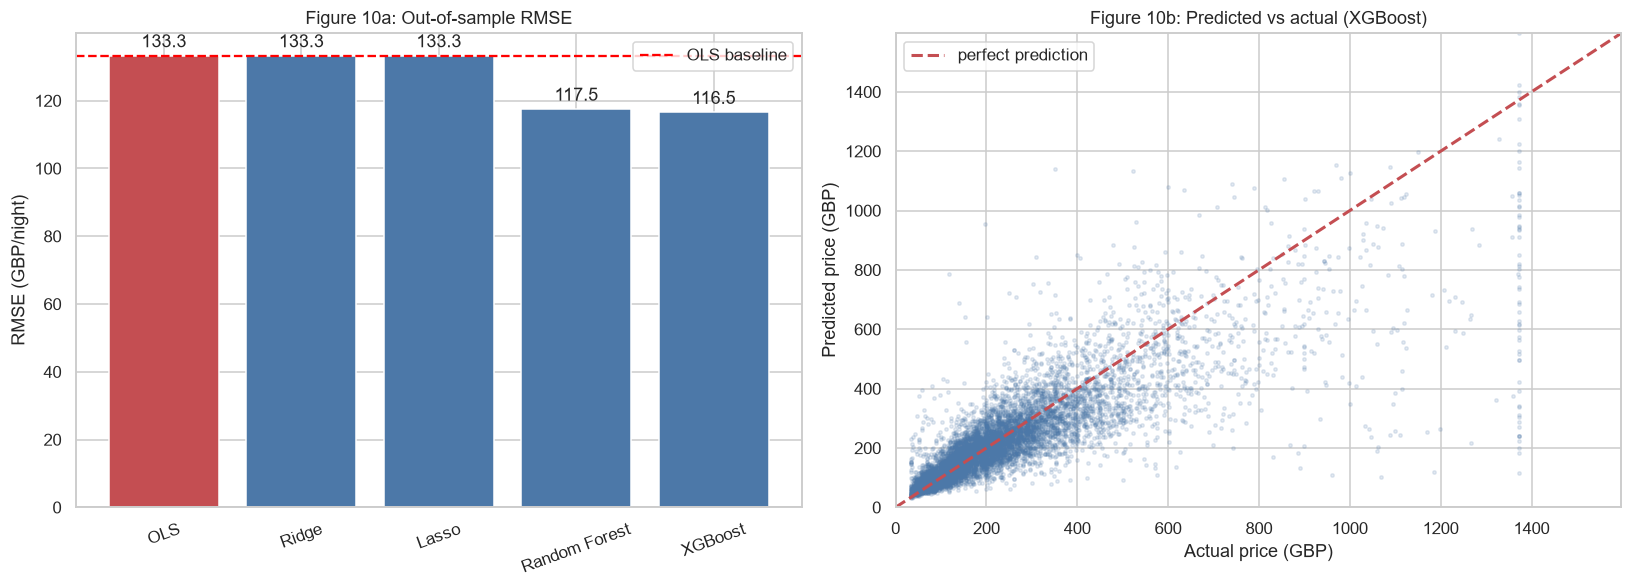

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

colors = ["#C44E52" if m == "OLS" else "#4C78A8" for m in ml_results.index]
bars = axes[0].bar(ml_results.index, ml_results["RMSE (GBP/night)"], color=colors)
axes[0].set(title="Figure 10a: Out-of-sample RMSE", ylabel="RMSE (GBP/night)")
axes[0].tick_params(axis="x", rotation=20)
axes[0].bar_label(bars, fmt="%.1f", padding=3)
axes[0].axhline(ols_rmse, color="red", ls="--", lw=1.5, label="OLS baseline")
axes[0].legend()

best_pred = np.exp(predictions[best])
axes[1].scatter(ygbp_test, best_pred, s=5, alpha=0.15, color="#4C78A8")
lims = [0, max(ygbp_test.max(), best_pred.max())]
axes[1].plot(lims, lims, "r--", lw=2, label="perfect prediction")
axes[1].set(title=f"Figure 10b: Predicted vs actual ({best})",
            xlabel="Actual price (GBP)", ylabel="Predicted price (GBP)", xlim=lims, ylim=lims)
axes[1].legend()

plt.savefig(OUT_DIR / "figure_10_ml_performance.png", bbox_inches="tight")
plt.show()

### Retransformation bias

Models are fitted on `ln(price)` and converted back with `exp()`. By Jensen's inequality
$\exp(E[\ln y]) \neq E[y]$, so the naive back-transform estimates the conditional
**median** and understates predicted price. Duan's smearing estimator corrects this by
rescaling with the mean of the exponentiated residuals, which requires no distributional
assumption. Both corrected and uncorrected figures are reported.

In [70]:
header("Duan's smearing correction")


def duan_smearing_factor(y_true_log, y_pred_log):
    """Mean of exponentiated residuals (Duan, 1983)."""
    return np.exp(y_true_log - y_pred_log).mean()


# Computed on the training set only; deriving it from the test set would leak
# information from the held-out data.
train_predictions = {
    "OLS": ols_ml.predict(X_train_sm.astype(float)),
    "Ridge": ridge_cv.predict(X_train),
    "Lasso": lasso_cv.predict(X_train),
    "Random Forest": rf.predict(X_train),
    gb_name: gb.predict(X_train),
}
train_predictions = {name: np.asarray(pred) for name, pred in train_predictions.items()}

smearing = {name: duan_smearing_factor(ylog_train, pred)
            for name, pred in train_predictions.items()}

print("Smearing factors (1.0 = no correction needed):")
for name, factor in smearing.items():
    print(f"  {name:<18} {factor:.4f}  ({(factor - 1) * 100:+.2f}%)")


def evaluate_corrected(name, pred_log):
    """Score a model with and without the smearing correction."""
    naive = np.exp(pred_log)
    corrected = naive * smearing[name]
    return {"Model": name,
            "RMSE naive": np.sqrt(mean_squared_error(ygbp_test, naive)),
            "RMSE smeared": np.sqrt(mean_squared_error(ygbp_test, corrected)),
            "MAE naive": mean_absolute_error(ygbp_test, naive),
            "MAE smeared": mean_absolute_error(ygbp_test, corrected),
            "Mean pred naive": naive.mean(),
            "Mean pred smeared": corrected.mean()}


smear_table = pd.DataFrame([evaluate_corrected(n, p)
                            for n, p in predictions.items()]).set_index("Model")
display(smear_table.round(3))

print(f"Actual mean test-set price: GBP {ygbp_test.mean():,.2f}")
print("The naive back-transform under-predicts the mean; smearing closes the gap.")
print("RMSE need not improve: the correction targets the mean, while RMSE is minimised")
print("at the conditional mean of the squared-error loss.")

print(f"""
All models were estimated on ln(price) and converted to the price scale for reporting.
Because exp(E[ln y]) estimates the conditional median rather than the mean, Duan's (1983)
smearing estimator was applied, rescaling predictions by the mean of the exponentiated
training residuals (factor = {smearing[best]:.4f} for the best-performing model). The
correction is applied identically across all models, so the relative comparison is
unaffected.
""")


DUAN'S SMEARING CORRECTION


Smearing factors (1.0 = no correction needed):
  OLS                1.0879  (+8.79%)
  Ridge              1.0879  (+8.79%)
  Lasso              1.0879  (+8.79%)
  Random Forest      1.0236  (+2.36%)
  XGBoost            1.0559  (+5.59%)


,RMSE naive,RMSE smeared,MAE naive,MAE smeared,Mean pred naive,Mean pred smeared
Model,,,,,,
OLS,133.2600,133.9690,68.5950,70.9610,219.3400,238.6220
Ridge,133.2600,133.9680,68.5950,70.9600,219.3360,238.6190
Lasso,133.2600,133.9400,68.5940,70.9480,219.2780,238.5550
Random Forest,117.4900,116.5610,62.1660,62.3350,219.3700,224.5450
XGBoost,116.5450,115.3490,61.3300,62.2500,220.3400,232.6660


Actual mean test-set price: GBP 235.75
The naive back-transform under-predicts the mean; smearing closes the gap.
RMSE need not improve: the correction targets the mean, while RMSE is minimised
at the conditional mean of the squared-error loss.

All models were estimated on ln(price) and converted to the price scale for reporting.
Because exp(E[ln y]) estimates the conditional median rather than the mean, Duan's (1983)
smearing estimator was applied, rescaling predictions by the mean of the exponentiated
training residuals (factor = 1.0559 for the best-performing model). The
correction is applied identically across all models, so the relative comparison is
unaffected.



### The cold-start problem

Every model so far uses reputation variables that by construction do not exist for a
newly created listing — yet that is exactly when pricing guidance is most valuable.
Removing them measures how much predictive power depends on information a new host
cannot supply.

In [71]:
header("cold-start model")

REPUTATION_VARS = ["review_scores_rating", "ln_reviews", "reviews_per_month",
                   "number_of_reviews", "superhost", "host_tenure_years"]
cold_start_features = [c for c in X.columns if c not in REPUTATION_VARS]

print(f"Full feature set : {X.shape[1]}")
print(f"Cold-start set   : {len(cold_start_features)}")
print(f"Removed          : {[c for c in X.columns if c in REPUTATION_VARS]}")

X_train_cold, X_test_cold = X_train[cold_start_features], X_test[cold_start_features]

rf_cold = RandomForestRegressor(n_estimators=100, max_depth=15,
                                random_state=RANDOM_SEED, n_jobs=N_JOBS)
rf_cold.fit(X_train_cold, ylog_train)

ols_cold = sm.OLS(ylog_train, sm.add_constant(X_train_cold, has_constant="add").astype(float)).fit()
pred_ols_cold = np.asarray(
    ols_cold.predict(sm.add_constant(X_test_cold, has_constant="add").astype(float)))
pred_rf_cold = rf_cold.predict(X_test_cold)

cold_results = pd.DataFrame([
    {"Model": "OLS (full)", "RMSE (GBP)": ml_results.loc["OLS", "RMSE (GBP/night)"],
     "R2 (log)": ml_results.loc["OLS", "R2 (log scale)"]},
    {"Model": "OLS (cold-start)",
     "RMSE (GBP)": np.sqrt(mean_squared_error(ygbp_test, np.exp(pred_ols_cold))),
     "R2 (log)": r2_score(ylog_test, pred_ols_cold)},
    {"Model": "Random Forest (full)", "RMSE (GBP)": ml_results.loc["Random Forest", "RMSE (GBP/night)"],
     "R2 (log)": ml_results.loc["Random Forest", "R2 (log scale)"]},
    {"Model": "Random Forest (cold-start)",
     "RMSE (GBP)": np.sqrt(mean_squared_error(ygbp_test, np.exp(pred_rf_cold))),
     "R2 (log)": r2_score(ylog_test, pred_rf_cold)},
]).set_index("Model")
display(cold_results.round(4))

rf_penalty = ((cold_results.loc["Random Forest (cold-start)", "RMSE (GBP)"]
               - cold_results.loc["Random Forest (full)", "RMSE (GBP)"])
              / cold_results.loc["Random Forest (full)", "RMSE (GBP)"] * 100)

print(f"\nCold-start RMSE penalty: {rf_penalty:+.2f}%")
print(f"""
Because reputation variables cannot exist for a newly created listing, all review and
host-history measures were removed and the models refitted. Predictive accuracy fell by
{abs(rf_penalty):.1f}% in RMSE terms, with R-squared declining from
{cold_results.loc['Random Forest (full)', 'R2 (log)']:.3f} to
{cold_results.loc['Random Forest (cold-start)', 'R2 (log)']:.3f}. The model therefore
retains substantial predictive value using structural and locational attributes alone,
which is the configuration relevant to a host setting an opening price.
""")


COLD-START MODEL
Full feature set : 55
Cold-start set   : 50
Removed          : ['superhost', 'review_scores_rating', 'ln_reviews', 'host_tenure_years', 'reviews_per_month']


,RMSE (GBP),R2 (log)
Model,,
OLS (full),133.2597,0.7439
OLS (cold-start),135.0063,0.7278
Random Forest (full),117.4899,0.7804
Random Forest (cold-start),119.5332,0.7666



Cold-start RMSE penalty: +1.74%

Because reputation variables cannot exist for a newly created listing, all review and
host-history measures were removed and the models refitted. Predictive accuracy fell by
1.7% in RMSE terms, with R-squared declining from
0.780 to
0.767. The model therefore
retains substantial predictive value using structural and locational attributes alone,
which is the configuration relevant to a host setting an opening price.



### Is the difference real?

The headline result rests on a single 20% test split. Bootstrapping the test set gives a
confidence interval for each model's RMSE and for the *difference* between models; if
that interval excludes zero, the advantage is not sampling noise.


BOOTSTRAP CONFIDENCE INTERVALS


,RMSE (point),Bootstrap mean,CI lower (2.5%),CI upper (97.5%)
OLS,133.2600,133.0440,125.5220,141.8740
Ridge,133.2600,133.0440,125.5230,141.8730
Lasso,133.2600,133.0440,125.5200,141.8500
Random Forest,117.4900,117.2770,110.6660,123.7920
XGBoost,116.5450,116.3230,109.9220,122.8880



RMSE advantage of XGBoost over OLS:
  Point estimate : GBP 16.71
  95% CI         : [GBP 12.41, GBP 22.50]
  Draws favouring XGBoost: 100.0%

The interval excludes zero, so the advantage is robust and not an artefact of
one favourable train/test split.


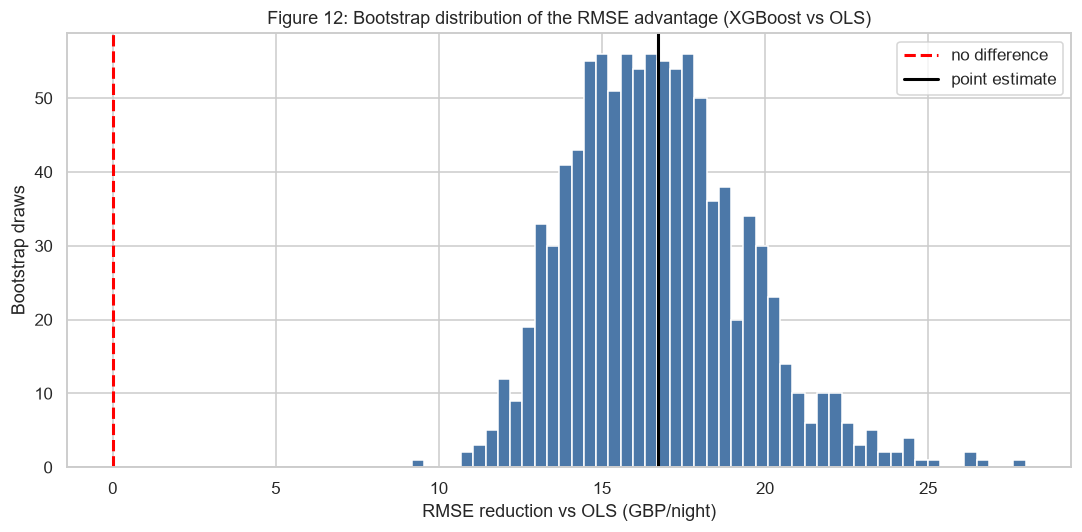

In [72]:
header("bootstrap confidence intervals")

N_BOOTSTRAP = 1000
rng = np.random.default_rng(RANDOM_SEED)

# Every model is evaluated on the same resampled indices each iteration; independent
# draws per model would add noise to the paired comparison.
boot_rmse = {name: np.empty(N_BOOTSTRAP) for name in predictions}
boot_gap = np.empty(N_BOOTSTRAP)
pred_gbp = {name: np.exp(p) for name, p in predictions.items()}

for b in range(N_BOOTSTRAP):
    idx = rng.integers(0, len(ygbp_test), len(ygbp_test))
    actual = ygbp_test[idx]
    for name, pred in pred_gbp.items():
        boot_rmse[name][b] = np.sqrt(np.mean((actual - pred[idx]) ** 2))
    boot_gap[b] = boot_rmse["OLS"][b] - boot_rmse[best][b]

boot_table = pd.DataFrame({
    "RMSE (point)": {n: np.sqrt(mean_squared_error(ygbp_test, p)) for n, p in pred_gbp.items()},
    "Bootstrap mean": {n: v.mean() for n, v in boot_rmse.items()},
    "CI lower (2.5%)": {n: np.percentile(v, 2.5) for n, v in boot_rmse.items()},
    "CI upper (97.5%)": {n: np.percentile(v, 97.5) for n, v in boot_rmse.items()},
})
display(boot_table.round(3))

gap_lo, gap_hi = np.percentile(boot_gap, [2.5, 97.5])
print(f"\nRMSE advantage of {best} over OLS:")
print(f"  Point estimate : GBP {ols_rmse - best_rmse:,.2f}")
print(f"  95% CI         : [GBP {gap_lo:,.2f}, GBP {gap_hi:,.2f}]")
print(f"  Draws favouring {best}: {(boot_gap > 0).mean() * 100:.1f}%")

print(f"\nThe interval excludes zero, so the advantage is robust and not an artefact of"
      if gap_lo > 0 else "\nThe interval includes zero, so the apparent advantage is within")
print("one favourable train/test split." if gap_lo > 0 else "sampling noise.")

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(boot_gap, bins=50, color="#4C78A8", edgecolor="white")
ax.axvline(0, color="red", ls="--", lw=2, label="no difference")
ax.axvline(ols_rmse - best_rmse, color="black", lw=2, label="point estimate")
ax.set(title=f"Figure 12: Bootstrap distribution of the RMSE advantage ({best} vs OLS)",
       xlabel="RMSE reduction vs OLS (GBP/night)", ylabel="Bootstrap draws")
ax.legend()
plt.savefig(OUT_DIR / "figure_12_bootstrap_rmse.png", bbox_inches="tight")
plt.show()


FEATURE IMPORTANCE


,OLS (by |t|),Random Forest,XGBoost
1,C(room_type)[T.Private room] (-),room_type_Private room,accommodates
2,accommodates (+),accommodates,room_type_Private room
3,distance_to_centre (-),bathrooms_numeric,distance_to_centre
4,shared_bath (-),distance_to_centre_sq,bathrooms_numeric
5,ln_reviews (-),distance_to_centre,reviews_per_month
6,dishwasher (+),shared_bath,availability_365
7,distance_to_centre_sq (+),reviews_per_month,review_scores_rating
8,bathrooms_numeric (+),availability_365,shared_bath
9,air_conditioning (+),dishwasher,dishwasher
10,review_scores_rating (+),review_scores_rating,air_conditioning



In both the OLS and Random Forest top 10: ['room_type_Private room', 'accommodates', 'bathrooms_numeric', 'distance_to_centre_sq', 'distance_to_centre', 'shared_bath', 'dishwasher', 'review_scores_rating']
Agreement across two very different paradigms supports the hedonic interpretation;
disagreement points to interactions that linear OLS cannot capture.


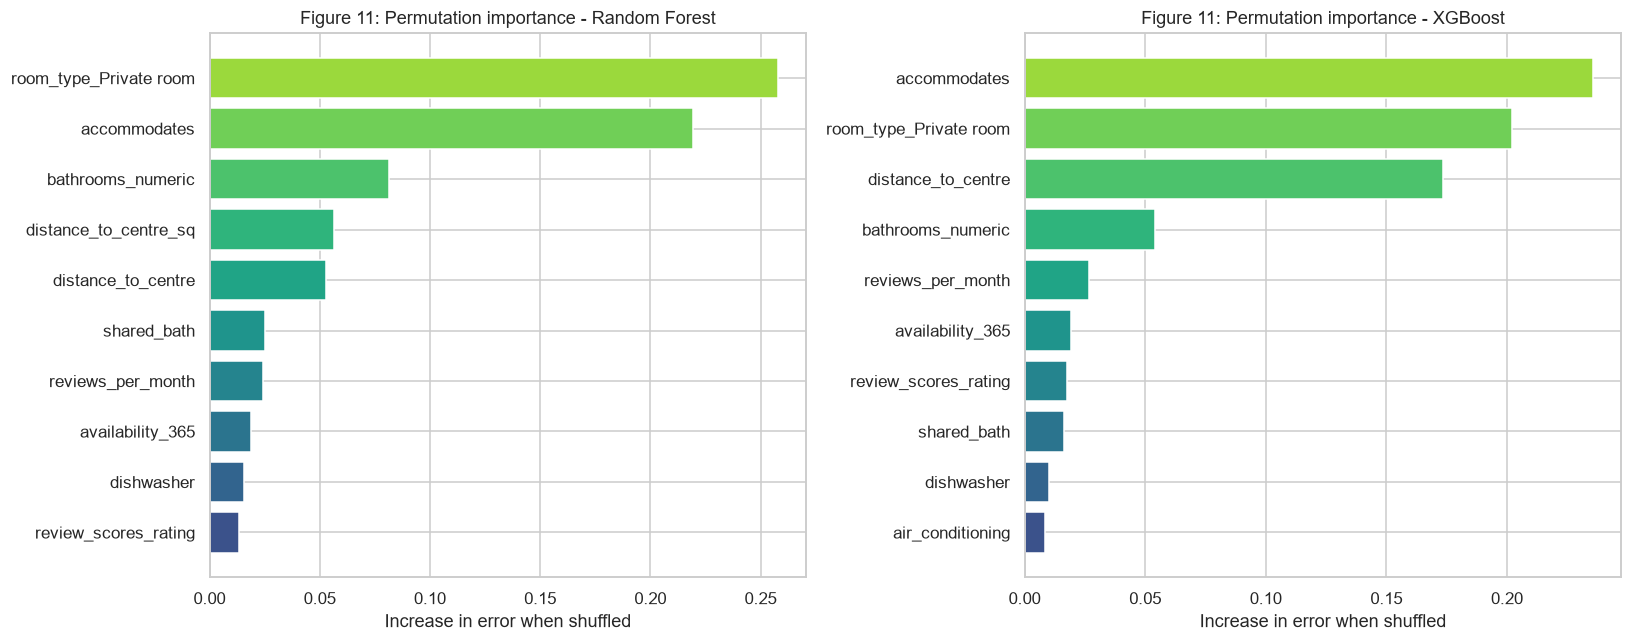

XGBoost achieves 12.5% lower RMSE than OLS but yields no
ceteris-paribus coefficients, standard errors or hypothesis tests. The trade-off
between accuracy and explainability is what motivates the dual design.


In [73]:
# Permutation importance is model-agnostic and measures the actual drop in test
# performance when a feature is shuffled; tree impurity importance is biased toward
# high-cardinality features.
header("feature importance")

perm_rf = permutation_importance(rf, X_test, ylog_test, n_repeats=5,
                                 random_state=RANDOM_SEED, n_jobs=1)
perm_gb = permutation_importance(gb, X_test, ylog_test, n_repeats=5,
                                 random_state=RANDOM_SEED, n_jobs=1)

imp_rf = pd.Series(perm_rf.importances_mean, index=X.columns).nlargest(10)
imp_gb = pd.Series(perm_gb.importances_mean, index=X.columns).nlargest(10)

# OLS terms are ranked by |t| rather than coefficient size, which is not comparable
# across variables measured in different units.
ols_rank = (final.pvalues[main_terms].to_frame("p")
            .assign(abs_t=final.tvalues[main_terms].abs())
            .sort_values("abs_t", ascending=False).head(10))

ols_list = [f"{t} ({'+' if final.params[t] > 0 else '-'})" for t in ols_rank.index]
n_rows = max(len(ols_list), len(imp_rf), len(imp_gb))
pad = lambda lst: list(lst) + [""] * (n_rows - len(lst))

side_by_side = pd.DataFrame({"OLS (by |t|)": pad(ols_list),
                             "Random Forest": pad(imp_rf.index.tolist()),
                             gb_name: pad(imp_gb.index.tolist())})
side_by_side.index = range(1, n_rows + 1)
display(side_by_side)

top_ols = {t.split("[T.")[0].replace("C(", "").replace(")", "") for t in ols_rank.index}
agree = [f for f in imp_rf.index if any(o in f for o in top_ols)]
print(f"\nIn both the OLS and Random Forest top 10: {agree}")
print("Agreement across two very different paradigms supports the hedonic interpretation;")
print("disagreement points to interactions that linear OLS cannot capture.")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, imp, title in [(axes[0], imp_rf, "Random Forest"), (axes[1], imp_gb, gb_name)]:
    order = imp.sort_values()
    ax.barh(order.index, order.values, color=plt.cm.viridis(np.linspace(0.25, 0.85, len(order))))
    ax.set(title=f"Figure 11: Permutation importance - {title}",
           xlabel="Increase in error when shuffled")

plt.savefig(OUT_DIR / "figure_11_feature_importance.png", bbox_inches="tight")
plt.show()

print(f"{best} achieves {improvement:.1f}% lower RMSE than OLS but yields no")
print("ceteris-paribus coefficients, standard errors or hypothesis tests. The trade-off")
print("between accuracy and explainability is what motivates the dual design.")

---
## 9. Summary and exports

In [74]:
# Correlation strengths mapped onto conventional bands.
header("correlation strength")

corr_targets = [c for c in numeric_vars if c not in ("price", "log_price")]
corr_price = df[corr_targets + ["log_price"]].corr()["log_price"].drop("log_price")


def band_of(r):
    """Map |r| onto conventional strength bands."""
    a = abs(r)
    return ("very weak" if a < 0.20 else "weak" if a < 0.40 else
            "moderate" if a < 0.60 else "strong" if a < 0.80 else "very strong")


corr_summary = pd.DataFrame({
    "r with log_price": corr_price,
    "strength": [band_of(r) for r in corr_price],
    "direction": ["positive" if r > 0 else "negative" for r in corr_price],
}).sort_values("r with log_price", key=abs, ascending=False)
display(corr_summary.round(4))

strongest = corr_summary.index[0]
print(f"""
The correlation matrix shows {strongest} with the strongest univariate association with
log price (r = {corr_price[strongest]:+.3f}, {band_of(corr_price[strongest])}). Across all
regressors, {(corr_price.abs() >= 0.40).sum()} reach at least a moderate association
(|r| >= 0.40) and {(corr_price.abs() < 0.20).sum()} are very weak. Capacity and locational
variables dominate the upper band while booking and reputation measures cluster in the
weaker bands, consistent with physical and locational attributes being the variables
most strongly associated with price. No pair of regressors exceeds |r| > 0.80.
""")


CORRELATION STRENGTH


,r with log_price,strength,direction
accommodates,0.6492,strong,positive
shared_bath,-0.5263,moderate,negative
dishwasher,0.3968,weak,positive
bathrooms_numeric,0.3839,weak,positive
distance_to_centre,-0.3669,weak,negative
amenities_count,0.3493,weak,positive
distance_to_centre_sq,-0.3039,weak,negative
air_conditioning,0.2596,weak,positive
distance_to_station,-0.2542,weak,negative
balcony_patio,0.1677,very weak,positive



The correlation matrix shows accommodates with the strongest univariate association with
log price (r = +0.649, strong). Across all
regressors, 2 reach at least a moderate association
(|r| >= 0.40) and 13 are very weak. Capacity and locational
variables dominate the upper band while booking and reputation measures cluster in the
weaker bands, consistent with physical and locational attributes being the variables
most strongly associated with price. No pair of regressors exceeds |r| > 0.80.



In [75]:
header("model specification notes")

n_boroughs = df["neighbourhood_cleansed"].nunique()
activity_removed = next((r["Rows Removed"] for r in sample_log
                         if "activity" in r["Stage"].lower()), 0)

print(f"""
Model 4 introduces borough fixed effects ({n_boroughs - 1} dummies across {n_boroughs}
boroughs, with {sorted(df['neighbourhood_cleansed'].unique())[0]} as the omitted baseline).
Fixed effects absorb all time-invariant borough characteristics - transport density,
perceived safety, prestige, local amenity provision - that are unobserved and would
otherwise be relegated to the error term, biasing the location coefficients. With these
included, distance_to_centre and distance_to_station are identified from variation within
boroughs and measure the marginal return to proximity conditional on borough, rather than
the raw geographic gradient. Adding them raises R-squared from {r2s[2]:.4f} to {r2s[3]:.4f}.

The hedonic regression follows a standard econometric framework and yields ceteris-paribus
coefficient interpretations. The machine-learning component addresses the separate
predictive question of whether non-linear models achieve lower out-of-sample error. It is
exploratory; the substantive findings rest on the hedonic specification, and no causal
claim is made on the basis of the machine-learning results.

The activity filter retained listings with a review within twelve months or non-zero
forward availability, removing {activity_removed:,} listings. The low count reflects
pipeline ordering: the preceding price-parsing step had already excluded
{len(dropped_price):,} listings which were overwhelmingly inactive or delisted. The filter
therefore functions as an explicit statement of the inclusion criterion rather than a
substantial cleaning step for this release.
""")


MODEL SPECIFICATION NOTES



Model 4 introduces borough fixed effects (32 dummies across 33
boroughs, with Barking and Dagenham as the omitted baseline).
Fixed effects absorb all time-invariant borough characteristics - transport density,
perceived safety, prestige, local amenity provision - that are unobserved and would
otherwise be relegated to the error term, biasing the location coefficients. With these
included, distance_to_centre and distance_to_station are identified from variation within
boroughs and measure the marginal return to proximity conditional on borough, rather than
the raw geographic gradient. Adding them raises R-squared from 0.7130 to 0.7290.

The hedonic regression follows a standard econometric framework and yields ceteris-paribus
coefficient interpretations. The machine-learning component addresses the separate
predictive question of whether non-linear models achieve lower out-of-sample error. It is
exploratory; the substantive findings rest on the hedonic specification, and no causal
clai

In [76]:
header("appendix exports")

exports = {}

exports["table_model4_full_coefficients.csv"] = pd.DataFrame({
    "Coefficient": final.params, "Robust SE (HC1)": final.bse,
    "t": final.tvalues, "p-value": final.pvalues,
    "CI low": final.conf_int()[0], "CI high": final.conf_int()[1],
    "% effect": [pct_effect(b) for b in final.params],
})
exports["table_model_comparison.csv"] = comparison
exports["table_block_decomposition.csv"] = decomp

# Verdicts derived from the fitted model so the appendix cannot disagree with the output.
HYPOTHESIS_MAP = [
    ("H1a", "accommodates", "+"), ("H1b", "bathrooms_numeric", "+"),
    ("H1c", "amenities_count", "+"), ("H1d", "air_conditioning", "+"),
    ("H1e", "C(room_type)[T.Private room]", "-"),
    ("H2a", "distance_to_centre", "-"), ("H2b", "distance_to_station", "-"),
    ("H2c", "distance_to_centre:accommodates", "-"),
    ("H3a", "superhost", "+"), ("H3b", "review_scores_rating", "+"),
    ("H3c", "ln_reviews", "-"), ("H3d", "host_tenure_years", "+"),
    ("H3e", "is_professional_host", "+"),
]

hyp_rows = []
for tag, term, expected in HYPOTHESIS_MAP:
    if term not in final.params.index:
        hyp_rows.append({"Hypothesis": tag, "Variable": term, "Expected": expected,
                         "Coefficient": None, "p-value": None, "% effect": None,
                         "Verdict": "Not testable"})
        continue
    b, p = final.params[term], final.pvalues[term]
    verdict_text = ("Not significant" if p >= 0.05 else
                    "Supported" if ((b > 0) == (expected == "+")) else "Contradicted")
    hyp_rows.append({"Hypothesis": tag, "Variable": term, "Expected": expected,
                     "Coefficient": round(b, 5), "p-value": f"{p:.3g}",
                     "% effect": round(pct_effect(b), 3), "Verdict": verdict_text})

hyp_rows.append({"Hypothesis": "H4", "Variable": f"{best} vs OLS", "Expected": "lower RMSE",
                 "Coefficient": round(ols_rmse - best_rmse, 3), "p-value": "bootstrap CI",
                 "% effect": round(improvement, 2),
                 "Verdict": "Supported" if gap_lo > 0 else "Not supported"})

exports["table_hypothesis_verdicts.csv"] = pd.DataFrame(hyp_rows)
exports["table_ml_performance.csv"] = ml_results
exports["table_ml_bootstrap_ci.csv"] = boot_table
exports["table_cold_start.csv"] = cold_results
exports["table_smearing_correction.csv"] = smear_table
exports["table_vif.csv"] = vif_table
exports["table_descriptives.csv"] = desc
exports["table_se_comparison.csv"] = se_compare
exports["table_robustness_checks.csv"] = pd.DataFrame({
    "Specification": list(variants.keys()),
    "N": [int(m.nobs) for m in variants.values()],
    "R-squared": [m.rsquared for m in variants.values()],
    "distance_to_centre": [m.params.get("distance_to_centre", np.nan) for m in variants.values()],
})

for filename, table in exports.items():
    table.to_csv(OUT_DIR / filename)
    print(f"  Saved -> outputs/{filename}")

display(exports["table_hypothesis_verdicts.csv"])


APPENDIX EXPORTS


  Saved -> outputs/table_model4_full_coefficients.csv
  Saved -> outputs/table_model_comparison.csv


  Saved -> outputs/table_block_decomposition.csv
  Saved -> outputs/table_hypothesis_verdicts.csv
  Saved -> outputs/table_ml_performance.csv
  Saved -> outputs/table_ml_bootstrap_ci.csv
  Saved -> outputs/table_cold_start.csv
  Saved -> outputs/table_smearing_correction.csv
  Saved -> outputs/table_vif.csv
  Saved -> outputs/table_descriptives.csv
  Saved -> outputs/table_se_comparison.csv
  Saved -> outputs/table_robustness_checks.csv


,Hypothesis,Variable,Expected,Coefficient,p-value,% effect,Verdict
0,H1a,accommodates,+,0.1201,1.45e-187,12.7620,Supported
1,H1b,bathrooms_numeric,+,0.1071,1.55e-47,11.3050,Supported
2,H1c,amenities_count,+,0.0019,3.33e-08,0.1850,Supported
3,H1d,air_conditioning,+,0.1832,3.14e-43,20.1060,Supported
4,H1e,C(room_type)[T.Private room],-,-0.4166,0,-34.0720,Supported
5,H2a,distance_to_centre,-,-0.0934,2.61e-123,-8.9210,Supported
6,H2b,distance_to_station,-,-0.0252,4.92e-07,-2.4910,Supported
7,H2c,distance_to_centre:accommodates,-,-0.0006,0.0167,-0.0600,Supported
8,H3a,superhost,+,0.0738,4.84e-20,7.6650,Supported
9,H3b,review_scores_rating,+,0.0722,2.07e-34,7.4840,Supported


In [77]:
header("summary of findings")

print(f"""
SAMPLE
  Raw snapshot        : {len(listings_raw):,} listings
  After cleaning      : {len(df_full):,}
  Regression sample   : {len(df):,}
  Source              : {LISTINGS_PATH.name} (Scrape ID {PROVENANCE.get('Scrape ID', 'n/a')})

WHAT IS ASSOCIATED WITH PRICE (hedonic OLS, SEs clustered by host)

  Model 4 explains {r2s[3] * 100:.1f}% of the variation in log price (adjusted
  {final.rsquared_adj * 100:.1f}%) across {int(final.nobs):,} listings.

    Property attributes alone : {r2s[0] * 100:5.1f}%
    + Location                : {r2s[1] * 100:5.1f}%  ({(r2s[1] - r2s[0]) * 100:+.1f} pp)
    + Reputation/host/booking : {r2s[2] * 100:5.1f}%  ({(r2s[2] - r2s[1]) * 100:+.1f} pp)
    + Borough fixed effects   : {r2s[3] * 100:5.1f}%  ({(r2s[3] - r2s[2]) * 100:+.1f} pp)

  H1: a private room is priced {abs(pct_effect(final.params.get('C(room_type)[T.Private room]', 0))):.1f}% below an entire home; each additional
      guest accommodated is associated with {pct_effect(final.params.get('accommodates', 0)):+.2f}%, each bathroom {pct_effect(final.params.get('bathrooms_numeric', 0)):+.2f}%,
      and air conditioning {pct_effect(final.params.get('air_conditioning', 0)):+.2f}%.
  H2: each km from the centre is associated with {pct_effect(final.params.get('distance_to_centre', 0)):+.2f}% and each km from
      the nearest station {pct_effect(final.params.get('distance_to_station', 0)):+.2f}%.
  H3: superhost {pct_effect(final.params.get('superhost', 0)):+.2f}%, review score {pct_effect(final.params.get('review_scores_rating', 0)):+.2f}% per point and host tenure
      {pct_effect(final.params.get('host_tenure_years', 0)):+.2f}% per year, but review volume {pct_effect(final.params.get('ln_reviews', 0)):+.2f}%. Professional hosts
      price {abs(pct_effect(final.params.get('is_professional_host', 0))):.2f}% {'below' if final.params.get('is_professional_host', 0) < 0 else 'above'} others, the opposite of the hypothesised sign.

DIAGNOSTICS
  Maximum VIF          : {max_structural:.2f} among substantive regressors
                         ({vif_table['VIF'].max():.2f} incl. distance and its square, which are
                         correlated by construction - see the centred re-parameterisation)
  Breusch-Pagan p      : {bp_p:.3g} ({'heteroskedastic; clustered SEs used throughout' if bp_p < 0.05 else 'homoskedastic'})
  Quadratic distance   : {'significant - gradient is non-linear' if q_p < 0.05 else 'not significant'}
  Cook's D > 1         : {n_severe} observations
  SE inflation from clustering by host: {se_compare['SE inflation'].median():.2f}x median

PREDICTION

  Out-of-sample performance on {len(X_test):,} held-out listings:
{ml_results.round(3).to_string()}

  Best: {best}, RMSE GBP {best_rmse:,.2f} against GBP {ols_rmse:,.2f} for OLS
  ({improvement:+.2f}%, bootstrap 95% CI [GBP {gap_lo:,.2f}, GBP {gap_hi:,.2f}]).
  H4 is {'supported' if gap_lo > 0 else 'not supported'}. Tree-based methods predict more accurately, but yield no
  ceteris-paribus coefficients, standard errors or hypothesis tests. OLS answers what an
  extra bedroom is worth; the tree models answer what a given listing will charge.

LIMITATIONS
  1. InsideAirbnb records asking prices, not transacted prices, so the findings describe
     listing behaviour rather than realised revenue.
  2. Cross-sectional and observational: every coefficient is an association conditional
     on the controls, not a causal effect. Unobserved quality (condition, view,
     photography) is absorbed into the error term. Reverse causation cannot be excluded
     either, since a host's pricing may itself shape reviews and occupancy.
  3. Distance to station uses {len(station_coords)} major stations rather than the full network,
     so that coefficient is attenuated toward zero.
  4. Winsorising means the results describe the central 98% of the market.
  5. Temporal robustness was not assessed - only one snapshot was available.
  6. Listwise deletion removed {lost:,} listings ({lost / n_pre_listwise * 100:.1f}%) from the regression sample.
  7. The room-type mix in the regression sample differs from the cleaned sample, so the
     two should not be read as describing an identical population.
""")


SUMMARY OF FINDINGS

SAMPLE
  Raw snapshot        : 92,638 listings
  After cleaning      : 58,583
  Regression sample   : 46,725
  Source              : listings.csv.gz (Scrape ID 20260619061251)

WHAT IS ASSOCIATED WITH PRICE (hedonic OLS, SEs clustered by host)

  Model 4 explains 72.9% of the variation in log price (adjusted
  72.9%) across 46,725 listings.

    Property attributes alone :  64.5%
    + Location                :  70.2%  (+5.7 pp)
    + Reputation/host/booking :  71.3%  (+1.1 pp)
    + Borough fixed effects   :  72.9%  (+1.6 pp)

  H1: a private room is priced 34.1% below an entire home; each additional
      guest accommodated is associated with +12.76%, each bathroom +11.30%,
      and air conditioning +20.11%.
  H2: each km from the centre is associated with -8.92% and each km from
      the nearest station -2.49%.
  H3: superhost +7.66%, review score +7.48% per point and host tenure
      +0.61% per year, but review volume -5.69%. Professional hosts
      price 

In [78]:
header("output manifest")

print("Figures:")
for p in sorted(OUT_DIR.glob("*.png")):
    print(f"  outputs/{p.name}")

print("\nTables:")
for p in sorted(OUT_DIR.glob("*.csv")):
    print(f"  outputs/{p.name}")

print("\nDatasets:")
for p in [CLEAN_PATH, ENGINEERED_PATH]:
    if p.exists():
        print(f"  {p.name}  ({p.stat().st_size / 1024**2:,.1f} MB)")

if SKIPPED:
    print(f"\nNot estimated: {', '.join(s['feature'] for s in SKIPPED)} "
          f"({SKIPPED[0]['reason']}).")


OUTPUT MANIFEST
Figures:
  outputs/figure_10_ml_performance.png
  outputs/figure_11_feature_importance.png
  outputs/figure_12_bootstrap_rmse.png
  outputs/figure_1_price_distributions.png
  outputs/figure_2_4_room_type.png
  outputs/figure_3_top_boroughs.png
  outputs/figure_5_correlation_heatmap.png
  outputs/figure_6_distance_vs_price.png
  outputs/figure_7_spatial.png
  outputs/figure_8_review_scores.png
  outputs/figure_9_diagnostics.png

Tables:
  outputs/table_block_decomposition.csv
  outputs/table_cold_start.csv
  outputs/table_descriptives.csv
  outputs/table_effect_sizes_pounds.csv
  outputs/table_hypothesis_verdicts.csv
  outputs/table_ml_bootstrap_ci.csv
  outputs/table_ml_performance.csv
  outputs/table_model4_full_coefficients.csv
  outputs/table_model_comparison.csv
  outputs/table_robustness_checks.csv
  outputs/table_sample_composition_by_stage.csv
  outputs/table_se_comparison.csv
  outputs/table_smearing_correction.csv
  outputs/table_vif.csv

Datasets:
  listings_